# Análisis exploratorio de datos — precio de bolsa del mercado eléctrico colombiano

Etapa de **comprensión de los datos** del trabajo integrador.

## Qué decide este notebook

| Pregunta | Dónde se responde | Qué depende de la respuesta |
|---|---|---|
| ¿La serie necesita diferenciarse? | §3, pruebas ADF y KPSS | el orden `d` del SARIMAX |
| ¿En qué escala hay que modelar? | §3.4, dispersión frente a nivel | la transformación logarítmica |
| ¿Hay estacionalidad, y de qué periodo? | §3.3 y §4 | el componente estacional `s` |
| ¿Cuántos rezagos tiene memoria la serie? | §4, ACF y PACF | los órdenes `p` y `q` |
| ¿La fase climática discrimina el precio? | §5.4 | la evaluación segmentada por fase ENSO |
| ¿Qué versión del índice ONI puede usarse? | §5.4 | evitar fuga de información |
| ¿Qué variables son redundantes entre sí? | §8, correlación y VIF | la poda previa a la selección |
| ¿Sirve la correlación para seleccionar? | §7, prueba de robustez | el criterio de selección de variables |

## Qué **no** hace

- **No selecciona variables.**
- **No modela la volatilidad.**
- **No elimina valores extremos.**

## Entradas y salidas

| | |
|---|---|
| **Entra** | `datasets/procesado/1_dataset_unificado.csv` — salida de `2_DataProcessing.ipynb` |
| **Sale** | `datasets/procesado/2_dataset_procesado.csv` — con los tres huecos imputados; es la entrada de `4_SeleccionVariables.ipynb` |

La §0 imputa tres variables con datos faltantes y es, por tanto, parte de la cadena, no un análisis: sin ella el notebook de selección no tiene entrada.

## 0. Limpieza e imputación de datos

In [1]:
# ============================================================
# Importación de librerías
# ============================================================
# pandas / numpy: manipulación de datos tabulares y arreglos numéricos.
# matplotlib / seaborn: visualización (series de tiempo, distribuciones, mapas de calor).
# statsmodels: pruebas de series de tiempo (ADF, ACF/PACF, descomposición) y VIF para
#              multicolinealidad.
# scipy.stats: spearmanr, correlación de rangos de Spearman — complemento a Pearson
#              (misma ficha), captura relaciones monótonas no necesariamente lineales
#              (ver sección 7, "Teoría").
import numpy as np
import datetime as dt
import pandas as pd
import pathlib
import os
import time
import seaborn as sns
import matplotlib.pyplot as plt
# os.chdir(pathlib.Path.cwd())

# Directorio de trabajo actual (carpeta donde vive este notebook).
# Todas las rutas del notebook (datasets/, etc.) se construyen a partir de esta.
abspath = pathlib.Path.cwd()
print(f"Directorio de trabajo: {abspath}")
###==========================
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import spearmanr

# "seaborn" se renombró a "seaborn-v0_8" en versiones recientes de matplotlib (>=3.6);
plt.style.use("seaborn-v0_8")
sns.set_palette("muted")

# --- Bloque específico de Google Colab (desactivado para ejecución local) ---
# Si se corre en Colab, se monta Google Drive para persistir/leer los datos
# y se cambia el directorio de trabajo a la carpeta del proyecto dentro de Drive.
# Conexión de google drive con el repo
#from google.colab import drive
#drive.mount('/content/drive')

###==========================
#ruta = os.path.join("/content/drive/MyDrive","MonografiaUdeA")
#ruta = os.path.join("C:/Users/Windows 10 Pro/OneDrive/Trabajo Integrador/Trabajo_Integrador_MAIN_PB")
#os.chdir(ruta)

# ============================================================
# La escala de pagina de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 14 pulgadas cabe ahi, pero ENCAJADA: todo su texto se reduce en la misma
# proporcion, y un cuerpo de 10 puntos acaba en 4,9 sobre el papel, que no se lee impreso.
# Dibujarla directamente al ancho de la pagina hace que cada punto tipografico sea un punto
# de verdad.
#
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en linea llama a print_figure
# con dpi=fig.dpi de forma explicita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporcion de la figura al llevarla al ancho de la pagina."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


Directorio de trabajo: C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB


In [2]:
# ============================================================
# Lectura del dataset consolidado (salida de 2_DataProcessing.ipynb)
# ============================================================
# df1 guarda una copia "cruda" (fecha aún en columna) — se usa más abajo
# (celda del heatmap general, antes del filtrado) para ver la matriz de
# correlación completa sin haber tocado nada todavía.
df = pd.read_csv(os.path.join(abspath,"datasets", "procesado", "1_dataset_unificado.csv"))
df1 = df.copy()
df.head(3)

,fecha,precio_bolsa,demanda,disp_dec_hidraulica,disp_dec_no_termica,disp_dec_termica,disponibilidad_declarada,gen_hidraulica,gen_no_termica,gen_termica,...,ipp_mineria_nivel,ipp_importados_nivel,ipp_general_nivel,ipp_mineria_variacion_interanual,ipp_importados_variacion_interanual,ipp_general_variacion_interanual,dia_semana,dia_mes,mes,tipo_dia
0,2010-01-01,120.501228,1.133616e+08,188034000.0,4778000.0,89259000.0,282071000.0,35796804.67,6020226.83,73602052.96,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,4,1,1,3
1,2010-01-02,118.495340,1.254718e+08,186794000.0,4778000.0,89274000.0,280846000.0,46595646.99,6050741.63,75034806.16,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,5,2,1,1
2,2010-01-03,121.160145,1.211452e+08,188274000.0,4778000.0,87810000.0,280862000.0,42578875.20,5702074.83,75356828.41,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,6,3,1,2


In [3]:
# fecha pasa a ser el índice de la serie (necesario para graficar series de
# tiempo directamente con .plot() y para el resample/rolling más adelante).
df = df.set_index('fecha')
df.index = pd.to_datetime(df.index)
df.describe()

,precio_bolsa,demanda,disp_dec_hidraulica,disp_dec_no_termica,disp_dec_termica,disponibilidad_declarada,gen_hidraulica,gen_no_termica,gen_termica,generacion,...,ipp_mineria_nivel,ipp_importados_nivel,ipp_general_nivel,ipp_mineria_variacion_interanual,ipp_importados_variacion_interanual,ipp_general_variacion_interanual,dia_semana,dia_mes,mes,tipo_dia
count,5964.000000,5.964000e+03,5.964000e+03,5.600000e+03,5.964000e+03,5.964000e+03,5.964000e+03,5.964000e+03,5.964000e+03,5.964000e+03,...,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000,5964.000000
mean,245.672872,1.887232e+08,2.222597e+08,4.815394e+06,1.000171e+08,3.267984e+08,1.447737e+08,5.178175e+06,4.074308e+07,1.906949e+08,...,136.440592,122.214391,126.619785,6.234247,3.353760,4.697135,3.000000,15.725520,6.441985,0.566063
std,241.852860,2.639000e+07,2.920008e+07,5.155392e+06,1.354771e+07,4.374227e+07,2.871796e+07,4.214262e+06,1.931437e+07,2.664130e+07,...,45.847857,26.680669,33.097080,19.688155,7.045348,5.859280,2.000168,8.798828,3.464221,0.903621
min,35.356673,1.133616e+08,1.327879e+08,0.000000e+00,5.250218e+07,2.200162e+08,3.579680e+07,8.549110e+05,1.197768e+07,1.154191e+08,...,85.550000,89.430000,89.520000,-40.824514,-10.341654,-2.957182,0.000000,1.000000,1.000000,0.000000
25%,111.484365,1.687671e+08,1.976237e+08,9.730800e+05,9.087169e+07,2.890844e+08,1.259018e+08,3.014849e+06,2.584244e+07,1.706813e+08,...,98.740000,93.460000,97.250000,-6.121880,-0.904584,1.305903,1.000000,8.000000,3.000000,0.000000
50%,165.193721,1.866341e+08,2.222543e+08,3.333725e+06,1.009836e+08,3.283831e+08,1.421914e+08,3.555205e+06,3.563308e+07,1.883542e+08,...,115.150000,114.970000,113.430000,2.877025,1.828893,3.387405,3.000000,16.000000,6.000000,0.000000
75%,271.901654,2.071806e+08,2.445300e+08,5.349240e+06,1.092600e+08,3.577851e+08,1.664602e+08,4.513093e+06,5.129309e+07,2.087567e+08,...,175.067500,151.340000,161.882500,12.133977,6.592494,5.514626,5.000000,23.000000,9.000000,1.000000
max,2498.804070,2.512807e+08,2.984209e+08,2.378674e+07,1.347452e+08,4.487365e+08,2.156508e+08,2.613021e+07,1.197190e+08,2.554650e+08,...,259.350000,174.280000,189.540000,79.205143,22.747700,23.448126,6.000000,31.000000,12.000000,3.000000


In [4]:
# Diagnóstico de nulos antes de imputar. Con el dataset extendido (2010-2026)
# hay nulos en disp_dec_no_termica (364), precio_oferta (1) y vertimientos
# (2313). Cada uno se imputa en la celda siguiente con una técnica
# distinta, según la causa que lo origina.
df.isnull().sum()

precio_bolsa                              0
demanda                                   0
disp_dec_hidraulica                       0
disp_dec_no_termica                     364
disp_dec_termica                          0
disponibilidad_declarada                  0
gen_hidraulica                            0
gen_no_termica                            0
gen_termica                               0
generacion                                0
aportes_energia                           0
precio_oferta                             1
precio_escasez                            0
vol_util                                  0
indice_ONI                                0
indice_ONI_publicado                      0
vertimientos                           2313
ipc_nivel                                 0
ipc_variacion_interanual                  0
ipp_mineria_nivel                         0
ipp_importados_nivel                      0
ipp_general_nivel                         0
ipp_mineria_variacion_interanual

Imputación de nulos, indican que no hubo vertimientos en el sistema.

In [5]:
# ============================================================
# Imputación de los 3 nulos detectados en la celda anterior
# ============================================================
# Cada nulo se contrastó contra los datos crudos antes de decidir cómo imputarlo: no se
# aplica una regla genérica, porque las tres causas son distintas.
#
#   1) vertimientos              (2313 nulos) -> se imputa con 0
#   2) disp_dec_no_termica         (364 nulos) -> se imputa con 0
#   3) precio_oferta                 (1 nulo)  -> se imputa con el
#                                                  PROMEDIO de los días
#                                                  inmediatamente anterior
#                                                  y posterior
#
# ------------------------------------------------------------------
# 1) vertimientos -> imputación con 0
# ------------------------------------------------------------------
# Un día sin fila en el crudo (VertEner.csv) se interpreta como "no hubo
# vertimiento ese día", no como un dato realmente faltante — por eso se
# rellena con 0 y no con ninguna forma de interpolación/promedio.
df['vertimientos'] = df['vertimientos'].fillna(0)

# ------------------------------------------------------------------
# 2) disp_dec_no_termica -> imputación con 0
# ------------------------------------------------------------------
# Se verificó con los datos reales (ej. el día 2013-06-15, dentro del rango
# de nulos 2011-06-17 a 2013-11-27) que ese día había 51 recursos
# reportando disponibilidad declarada, TODOS correctamente clasificados
# contra el catálogo de recursos (0 filas sin match) — pero NINGUNO de
# los 51 pertenecía a la categoría "NO TERMICA" (solar, eólica,
# cogenerador, etc.). Es decir: no falta el dato, es que esa categoría
# estuvo vacía ese día concreto (coherente con que la generación no
# térmica en Colombia era casi inexistente antes del despegue solar
# posterior a 2018). Cuando pd.pivot_table() no tiene ninguna fila para
# combinar (fecha, "NO TERMICA"), deja NaN en vez de 0 — por eso hay que
# rellenarlo explícitamente aquí, con la misma lógica que vertimientos:
# "sin recursos no térmicos reportando" equivale a "disponibilidad no
# térmica = 0" ese día.
df['disp_dec_no_termica'] = df['disp_dec_no_termica'].fillna(0)

# ------------------------------------------------------------------
# 3) precio_oferta -> imputación con el promedio de los días vecinos
# ------------------------------------------------------------------
# A diferencia de los dos casos anteriores, este SÍ es un hueco real de la
# fuente cruda: se verificó que datasets/PrecOferDesp.csv no tiene NINGUNA
# fila para el 2021-02-17 (0 registros ese día en el crudo), mientras que
# el 16 y el 18 de febrero de 2021 sí tienen datos completos. Es un hueco
# aislado de un solo día (probablemente XM no publicó el dato ese día
# puntual), no un patrón sistemático.
#
# precio_oferta tiene una tendencia fuerte a lo largo de 2010-2026 (ver
# la serie graficada más abajo en "Análisis univariado"), así que imputar
# con el PROMEDIO GLOBAL de toda la serie (ej. df['precio_oferta'].mean())
# introduciría un valor completamente fuera de contexto para ese punto
# temporal específico — un promedio de 16 años no representa el nivel de
# precios de febrero de 2021.
#
# En su lugar, se usa el PROMEDIO DE LOS VALORES INMEDIATAMENTE ANTERIOR
# Y POSTERIOR en la serie (16 y 18 de febrero de 2021) — equivalente a una
# interpolación lineal simple para un único punto faltante, que es la
# técnica estándar y más defendible para un hueco aislado de un solo día
# dentro de una serie con tendencia.
#
# Paso a paso:
#   a) Localizar la(s) fecha(s) con precio_oferta nulo.
#   b) Para cada una, tomar su posición dentro de la serie ORDENADA por
#      fecha (el índice df.index ya son fechas, ordenadas ascendentemente
#      desde 2_DataProcessing.ipynb).
#   c) Tomar el valor en la posición anterior (pos - 1) y en la posición
#      siguiente (pos + 1).
#   d) Promediar ambos valores y asignarlo a la fecha faltante.
#
# NOTA: este método asume que el nulo no está en la primera ni última fila
# de la serie (no aplicaría pos-1 o pos+1) — válido aquí porque se
# confirmó que es un único hueco aislado en medio de la serie (2021-02-17,
# muy lejos de los extremos 2010-01-01 y 2026-04-30).
idx_nulos_oferta = df.index[df['precio_oferta'].isna()]
print(f"Filas con precio_oferta nulo antes de imputar: {len(idx_nulos_oferta)}")

for fecha_nula in idx_nulos_oferta:
    posicion = df.index.get_loc(fecha_nula)
    valor_dia_anterior = df['precio_oferta'].iloc[posicion - 1]
    valor_dia_posterior = df['precio_oferta'].iloc[posicion + 1]
    promedio_vecinos = (valor_dia_anterior + valor_dia_posterior) / 2

    df.loc[fecha_nula, 'precio_oferta'] = promedio_vecinos

    print(
        f"  {fecha_nula.date()}: imputado con el promedio de "
        f"{valor_dia_anterior:.2f} COP/kWh (día anterior, "
        f"{df.index[posicion - 1].date()}) y "
        f"{valor_dia_posterior:.2f} COP/kWh (día posterior, "
        f"{df.index[posicion + 1].date()}) = {promedio_vecinos:.2f} COP/kWh"
    )

# Verificación final: las tres variables deben quedar en 0 nulos.
df.isnull().sum()

Filas con precio_oferta nulo antes de imputar: 1
  2021-02-17: imputado con el promedio de 293.18 COP/kWh (día anterior, 2021-02-16) y 288.86 COP/kWh (día posterior, 2021-02-18) = 291.02 COP/kWh


precio_bolsa                           0
demanda                                0
disp_dec_hidraulica                    0
disp_dec_no_termica                    0
disp_dec_termica                       0
disponibilidad_declarada               0
gen_hidraulica                         0
gen_no_termica                         0
gen_termica                            0
generacion                             0
aportes_energia                        0
precio_oferta                          0
precio_escasez                         0
vol_util                               0
indice_ONI                             0
indice_ONI_publicado                   0
vertimientos                           0
ipc_nivel                              0
ipc_variacion_interanual               0
ipp_mineria_nivel                      0
ipp_importados_nivel                   0
ipp_general_nivel                      0
ipp_mineria_variacion_interanual       0
ipp_importados_variacion_interanual    0
ipp_general_vari

In [6]:
# Guarda el dataset con las 3 variables imputadas (vertimientos,
# disp_dec_no_termica y precio_oferta) — ya sin nulos conocidos. Es la
# fuente que usa la celda de "Filtrado variables" más abajo (df_filtrado).
df.to_csv(os.path.join(abspath,"datasets", "procesado","2_dataset_procesado.csv"))
df.dtypes

precio_bolsa                           float64
demanda                                float64
disp_dec_hidraulica                    float64
disp_dec_no_termica                    float64
disp_dec_termica                       float64
disponibilidad_declarada               float64
gen_hidraulica                         float64
gen_no_termica                         float64
gen_termica                            float64
generacion                             float64
aportes_energia                        float64
precio_oferta                          float64
precio_escasez                         float64
vol_util                               float64
indice_ONI                             float64
indice_ONI_publicado                   float64
vertimientos                           float64
ipc_nivel                              float64
ipc_variacion_interanual               float64
ipp_mineria_nivel                      float64
ipp_importados_nivel                   float64
ipp_general_n

## 1. Carga y verificación de datos

In [7]:
# ============================================================
# Carga del dataset procesado
# ============================================================
# Se parte de "2_dataset_procesado.csv", la salida de la sección 0: el conjunto diario ya
# imputado, con las variables de calendario que construye 2_DataProcessing.ipynb.
abspath = pathlib.Path.cwd()
ruta_dataset = abspath / "datasets" / "procesado" / "2_dataset_procesado.csv"

df = pd.read_csv(ruta_dataset)
df["fecha"] = pd.to_datetime(df["fecha"])
df = df.set_index("fecha").sort_index()

# La versión publicada del ONI (indice_ONI_publicado) es la misma
# variable desplazada en el tiempo según su fecha de publicación, y se usa en la
# selección de variables y en el modelado. Este análisis describe las variables base con
# la versión centrada (indice_ONI), así que la publicada se excluye aquí: incluir las dos
# crearía un par redundante artificial en las correlaciones y en el VIF.
df = df.drop(columns=["indice_ONI_publicado"], errors="ignore")

# Variables de calendario: categóricas/cíclicas, no continuas. Se excluyen de TODOS los
# análisis que asumen relación lineal continua (Pearson, VIF) en las secciones 7 y 8,
# porque esos métodos suponen una relación lineal entre magnitudes continuas. Se analizan
# aparte, con diagramas de cajas, en la sección 5.
CALENDARIO_COLS = ["tipo_dia", "dia_semana", "dia_mes", "mes"]

print(f"Dataset cargado desde: {ruta_dataset}")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head(3)

Dataset cargado desde: C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB\datasets\procesado\2_dataset_procesado.csv
Dimensiones: 5964 filas x 28 columnas


,precio_bolsa,demanda,disp_dec_hidraulica,disp_dec_no_termica,disp_dec_termica,disponibilidad_declarada,gen_hidraulica,gen_no_termica,gen_termica,generacion,...,ipp_mineria_nivel,ipp_importados_nivel,ipp_general_nivel,ipp_mineria_variacion_interanual,ipp_importados_variacion_interanual,ipp_general_variacion_interanual,dia_semana,dia_mes,mes,tipo_dia
fecha,,,,,,,,,,,,,,,,,,,,,
2010-01-01,120.501228,1.133616e+08,188034000.0,4778000.0,89259000.0,282071000.0,35796804.67,6020226.83,73602052.96,1.154191e+08,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,4,1,1,3
2010-01-02,118.495340,1.254718e+08,186794000.0,4778000.0,89274000.0,280846000.0,46595646.99,6050741.63,75034806.16,1.276812e+08,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,5,2,1,1
2010-01-03,121.160145,1.211452e+08,188274000.0,4778000.0,87810000.0,280862000.0,42578875.20,5702074.83,75356828.41,1.236378e+08,...,97.28,91.08,89.52,23.15483,-5.733803,0.482658,6,3,1,2


In [8]:
# ============================================================
# Verificación de integridad: nulos, continuidad diaria y duplicados
# ============================================================
# Antes de asumir que el dataset está "limpio" (porque su nombre lo dice), se verifica
# explícitamente. Estas tres condiciones son importantes específicamente para el
# modelado de series de tiempo: un índice con huecos o fechas repetidas invalida tanto
# la descomposición estacional como el cálculo de ACF/PACF más adelante.
n_nulos = df.isnull().sum().sum()
n_duplicados = df.index.duplicated().sum()

rango_completo = pd.date_range(df.index.min(), df.index.max(), freq="D")
fechas_faltantes = rango_completo.difference(df.index)

print(f"Nulos totales en el dataset: {n_nulos}")
print(f"Fechas duplicadas en el índice: {n_duplicados}")
print(f"Fechas faltantes dentro del rango {df.index.min().date()} a {df.index.max().date()}: {len(fechas_faltantes)}")

assert n_nulos == 0, "Se esperaba un dataset ya imputado, sin nulos."
assert n_duplicados == 0, "El índice de fechas no debería tener duplicados."
assert len(fechas_faltantes) == 0, "La serie debería ser diaria y continua, sin huecos."

# Con la continuidad confirmada, se le asigna explícitamente la frecuencia diaria al
# índice. Esto lo necesitan internamente seasonal_decompose y plot_acf/plot_pacf.
df = df.asfreq("D")
df.info()

Nulos totales en el dataset: 0
Fechas duplicadas en el índice: 0
Fechas faltantes dentro del rango 2010-01-01 a 2026-04-30: 0
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5964 entries, 2010-01-01 to 2026-04-30
Freq: D
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   precio_bolsa                         5964 non-null   float64
 1   demanda                              5964 non-null   float64
 2   disp_dec_hidraulica                  5964 non-null   float64
 3   disp_dec_no_termica                  5964 non-null   float64
 4   disp_dec_termica                     5964 non-null   float64
 5   disponibilidad_declarada             5964 non-null   float64
 6   gen_hidraulica                       5964 non-null   float64
 7   gen_no_termica                       5964 non-null   float64
 8   gen_termica                          5964 non-null   float64
 9   generacion

**Resultado de la verificación** : el dataset no tiene nulos, no tiene fechas duplicadas y cubre el rango completo día por día sin huecos (los `assert` de la celda anterior lo confirman formalmente — si algo cambia en una corrida futura del pipeline, esta celda fallará….

### 1.1 Tipología y procedencia de las variables

Antes de describir cómo se comporta cada variable conviene dejar establecido **qué es cada una**: de dónde viene, en qué unidad está medida, con qué granularidad la publica su fuente y de qué tipo.

In [9]:
# ============================================================
# 1.1 — Tipología y procedencia de cada variable del conjunto consolidado
# ============================================================
# POR QUÉ ESTA TABLA. El resto del notebook describe cómo se COMPORTAN las variables; ninguna
# celda dice qué SON. Sin eso no se puede justificar por qué el calendario queda fuera de la
# matriz de correlación y del VIF, por qué dos variables se modelan en nivel y otras en variación,
# ni por qué el índice ONI aparece en dos versiones.
#
# DE DÓNDE SALE CADA COLUMNA DE LA TABLA:
#   unidad, granularidad   de metrics.csv, el catálogo de la API de XM, cruzado por MetricId
#   tipo, escala           DERIVADOS de los datos (integralidad, nº de valores distintos, cero)
#   familia, métrica, rol  declarados: son decisiones de 2_DataProcessing, y llevan assert
#
# Se lee el CSV consolidado y no `df`, porque la carga de la sección 1 descarta
# indice_ONI_publicado para no duplicar el ONI en las correlaciones. La tipología describe el
# conjunto tal como lo consumen los modelos, de modo que esa columna tiene que aparecer.
_cons = pd.read_csv(ruta_dataset, parse_dates=["fecha"]).set_index("fecha").sort_index()

# Catálogo de la API de XM. Una métrica aparece varias veces (una por entidad): se conserva la
# fila de la entidad que la extracción pidió, porque la granularidad depende de ella.
_cat = pd.read_csv(abspath / "metrics.csv")

# columna del conjunto -> (familia, nombre en prosa, MetricId y entidad de origen, rol)
# «rol» distingue la objetivo de las predictoras y de las variables auxiliares que el conjunto
# arrastra para construir otras cosas pero que no entran como predictoras por sí mismas.
DECL = {
    "precio_bolsa":    ("Precio",          "Precio de bolsa",              "PrecBolsNaci|Sistema",     "objetivo"),
    "precio_oferta":   ("Precio",          "Precio de oferta",             "PrecOferDesp|Recurso",     "predictora"),
    "precio_escasez":  ("Precio",          "Precio de escasez",            "PrecEscaAct|Sistema",      "predictora"),
    "demanda":         ("Demanda",         "Demanda",                      "DemaReal|Sistema",         "predictora"),
    "generacion":      ("Generación",      "Generación total",             "Gene|Recurso",             "predictora"),
    "gen_hidraulica":  ("Generación",      "Generación hidráulica",        "Gene|Recurso",             "predictora"),
    "gen_termica":     ("Generación",      "Generación térmica",           "Gene|Recurso",             "predictora"),
    "gen_no_termica":  ("Generación",      "Generación no térmica",        "Gene|Recurso",             "predictora"),
    "disponibilidad_declarada":  ("Disponibilidad", "Disponibilidad declarada",   "DispoDeclarada|Recurso", "predictora"),
    "disp_dec_hidraulica":       ("Disponibilidad", "Disp. declarada hidráulica", "DispoDeclarada|Recurso", "predictora"),
    "disp_dec_termica":          ("Disponibilidad", "Disp. declarada térmica",    "DispoDeclarada|Recurso", "predictora"),
    "disp_dec_no_termica":       ("Disponibilidad", "Disp. declarada no térmica", "DispoDeclarada|Recurso", "predictora"),
    "aportes_energia": ("Hidrología",      "Aportes de energía",           "AporEner|Sistema",         "predictora"),
    "vol_util":        ("Hidrología",      "Volumen útil de embalses",     "VoluUtilDiarEner|Sistema", "predictora"),
    "vertimientos":    ("Hidrología",      "Vertimientos",                 "VertEner|Sistema",         "predictora"),
    "indice_ONI":            ("Clima",     "Índice ONI (centrado)",        "NOAA|ONI",                 "auxiliar"),
    "indice_ONI_publicado":  ("Clima",     "Índice ONI (publicado)",       "NOAA|ONI",                 "predictora"),
    "ipc_nivel":                            ("Macroeconomía", "IPC (nivel)",                  "DANE|IPC", "predictora"),
    "ipc_variacion_interanual":             ("Macroeconomía", "IPC (var. interanual)",        "DANE|IPC", "predictora"),
    "ipp_general_nivel":                    ("Macroeconomía", "IPP general (nivel)",          "DANE|IPP", "predictora"),
    "ipp_general_variacion_interanual":     ("Macroeconomía", "IPP general (var. interanual)","DANE|IPP", "predictora"),
    "ipp_mineria_nivel":                    ("Macroeconomía", "IPP minería (nivel)",          "DANE|IPP", "predictora"),
    "ipp_mineria_variacion_interanual":     ("Macroeconomía", "IPP minería (var. interanual)","DANE|IPP", "predictora"),
    "ipp_importados_nivel":                 ("Macroeconomía", "IPP importados (nivel)",       "DANE|IPP", "predictora"),
    "ipp_importados_variacion_interanual":  ("Macroeconomía", "IPP importados (var. interanual)", "DANE|IPP", "predictora"),
    "dia_semana":      ("Calendario",      "Día de la semana",             "derivada|fecha",           "predictora"),
    "dia_mes":         ("Calendario",      "Día del mes",                  "derivada|fecha",           "predictora"),
    "mes":             ("Calendario",      "Mes del año",                  "derivada|fecha",           "predictora"),
    "tipo_dia":        ("Calendario",      "Tipo de día",                  "derivada|fecha",           "predictora"),
}
_sin_declarar = [c for c in _cons.columns if c not in DECL]
_sobran = [c for c in DECL if c not in _cons.columns]
assert not _sin_declarar, f"columnas del conjunto sin declarar: {_sin_declarar}"
assert not _sobran, f"declaradas y ausentes del conjunto: {_sobran}"


def _unidad_y_grano(origen, columna):
    """Unidad y granularidad de origen, leídas de metrics.csv por MetricId y entidad.

    Las series que no vienen de XM (NOAA, DANE, calendario) no están en ese catálogo y se
    resuelven aquí con la unidad de su propia fuente. OJO con el IPC y el IPP: de cada uno entran
    DOS columnas, el nivel del índice y su variación interanual, que NO comparten unidad. La
    primera versión de esta celda daba «índice» a las dos y dejaba en la tabla ocho unidades mal
    puestas, cuatro de ellas en columnas que están en porcentaje.
    """
    metrica, entidad = origen.split("|")
    if metrica == "NOAA":
        # El ONI es la anomalía de la temperatura superficial del mar en la región Niño 3.4,
        # medida en grados Celsius respecto de la media del periodo de referencia.
        return "anomalía en °C", "mensual"
    if metrica == "DANE":
        return ("%" if columna.endswith("_variacion_interanual") else "índice"), "mensual"
    if metrica == "derivada":
        return "código de categoría", "diaria"
    fila = _cat[(_cat["MetricId"] == metrica) & (_cat["Entity"] == entidad)]
    assert len(fila) == 1, f"{origen}: {len(fila)} filas en metrics.csv"
    grano = {"HourlyEntities": "horaria, agregada a diaria",
             "DailyEntities": "diaria"}[fila["Type"].iloc[0]]
    return fila["MetricUnits"].iloc[0], grano


def _tipo_y_escala(serie, familia, unidad):
    """Tipo y escala de medición.

    EL CRITERIO NO PUEDE SER «¿hay valores negativos en la muestra?», que fue el primer intento y
    estaba mal: la escala de medición es una propiedad de lo que la variable MIDE, no de lo que
    este periodo concreto resultó contener. Con aquella regla, la variación interanual del IPC
    salía de razón y la del IPP de intervalo, siendo la misma clase de magnitud, solo porque la
    inflación colombiana no fue negativa entre 2010 y 2026. El guard del final exige ahora que dos
    variables de la misma unidad no reciban escalas distintas, que es lo que habría cazado aquello.

    El criterio y por qué:
      - el tipo de día es NOMINAL: ordinario, sábado, domingo y festivo no se ordenan entre sí;
      - el día de la semana, el día del mes y el mes son CÍCLICOS, y esa es su escala. No son
        ordinales: tras el domingo viene el lunes y tras diciembre, enero, de modo que el orden
        numérico no es un orden de magnitud. Llamarlos ordinales contradiría la razón por la que
        quedan fuera de la correlación y del VIF;
      - el índice ONI es una ANOMALÍA, es decir una distancia respecto de una media de
        referencia. Su cero es esa referencia y no una ausencia de magnitud, de modo que un ONI
        de 2,0 no es «el doble» de uno de 1,0: es escala de INTERVALO;
      - todo lo demás está en escala de RAZÓN, porque su cero sí es ausencia de la magnitud:
        cero kilovatios hora, cero pesos por kilovatio hora, y una variación interanual del cero
        por ciento, que es exactamente «no varió».
    """
    if familia == "Calendario":
        if serie.name == "tipo_dia":
            return "categórica nominal", "nominal"
        return ("discreta cíclica" if serie.name == "dia_mes" else "categórica cíclica",
                "cíclica")
    return ("continua", "intervalo" if unidad.startswith("anomalía") else "razón")


_filas = []
for col in _cons.columns:
    familia, nombre, origen, rol = DECL[col]
    unidad, grano = _unidad_y_grano(origen, col)
    tipo, escala = _tipo_y_escala(_cons[col], familia, unidad)
    _filas.append({
        "variable": col, "nombre": nombre, "familia": familia,
        "fuente": {"NOAA": "NOAA", "DANE": "DANE", "derivada": "derivada"}.get(
            origen.split("|")[0], "XM"),
        "métrica de origen": origen.split("|")[0],
        "unidad": unidad, "granularidad de origen": grano,
        "tipo": tipo, "escala": escala, "rol": rol,
        "valores distintos": _cons[col].nunique(),
        "% ceros": round((_cons[col] == 0).mean() * 100, 1),
        "cobertura %": round(_cons[col].notna().mean() * 100, 1),
    })
META = pd.DataFrame(_filas).set_index("variable")
ORDEN_FAMILIAS = ["Precio", "Demanda", "Generación", "Disponibilidad", "Hidrología",
                  "Clima", "Macroeconomía", "Calendario"]
assert set(META["familia"]) == set(ORDEN_FAMILIAS), "familias declaradas y presentes no coinciden"
# Dos variables medidas en la misma unidad no pueden quedar en escalas distintas. Es el guard que
# habría cazado el fallo de clasificar la variación interanual según su signo observado.
# Solo se aplica a las CONTINUAS: el calendario comparte la etiqueta «código de categoría», que no
# es una unidad de medida sino la ausencia de una, y ahí conviven con razón lo cíclico y lo
# nominal. Comprobado a costa de un guard que saltaba por ese motivo y no por el que buscaba.
for _u, _g in META[META["tipo"] == "continua"].groupby("unidad"):
    assert _g["escala"].nunique() == 1, (
        "la unidad %r recibe escalas distintas: %s" % (_u, dict(_g["escala"].value_counts())))
META = META.loc[sorted(META.index, key=lambda c: (ORDEN_FAMILIAS.index(META.loc[c, "familia"]),
                                                  META.loc[c, "nombre"]))]

print(f"Conjunto consolidado: {len(_cons)} días x {_cons.shape[1]} variables, "
      f"de {_cons.index.min():%Y-%m-%d} a {_cons.index.max():%Y-%m-%d}\n")
display(META[["nombre", "familia", "fuente", "unidad", "granularidad de origen",
              "tipo", "escala", "rol"]])

print("Composición del conjunto:\n")
for fam in ORDEN_FAMILIAS:
    _f = META[META["familia"] == fam]
    print(f"  {fam:<16} {len(_f):>2} variable{'s' if len(_f) != 1 else ' '}   "
          f"({', '.join(sorted(_f['unidad'].unique()))})")
print()
print("Lo que esta tabla establece y el resto del notebook usa:\n")
_razon = (META["escala"] == "razón").sum()
_interv = (META["escala"] == "intervalo").sum()
_cat_n = (~META["tipo"].str.startswith("continua")).sum()
print(f"  · {_razon} variables en escala de razón, {_interv} en escala de intervalo y "
      f"{_cat_n} categóricas o cíclicas.")
print("    Las cuatro de calendario no entran en la matriz de correlación de la sección 7 ni en")
print("    el VIF de la sección 8: una correlación lineal contra el día de la semana no es")
print("    interpretable, porque sus valores no se ordenan por magnitud.")
_horaria = (META["granularidad de origen"] == "horaria, agregada a diaria").sum()
_mensual = (META["granularidad de origen"] == "mensual").sum()
print(f"  · {_horaria} series llegan horarias de XM y se agregan a diarias sumando las 24 horas;")
print(f"    {_mensual} se publican mensuales y se reparten al día. La granularidad de trabajo del")
print("    conjunto es diaria, pero no todas las variables tienen información diaria propia: el")
print("    ONI, el IPC y el IPP son escalonados, y por eso no aportan variación dentro del mes.")
# OJO: el cero solo es «ausencia de fenómeno» en las variables continuas. En el calendario es un
# CÓDIGO: tipo_dia = 0 es el día ordinario y dia_semana = 0 es el lunes, de modo que contarlos
# aquí diría que el 67 % de los días no hubo tipo de día. Por eso se filtra por tipo y no por
# el porcentaje.
_ceros = META.loc[(META["% ceros"] > 0) & (META["tipo"] == "continua"),
                  ["nombre", "% ceros"]].sort_values("% ceros", ascending=False)
print(f"  · {len(_ceros)} variables continuas tienen ceros estructurales, que son ausencia de")
print("    fenómeno y no dato faltante:")
for v, r in _ceros.iterrows():
    print(f"      {r['nombre']}: {r['% ceros']:.1f} % de los días")
print("    En el calendario el cero es un código, no una ausencia: tipo_dia = 0 es el día")
print("    ordinario y dia_semana = 0 es el lunes.")
assert (META["cobertura %"] == 100).all(), "hay columnas con huecos tras la imputación"
print("  · Cobertura del 100 % en las", len(META), "columnas: no quedan huecos tras la")
print("    imputación de la sección 0.")


Conjunto consolidado: 5964 días x 29 variables, de 2010-01-01 a 2026-04-30



,nombre,familia,fuente,unidad,granularidad de origen,tipo,escala,rol
variable,,,,,,,,
precio_bolsa,Precio de bolsa,Precio,XM,COP/kWh,"horaria, agregada a diaria",continua,razón,objetivo
precio_escasez,Precio de escasez,Precio,XM,COP/kWh,diaria,continua,razón,predictora
precio_oferta,Precio de oferta,Precio,XM,COP/kWh,"horaria, agregada a diaria",continua,razón,predictora
demanda,Demanda,Demanda,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora
gen_hidraulica,Generación hidráulica,Generación,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora
gen_no_termica,Generación no térmica,Generación,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora
generacion,Generación total,Generación,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora
gen_termica,Generación térmica,Generación,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora
disp_dec_hidraulica,Disp. declarada hidráulica,Disponibilidad,XM,kWh,"horaria, agregada a diaria",continua,razón,predictora


Composición del conjunto:

  Precio            3 variables   (COP/kWh)
  Demanda           1 variable    (kWh)
  Generación        4 variables   (kWh)
  Disponibilidad    4 variables   (kWh)
  Hidrología        3 variables   (kWh)
  Clima             2 variables   (anomalía en °C)
  Macroeconomía     8 variables   (%, índice)
  Calendario        4 variables   (código de categoría)

Lo que esta tabla establece y el resto del notebook usa:

  · 23 variables en escala de razón, 2 en escala de intervalo y 4 categóricas o cíclicas.
    Las cuatro de calendario no entran en la matriz de correlación de la sección 7 ni en
    el VIF de la sección 8: una correlación lineal contra el día de la semana no es
    interpretable, porque sus valores no se ordenan por magnitud.
  · 11 series llegan horarias de XM y se agregan a diarias sumando las 24 horas;
    10 se publican mensuales y se reparten al día. La granularidad de trabajo del
    conjunto es diaria, pero no todas las variables tienen inform

## 2. Variable objetivo: `precio_bolsa`

Antes de mirar ninguna variable explicativa, se caracteriza a fondo la serie que se quiere pronosticar: su distribución, su dispersión y su comportamiento en el tiempo.

In [10]:
# ============================================================
# Estadística descriptiva de precio_bolsa
# ============================================================
# Además de .describe() (media, desviación, cuartiles), se calculan skewness (asimetría)
# y kurtosis: los precios de energía suelen tener una distribución con cola larga hacia
# la derecha (pocos días con precios extremadamente altos por escasez/El Niño), lo cual
# .describe() por sí solo no deja tan explícito.
resumen = df["precio_bolsa"].describe()
asimetria = df["precio_bolsa"].skew()
curtosis = df["precio_bolsa"].kurt()

print(resumen)
print(f"\nAsimetría (skewness): {asimetria:.3f}")
print(f"Curtosis (kurtosis):  {curtosis:.3f}")

count    5964.000000
mean      245.672872
std       241.852860
min        35.356673
25%       111.484365
50%       165.193721
75%       271.901654
max      2498.804070
Name: precio_bolsa, dtype: float64

Asimetría (skewness): 3.263
Curtosis (kurtosis):  15.924


### Serie de tiempo completa

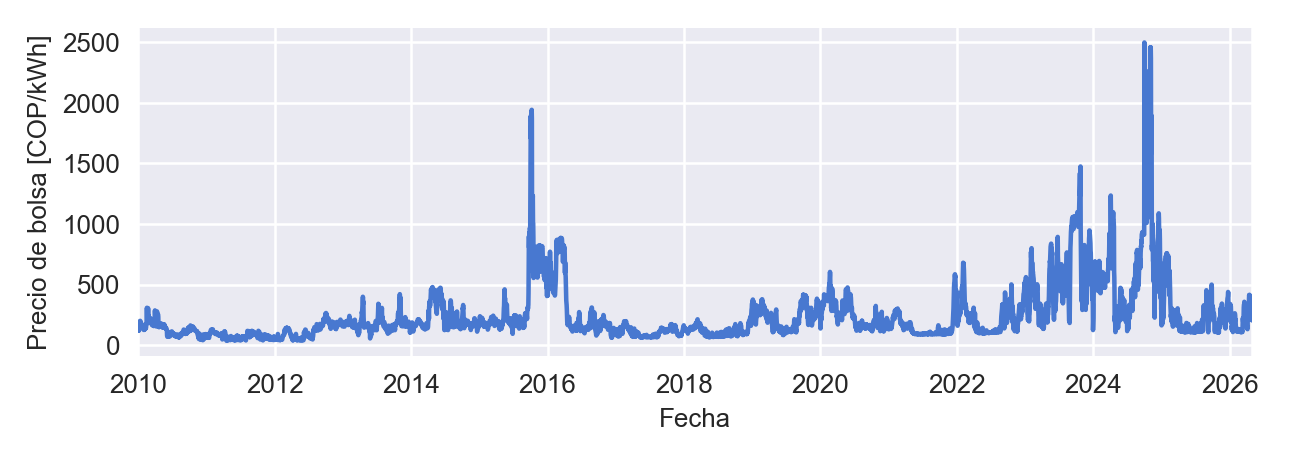

In [11]:
# ============================================================
# Serie completa del precio de bolsa (todo el rango del dataset)
# ============================================================
plt.figure(figsize=(ANCHO_PAGINA, alto_pagina(14, 5)))
df["precio_bolsa"].plot()
plt.xlabel("Fecha")
plt.ylabel("Precio de bolsa [COP/kWh]")
a_escala(plt.gcf())
plt.tight_layout()
plt.show()

### Distribución y valores atípicos

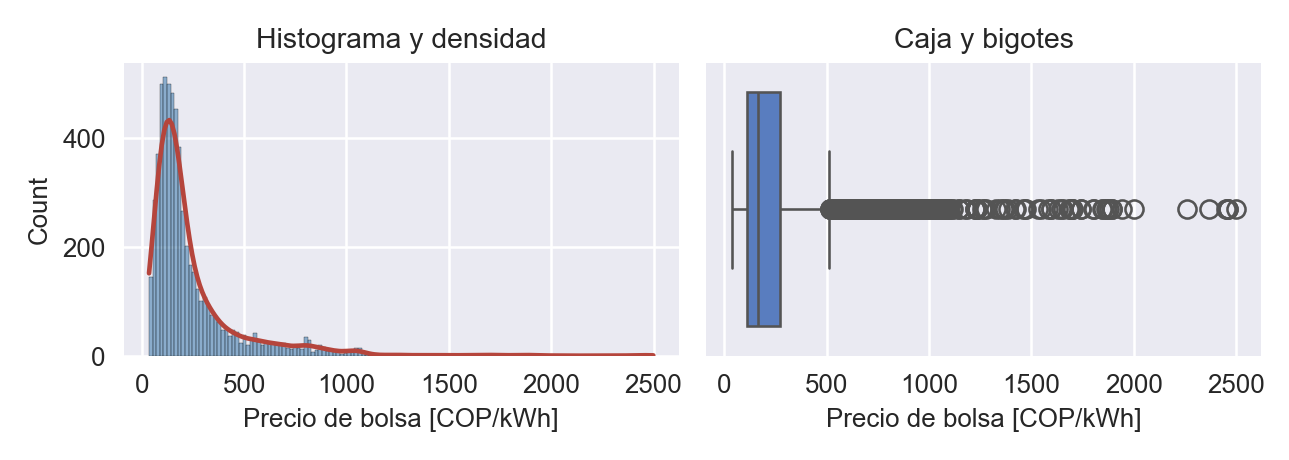

Límites IQR (1.5x): [-129.14, 512.53] COP/kWh
Días considerados atípicos por la regla IQR: 621 de 5964 (10.4%)


In [12]:
# ============================================================
# Distribución de precio_bolsa: histograma+KDE y diagrama de cajas
# ============================================================
# Se muestran lado a lado para leer distribución y outliers en una sola vista. El límite
# de outliers se calcula con la regla estándar del rango intercuartílico (IQR): un valor
# es atípico si cae fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR].
fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(14, 5)))

# La curva de densidad va en rojo y las barras en azul: con el color por omisión seaborn
# dibuja las dos en el mismo azul y la curva se pierde sobre las barras.
sns.histplot(df["precio_bolsa"], kde=True, ax=axes[0], color="#2c6fa8")
# El color de la curva se fija SOBRE la linea ya dibujada y no con `line_kws`, porque en
# esta version de seaborn el argumento `color` se impone sobre el de la linea y la curva
# sale del mismo azul que las barras. La KDE es la unica Line2D de estos ejes.
assert len(axes[0].lines) == 1, "se esperaba solo la curva de densidad"
axes[0].lines[0].set_color("#b5453c")
axes[0].lines[0].set_linewidth(1.8)
axes[0].set_title("Histograma y densidad")
axes[0].set_xlabel("Precio de bolsa [COP/kWh]")

sns.boxplot(x=df["precio_bolsa"], ax=axes[1])
axes[1].set_title("Caja y bigotes")
axes[1].set_xlabel("Precio de bolsa [COP/kWh]")

a_escala(fig)
plt.tight_layout()
plt.show()

q1, q3 = df["precio_bolsa"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers = df[(df["precio_bolsa"] < limite_inferior) | (df["precio_bolsa"] > limite_superior)]

print(f"Límites IQR (1.5x): [{limite_inferior:.2f}, {limite_superior:.2f}] COP/kWh")
print(f"Días considerados atípicos por la regla IQR: {len(outliers)} de {len(df)} ({len(outliers)/len(df)*100:.1f}%)")

**Lectura de la distribución** : la asimetría positiva y la curtosis alta confirman numéricamente lo que ya sugiere el histograma — una cola derecha pesada de días con precios muy altos.

## 3. Estacionariedad, descomposición y escala

Antes de especificar cualquier modelo de pronóstico hace falta saber tres cosas de la serie: si es **estacionaria** —si su media y su varianza se mantienen estables—, qué tamaño tiene su componente **estacional** frente a la tendencia, y en qué **escala** conviene….

In [13]:
# ============================================================
# Prueba de Dickey-Fuller aumentada (ADF) sobre precio_bolsa
# ============================================================
# H0: la serie tiene una raíz unitaria (NO es estacionaria).
# H1: la serie es estacionaria.
# Es el diagnóstico estándar antes de usar modelos tipo SARIMAX, que asumen (o
# requieren diferenciar hasta lograr) estacionariedad en media y varianza.
#
# QUÉ SELECCIONA EL CRITERIO DE AKAIKE, Y POR QUÉ SE IMPRIME. `autolag="AIC"` no es un detalle
# de implementación: el ADF contrasta la raíz unitaria sobre una regresión que incluye k
# diferencias rezagadas, y k lo elige el criterio minimizando el AIC entre 0 y un máximo que
# depende del tamaño de la muestra. Ese k es parte del resultado de la prueba —dice cuánta
# estructura de corto plazo hubo que absorber para que el residuo quedara limpio— y sin él la
# especificación no queda documentada. `adfuller` lo devuelve en la tercera posición, y en la
# cuarta el número de observaciones que quedan tras perder las k diferencias y el nivel inicial.
resultado_adf = adfuller(df["precio_bolsa"], autolag="AIC")

print(f"Estadístico ADF: {resultado_adf[0]:.4f}")
print(f"p-value:         {resultado_adf[1]:.4f}")
print(f"Rezagos elegidos por AIC: {resultado_adf[2]}")
print(f"Observaciones usadas:     {resultado_adf[3]}  "
      f"(de {len(df)} días; se pierden {len(df) - resultado_adf[3]})")
print("Valores críticos:")
for nivel, valor in resultado_adf[4].items():
    print(f"  {nivel}: {valor:.4f}")

if resultado_adf[1] < 0.05:
    print("\nConclusión: se rechaza H0 (p < 0.05) -> la serie es estacionaria en nivel.")
else:
    print("\nConclusión: no se rechaza H0 (p >= 0.05) -> la serie NO es estacionaria en nivel.")

Estadístico ADF: -4.9627
p-value:         0.0000
Rezagos elegidos por AIC: 34
Observaciones usadas:     5929  (de 5964 días; se pierden 35)
Valores críticos:
  1%: -3.4315
  5%: -2.8620
  10%: -2.5670

Conclusión: se rechaza H0 (p < 0.05) -> la serie es estacionaria en nivel.


**Lectura de la prueba ADF** : con un p-value prácticamente en cero y un estadístico ADF más negativo que los tres valores críticos (1%, 5% y 10%), se rechaza la hipótesis nula de raíz unitaria: **la serie es estacionaria en nivel**.

### Prueba KPSS (complemento a ADF)

**Motivación** : la propuesta del trabajo integrador (Fase 2, "Comprensión de los datos") compromete explícitamente el uso de "pruebas de estacionariedad como la prueba de Dickey-Fuller Aumentada (ADF)...

- **ADF** : H0 = la serie tiene raíz unitaria (NO es estacionaria).
- **KPSS** : H0 = la serie **es** estacionaria (alrededor de un nivel constante, si se usa `regression="c"` — la misma especificación que ADF, sin término de tendencia).

| ADF | KPSS | Conclusión |
|---|---|---|
| Rechaza H0 (estacionaria) | No rechaza H0 (estacionaria) | **Estacionaria** — ambas coinciden, evidencia fuerte |
| No rechaza H0 (no estacionaria) | Rechaza H0 (no estacionaria) | **No estacionaria** — ambas coinciden, evidencia fuerte |
| Rechaza H0 (estacionaria) | Rechaza H0 (no estacionaria) | Contradicción — típico de series con tendencia determinística fuerte; sugiere evaluar estacionariedad alrededor de una tendencia (`regression="ct"`) en vez de un nivel constante |
| No rechaza H0 (no estacionaria) | No rechaza H0 (estacionaria) | Contradicción — evidencia insuficiente en ambas direcciones |

In [14]:
# ============================================================
# Prueba KPSS sobre precio_bolsa (regression="c", igual especificación que ADF)
# ============================================================
# H0: la serie es estacionaria alrededor de un nivel constante.
# H1: la serie tiene raíz unitaria (no es estacionaria).
# nlags="auto" selecciona el número de rezagos igual que autolag="AIC" en adfuller
# (mismo criterio de selección automática, consistente con la celda de ADF de arriba).
from statsmodels.tsa.stattools import kpss

# kpss emite un UserWarning cuando el p-value cae fuera del rango de la tabla de
# valores críticos interpolados (p < 0.01 o p > 0.1) y lo trunca al límite más
# cercano — es un aviso esperado, no un error; se captura para no interrumpir la salida.
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    stat_kpss, pvalue_kpss, lags_kpss, crit_kpss = kpss(df["precio_bolsa"], regression="c", nlags="auto")
    if w:
        print(f"(Aviso de statsmodels: {w[0].message})\n")

print(f"Estadístico KPSS: {stat_kpss:.4f}")
print(f"p-value:          {pvalue_kpss:.4f}")
print(f"Rezagos usados:   {lags_kpss}")
print("Valores críticos:")
for nivel, valor in crit_kpss.items():
    print(f"  {nivel}: {valor:.4f}")

if pvalue_kpss < 0.05:
    print("\nConclusión: se rechaza H0 (p < 0.05) -> la serie NO es estacionaria (KPSS).")
else:
    print("\nConclusión: no se rechaza H0 (p >= 0.05) -> la serie es estacionaria (KPSS).")

print(f"\nCruce ADF + KPSS: ADF concluyó ESTACIONARIA; KPSS concluyó "
      f"{'NO ESTACIONARIA' if pvalue_kpss < 0.05 else 'ESTACIONARIA'}.")

(Aviso de statsmodels: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.
)

Estadístico KPSS: 2.2942
p-value:          0.0100
Rezagos usados:   44
Valores críticos:
  10%: 0.3470
  5%: 0.4630
  2.5%: 0.5740
  1%: 0.7390

Conclusión: se rechaza H0 (p < 0.05) -> la serie NO es estacionaria (KPSS).

Cruce ADF + KPSS: ADF concluyó ESTACIONARIA; KPSS concluyó NO ESTACIONARIA.


**Lectura del cruce ADF + KPSS** : revisar el resultado impreso arriba contra la tabla de la celda de teoría.

In [15]:
# ============================================================
# KPSS de seguimiento: regression="ct" (estacionariedad alrededor de tendencia)
# ============================================================
# Se ejecuta porque el cruce ADF+KPSS de arriba dio resultados contradictorios.
# regression="ct" cambia la hipótesis nula a "la serie es estacionaria alrededor de
# una TENDENCIA determinística" (no de un nivel constante) — la especificación
# correcta cuando ya sabemos, por la serie completa (sección 2), que hay una
# tendencia de largo plazo real.
stat_kpss_ct, pvalue_kpss_ct, lags_kpss_ct, crit_kpss_ct = kpss(
    df["precio_bolsa"], regression="ct", nlags="auto"
)

print(f"Estadístico KPSS (ct): {stat_kpss_ct:.4f}")
print(f"p-value:               {pvalue_kpss_ct:.4f}")
print("Valores críticos:")
for nivel, valor in crit_kpss_ct.items():
    print(f"  {nivel}: {valor:.4f}")

if pvalue_kpss_ct < 0.05:
    print("\nConclusión: se rechaza H0 (p < 0.05) -> NO es estacionaria alrededor de una tendencia.")
else:
    print("\nConclusión: no se rechaza H0 (p >= 0.05) -> SÍ es estacionaria alrededor de una tendencia (trend-stationary).")

Estadístico KPSS (ct): 0.2804
p-value:               0.0100
Valores críticos:
  10%: 0.1190
  5%: 0.1460
  2.5%: 0.1760
  1%: 0.2160

Conclusión: se rechaza H0 (p < 0.05) -> NO es estacionaria alrededor de una tendencia.


C:\Users\Windows 10 Pro\AppData\Local\Temp\ipykernel_23144\3535207539.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat_kpss_ct, pvalue_kpss_ct, lags_kpss_ct, crit_kpss_ct = kpss(


**Lectura final de estacionariedad** : el resultado obtenido es el más concluyente de los tres posibles — KPSS con `regression="ct"` **también rechaza** la hipótesis nula (estadístico 0.28, muy por encima incluso del valor crítico al 1% de 0.216).

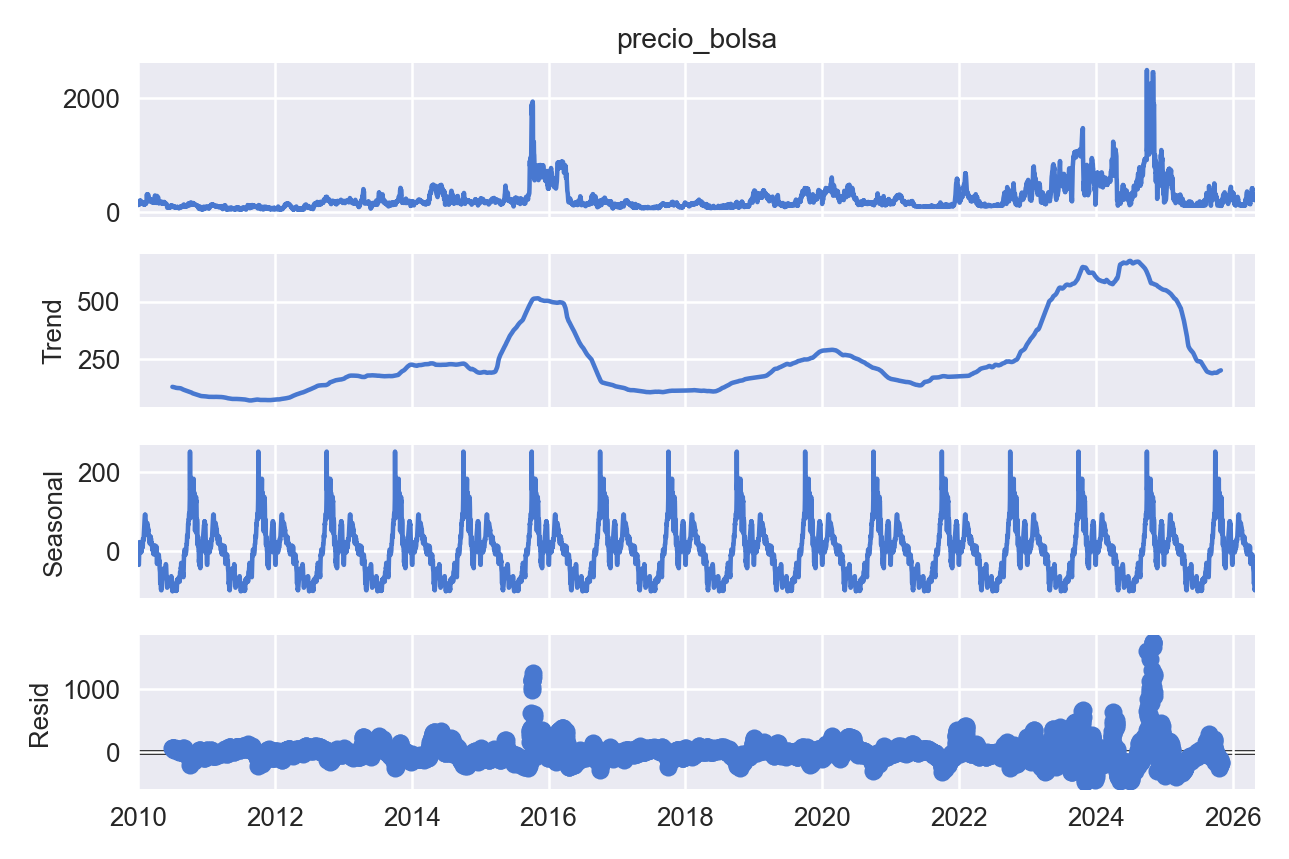

TENDENCIA — es una media móvil de 365 días, no un ajuste de tendencia
  cubre solo 2010-07-02 a 2025-10-30 (364 días sin valor: 182 a cada extremo)
  promedio por año:
    2010:   107  2011:    77  2012:   116  2013:   182  2014:   221  2015:   361  2016:   311  2017:   112  2018:   130  2019:   222  2020:   244  2021:   159  2022:   222  2023:   523  2024:   617  2025:   334

REPARTO DE LA VARIANZA (sobre el tramo sin NaN)
  tendencia    42.9 %
  estacional    7.5 %
  residuo      42.1 %

RESIDUO — su dispersión no es constante (esto es la heterocedasticidad)
  2010-2014: desv. est.    86.6   máximo   334.5
  2015-2016: desv. est.   193.7   máximo  1257.7
  2017-2021: desv. est.    81.6   máximo   352.5
  2022-2023: desv. est.   175.7   máximo   675.9
  2024-2024: desv. est.   408.5   máximo  1754.6
  2025-2026: desv. est.   145.0   máximo   281.6

¿ADITIVO O MULTIPLICATIVO?  corr(media móvil 30d, desv. móvil 30d) = 0.813
  La dispersión crece con el nivel: el comportamiento es MULTIP

In [16]:
# ============================================================
# Descomposición de la serie: tendencia, estacionalidad y residuo
# ============================================================
# QUÉ ES. seasonal_decompose parte la serie en tres piezas que suman exactamente el
# original:  serie = tendencia + estacionalidad + residuo.
#   · tendencia    = media móvil CENTRADA de 365 días (por eso pierde 182 días a cada
#                    extremo y el panel no cubre ni el principio ni el final de la serie)
#   · estacional   = promedio, para cada posición del año, de la serie ya sin tendencia
#   · residuo      = lo que queda
#
# POR QUÉ EL MÉTODO CLÁSICO Y NO STL. Para lo que se necesita aquí —saber si hay un patrón
# anual relevante y qué tamaño tiene frente al resto— el clásico basta y es más fácil de
# explicar. STL daría una estacionalidad que evoluciona con los años, que es información
# que este trabajo no usa: el horizonte es de 30 días.
#
# POR QUÉ period=365. El ciclo que interesa aquí es el ANUAL (temporadas de lluvia). La
# estacionalidad de calendario —mes, día de la semana, tipo de día— se analiza aparte y de
# forma más directa en la sección 5, y la semanal es la que acaba usando el SARIMAX.
descomposicion = seasonal_decompose(df["precio_bolsa"], model="additive", period=365)
T, S, R = descomposicion.trend, descomposicion.seasonal, descomposicion.resid

fig = descomposicion.plot()
fig.set_size_inches(ANCHO_PAGINA, alto_pagina(12, 8))
a_escala(fig)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Lo que el gráfico NO dice, y hay que medir
# ------------------------------------------------------------------
ok = T.notna() & R.notna()                      # tramo sin los NaN de la media móvil
print("TENDENCIA — es una media móvil de 365 días, no un ajuste de tendencia")
print(f"  cubre solo {T.dropna().index.min().date()} a {T.dropna().index.max().date()} "
      f"({int(T.isna().sum())} días sin valor: 182 a cada extremo)")
print("  promedio por año:")
print("   ", "  ".join(f"{a}:{T[T.index.year == a].mean():6.0f}"
                       for a in range(df.index.year.min(), df.index.year.max() + 1)
                       if T[T.index.year == a].notna().any()))

print("\nREPARTO DE LA VARIANZA (sobre el tramo sin NaN)")
for nombre, serie in [("tendencia", T), ("estacional", S), ("residuo", R)]:
    print(f"  {nombre:<11} {100 * serie[ok].var() / df['precio_bolsa'][ok].var():5.1f} %")

print("\nRESIDUO — su dispersión no es constante (esto es la heterocedasticidad)")
for ini, fin in [("2010", "2014"), ("2015", "2016"), ("2017", "2021"),
                 ("2022", "2023"), ("2024", "2024"), ("2025", "2026")]:
    tramo = R[ini:fin].dropna()
    if len(tramo):
        print(f"  {ini}-{fin}: desv. est. {tramo.std():7.1f}   máximo {tramo.max():7.1f}")

# ¿Aditivo o multiplicativo? Si la dispersión crece con el nivel, el aditivo es el modelo
# equivocado: aplicaría la misma amplitud estacional con el precio en 100 que en 2.000.
corr_nivel_disp = df["precio_bolsa"].rolling(30).mean().corr(df["precio_bolsa"].rolling(30).std())
print(f"\n¿ADITIVO O MULTIPLICATIVO?  corr(media móvil 30d, desv. móvil 30d) = {corr_nivel_disp:.3f}")
print("  La dispersión crece con el nivel: el comportamiento es MULTIPLICATIVO, y por eso")
print("  los modelos del trabajo que asumen varianza estable trabajan sobre el logaritmo.")

**Lectura de la descomposición.** Conviene leer este gráfico con tres precauciones, porque las tres cosas que parece decir a primera vista no son las que dice.

- La correlación entre el nivel local y la dispersión local es de ≈0,81: la serie se comporta de forma **multiplicativa**, no aditiva.
- Con un 7 % de la varianza y una amplitud real de ≈88 COP/kWh, la **estacionalidad anual no merece entrar en los modelos**.
- Lo que mueve esta serie está en el residuo y es de **régimen**, no de calendario.

Desviación del precio respecto de su tendencia, por mes [COP/kWh]:
     media (la del panel)  mediana  mediana sin episodios
ene                  16.2      8.6                    8.7
feb                  55.4     28.2                   35.4
mar                  12.2     12.1                    9.0
abr                 -31.8    -20.2                  -11.2
may                 -59.2    -44.1                  -39.8
jun                 -80.7    -49.6                  -39.8
jul                 -87.8    -63.4                  -52.1
ago                 -51.3    -46.7                  -39.3
sep                  36.4     -5.7                   -9.3
oct                 129.7     23.2                    5.0
nov                  24.9    -12.7                  -24.5
dic                  31.0     -5.2                   -8.5

  mes más alto según la media (lo que pinta el panel): oct
  mes más alto según la mediana robusta:               feb
  amplitud según la media:    217.5 COP/kWh
  amplitud robus

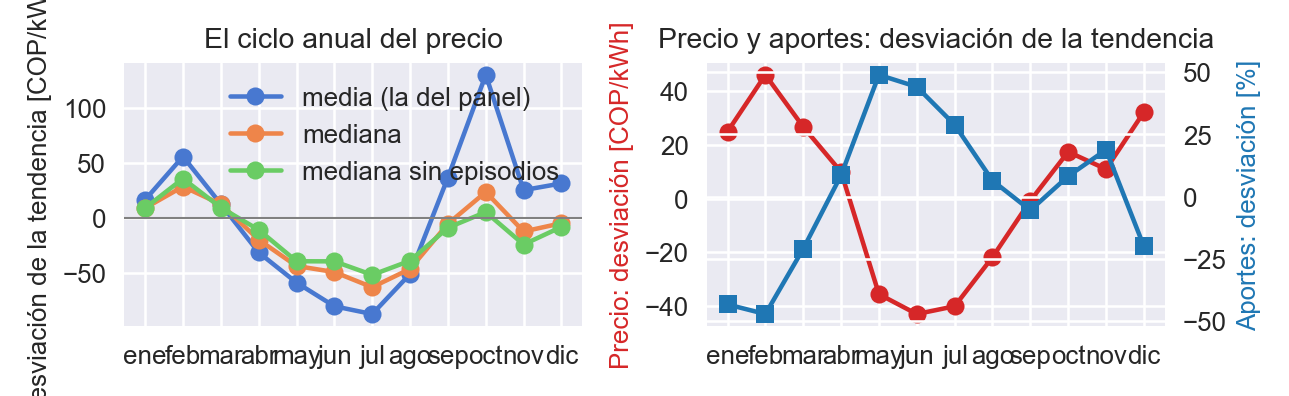

In [17]:
# ============================================================
# El ciclo anual, medido con un estimador robusto
# ============================================================
# POR QUÉ HACE FALTA. El panel "Seasonal" de arriba se calcula con un PROMEDIO sobre cada
# posición del año. Con 17 ciclos, cada día del año se estima con ~17 observaciones, así que
# un episodio extremo mueve ese promedio en una fracción grande. El Niño de 2015-16 y la
# crisis de 2023-24 culminaron en septiembre-octubre, y eso basta para que el panel sitúe
# ahí el máximo anual.
#
# La MEDIANA es insensible a esos extremos. Si el ciclo anual es real, debe sobrevivir a
# cambiar el promedio por la mediana y a excluir los años de episodio.
ANIOS_EPISODIO = [2015, 2016, 2023, 2024]
detrend = (df["precio_bolsa"] - T).dropna()                  # serie sin tendencia
sin_ep = detrend[~detrend.index.year.isin(ANIOS_EPISODIO)]

perfil = pd.DataFrame({
    "media (la del panel)": detrend.groupby(detrend.index.month).mean(),
    "mediana": detrend.groupby(detrend.index.month).median(),
    "mediana sin episodios": sin_ep.groupby(sin_ep.index.month).median()})
perfil.index = ["ene", "feb", "mar", "abr", "may", "jun",
                "jul", "ago", "sep", "oct", "nov", "dic"]
print("Desviación del precio respecto de su tendencia, por mes [COP/kWh]:")
print(perfil.round(1).to_string())
print(f"\n  mes más alto según la media (lo que pinta el panel): {perfil.iloc[:, 0].idxmax()}")
print(f"  mes más alto según la mediana robusta:               {perfil.iloc[:, 2].idxmax()}")
print(f"  amplitud según la media:   {perfil.iloc[:, 0].max() - perfil.iloc[:, 0].min():6.1f} COP/kWh")
print(f"  amplitud robusta:          {perfil.iloc[:, 2].max() - perfil.iloc[:, 2].min():6.1f} COP/kWh")

# ------------------------------------------------------------------
# ¿El ciclo robusto es hidrológico? Se contrasta contra aportes y embalses.
# ------------------------------------------------------------------
sin_ep_df = df[~df.index.year.isin(ANIOS_EPISODIO)]
hidro = pd.DataFrame({
    "precio (desv. de su mediana)": (sin_ep_df["precio_bolsa"].groupby(sin_ep_df.index.month).median()
                                     - sin_ep_df["precio_bolsa"].median()),
    "aportes (% de su mediana)": 100 * (sin_ep_df["aportes_energia"].groupby(sin_ep_df.index.month).median()
                                        / sin_ep_df["aportes_energia"].median() - 1),
    "vol_util (% de su mediana)": 100 * (sin_ep_df["vol_util"].groupby(sin_ep_df.index.month).median()
                                         / sin_ep_df["vol_util"].median() - 1)})
hidro.index = perfil.index
print("\nPerfil anual robusto frente a la hidrología:")
print(hidro.round(1).to_string())
print(f"\n  correlación entre los doce meses, precio vs aportes:   "
      f"{hidro.iloc[:, 0].corr(hidro.iloc[:, 1]):+.3f}")
print(f"  correlación entre los doce meses, precio vs vol_util:  "
      f"{hidro.iloc[:, 0].corr(hidro.iloc[:, 2]):+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
perfil.plot(ax=axes[0], marker="o")
axes[0].axhline(0, color="grey", lw=0.8)
# a la escala de la pagina el panel es la mitad de ancho y el reparto automatico se
# queda en tres meses; con este cuerpo de letra caben los doce
axes[0].set_xticks(range(len(perfil)))
axes[0].set_xticklabels(perfil.index)
axes[0].set_ylabel("Desviación de la tendencia [COP/kWh]")
axes[0].set_title("El ciclo anual del precio")
axes[0].legend(fontsize=10)
ax2 = axes[1]
ax2.plot(hidro.index, hidro.iloc[:, 0], marker="o", color="tab:red", label="precio")
ax2.set_ylabel("Precio: desviación [COP/kWh]", color="tab:red")
ax3 = ax2.twinx()
ax3.plot(hidro.index, hidro.iloc[:, 1], marker="s", color="tab:blue", label="aportes")
ax3.set_ylabel("Aportes: desviación [%]", color="tab:blue")
ax2.set_title("Precio y aportes: desviación de la tendencia")
a_escala(fig)
plt.tight_layout()
plt.show()

### 3.4 La varianza no es constante: en qué escala hay que modelar

La prueba ADF responde si la **media** de la serie es estacionaria.

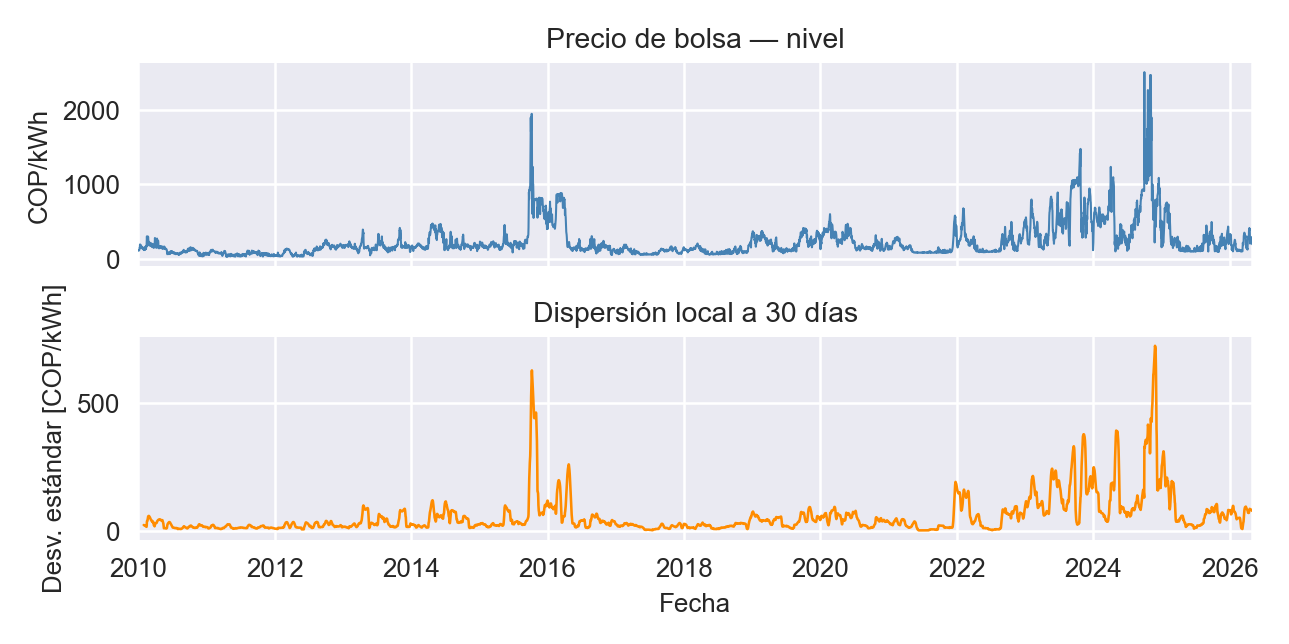

Correlación entre el nivel local y la dispersión local: 0.813
  La dispersión acompaña al nivel: el comportamiento es MULTIPLICATIVO.
  Consecuencia directa: los modelos de este trabajo ajustan el LOGARITMO del precio,
  no el precio. Sobre el logaritmo, una variación porcentual pesa lo mismo con el
  precio en 100 que en 2.000, que es el supuesto que la serie sí cumple.

Dispersión relativa al nivel, por fase ENSO:
         nivel mediano  dispersión mediana  coef. de variación
El Niño         261.27               52.93                0.20
Neutral         155.70               28.81                0.19
La Niña         121.96               19.70                0.16

El coeficiente de variación es casi el mismo en las tres fases (0.16 a 0.20).
La volatilidad es PROPORCIONAL al nivel, no un régimen de dificultad distinto. De ahí
que la evaluación segmentada por fase deba reportar también el error RELATIVO: el MAE
absoluto por fase mide, en buena parte, cuánto valía el precio en cada una.


In [18]:
# ============================================================
# 3.4 Dispersión local: ¿crece con el nivel del precio?
# ============================================================
# La ventana de 30 días (~1 mes) equilibra sensibilidad y estabilidad: ventanas de 5 a 7
# días producen una curva demasiado ruidosa para leerla.
volatilidad_rodante = df["precio_bolsa"].rolling(window=30).std()
nivel_rodante = df["precio_bolsa"].rolling(window=30).mean()

fig, axes = plt.subplots(2, 1, figsize=(ANCHO_PAGINA, alto_pagina(14, 7)), sharex=True)
df["precio_bolsa"].plot(ax=axes[0], color="steelblue", linewidth=0.8)
axes[0].set_title("Precio de bolsa — nivel")
axes[0].set_ylabel("COP/kWh")
volatilidad_rodante.plot(ax=axes[1], color="darkorange", linewidth=1)
axes[1].set_title("Dispersión local a 30 días")
axes[1].set_ylabel("Desv. estándar [COP/kWh]")
axes[1].set_xlabel("Fecha")
a_escala(fig)
plt.tight_layout()
plt.show()

# --- 1. ¿La dispersión crece con el nivel? Esta es la medición que decide la escala. ---
corr_nivel_disp = nivel_rodante.corr(volatilidad_rodante)
print(f"Correlación entre el nivel local y la dispersión local: {corr_nivel_disp:.3f}")
print("  La dispersión acompaña al nivel: el comportamiento es MULTIPLICATIVO.")
print("  Consecuencia directa: los modelos de este trabajo ajustan el LOGARITMO del precio,")
print("  no el precio. Sobre el logaritmo, una variación porcentual pesa lo mismo con el")
print("  precio en 100 que en 2.000, que es el supuesto que la serie sí cumple.")

# --- 2. ¿Es un régimen de dificultad aparte, o solo proporcionalidad? ---
# Importa para la evaluación segmentada: si el coeficiente de variación fuera muy distinto
# entre fases, El Niño sería intrínsecamente más difícil de pronosticar. Si es parecido, las
# diferencias de error entre fases miden sobre todo el NIVEL del precio.
fase_eda = np.select([df["indice_ONI"] >= 0.5, df["indice_ONI"] <= -0.5],
                     ["El Niño", "La Niña"], default="Neutral")
por_fase_vol = pd.DataFrame({
    "nivel mediano": df["precio_bolsa"].groupby(fase_eda).median(),
    "dispersión mediana": volatilidad_rodante.groupby(fase_eda).median()})
por_fase_vol["coef. de variación"] = (por_fase_vol["dispersión mediana"]
                                      / por_fase_vol["nivel mediano"])
por_fase_vol = por_fase_vol.reindex(["El Niño", "Neutral", "La Niña"])
print("\nDispersión relativa al nivel, por fase ENSO:")
print(por_fase_vol.round(2).to_string())
print(f"\nEl coeficiente de variación es casi el mismo en las tres fases "
      f"({por_fase_vol['coef. de variación'].min():.2f} a "
      f"{por_fase_vol['coef. de variación'].max():.2f}).")
print("La volatilidad es PROPORCIONAL al nivel, no un régimen de dificultad distinto. De ahí")
print("que la evaluación segmentada por fase deba reportar también el error RELATIVO: el MAE")
print("absoluto por fase mide, en buena parte, cuánto valía el precio en cada una.")

**Lectura.** La dispersión local no es constante: se dispara en 2015-2016 y en 2023-2024, los dos episodios de El Niño del periodo, y se aplana en los tramos de hidrología normal.

## 4. Autocorrelación (ACF y PACF)

El ACF mide qué tan correlacionado está el precio de un día con el de días anteriores; el PACF aísla esa correlación directa, sin el efecto que se transmite a través de los rezagos intermedios.

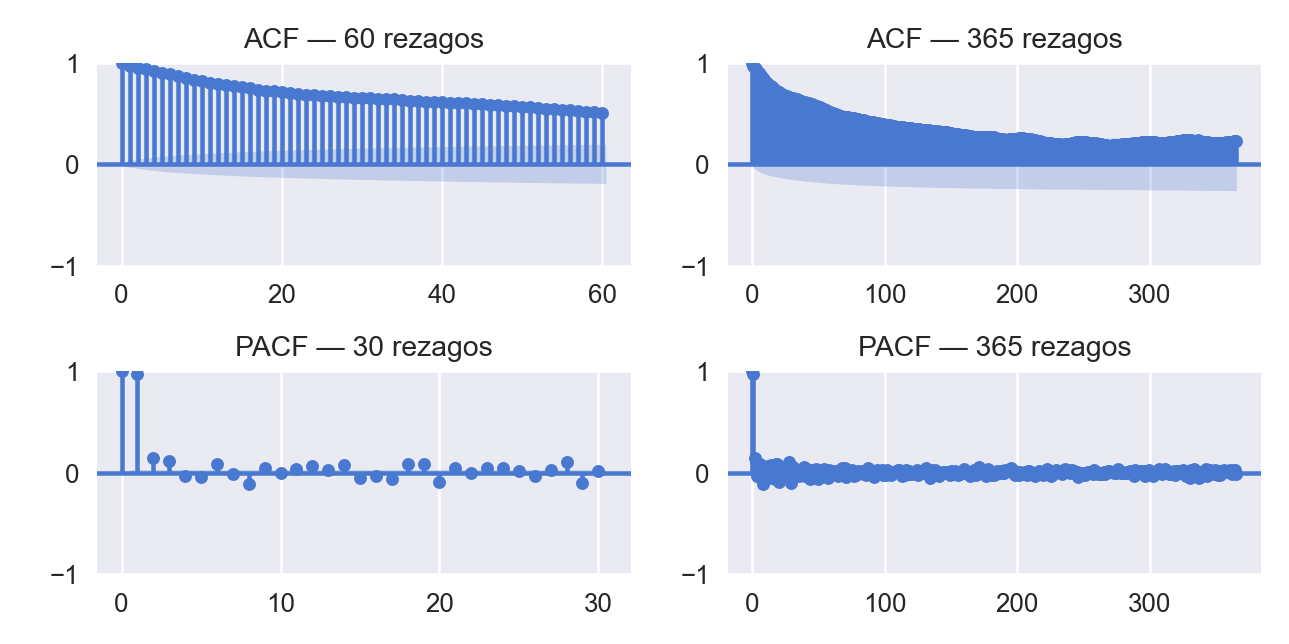

ACF  : rezago 1: 0.971  rezago 7: 0.872  rezago 30: 0.652  rezago 60: 0.507  rezago 200: 0.254  rezago 270: 0.184  rezago 365: 0.233
PACF : rezago 1: 0.972  rezago 2: 0.143  rezago 3: 0.114  rezago 7: -0.014  rezago 14: 0.077  rezago 30: 0.016

Banda de confianza al 95 % en el rezago 1: ±0.025
Con 5964 observaciones la banda es muy estrecha, de modo que muchos rezagos salen
«significativos» con magnitudes sin relevancia práctica: hay que mirar el tamaño, no solo
si el palo sale de la banda.


In [19]:
# ============================================================
# ACF y PACF de la serie en nivel: cuatro vistas en una figura
# ============================================================
# QUÉ SE BUSCA EN CADA PANEL
#   · ACF a 60 rezagos   — la forma del decaimiento. Rápido = estacionaria;
#                          lento y casi lineal = raíz unitaria o muy cerca.
#   · ACF a 365 rezagos  — ¿hay eco del ciclo anual? Se compara contra la banda de
#                          confianza, que se ENSANCHA con el rezago (banda de Bartlett).
#   · PACF a 30 rezagos  — cuántos términos autorregresivos hacen falta de verdad.
#   · PACF a 365 rezagos — si algún rezago lejano aporta por sí mismo.
#
# Las cuatro vistas estaban en cuatro celdas separadas; se juntan aquí porque se leen como
# un conjunto y porque la conclusión sale de compararlas entre sí.
fig, axes = plt.subplots(2, 2, figsize=(ANCHO_PAGINA, alto_pagina(14, 7)))
plot_acf(df["precio_bolsa"], lags=60, ax=axes[0, 0])
axes[0, 0].set_title("ACF — 60 rezagos")
plot_acf(df["precio_bolsa"], lags=365, ax=axes[0, 1])
axes[0, 1].set_title("ACF — 365 rezagos")
plot_pacf(df["precio_bolsa"], lags=30, ax=axes[1, 0])
axes[1, 0].set_title("PACF — 30 rezagos")
plot_pacf(df["precio_bolsa"], lags=365, ax=axes[1, 1])
axes[1, 1].set_title("PACF — 365 rezagos")
a_escala(fig)
plt.tight_layout()
plt.show()

# Los valores concretos que sostienen la lectura de abajo, en vez de leerlos del gráfico.
from statsmodels.tsa.stattools import acf as _acf, pacf as _pacf
_a = _acf(df["precio_bolsa"].dropna(), nlags=365)
_p = _pacf(df["precio_bolsa"].dropna(), nlags=30)
print("ACF  :", "  ".join(f"rezago {k}: {_a[k]:.3f}" for k in [1, 7, 30, 60, 200, 270, 365]))
print("PACF :", "  ".join(f"rezago {k}: {_p[k]:.3f}" for k in [1, 2, 3, 7, 14, 30]))
print(f"\nBanda de confianza al 95 % en el rezago 1: ±{1.96 / len(df) ** 0.5:.3f}")
print(f"Con {len(df)} observaciones la banda es muy estrecha, de modo que muchos rezagos salen")
print("«significativos» con magnitudes sin relevancia práctica: hay que mirar el tamaño, no solo")
print("si el palo sale de la banda.")

- **ACF — memoria muy larga**
- **PACF — un AR(1) casi integrado**
- **Significancia estadística ≠ relevancia práctica**
- **Horizonte anual (ACF y PACF con 365 rezagos)**

**Implicación** : sobre la serie en nivel, el ACF/PACF solo "ve" la raíz unitaria y no sirve para identificar los órdenes p y q de un ARIMA.

### ACF y PACF de la serie diferenciada

**Motivación** : la sección 3 dejó pendiente verificar si una diferenciación basta para lograr estacionariedad (`d = 1`), y el ACF/PACF en nivel confirma que la serie se comporta como casi integrada.

- **Diferencia simple**
- **Diferencia logarítmica**

,ADF estadístico,ADF p-value,KPSS estadístico,KPSS p-value,conclusión
serie,,,,,
diff(precio_bolsa),-15.875,0.0,0.007,0.1,ESTACIONARIA (ambas coinciden)
diff(log(precio_bolsa)),-15.280,0.0,0.012,0.1,ESTACIONARIA (ambas coinciden)


Nota: un KPSS p-value de 0.1 significa '>= 0.1' (truncado por la tabla de valores críticos).


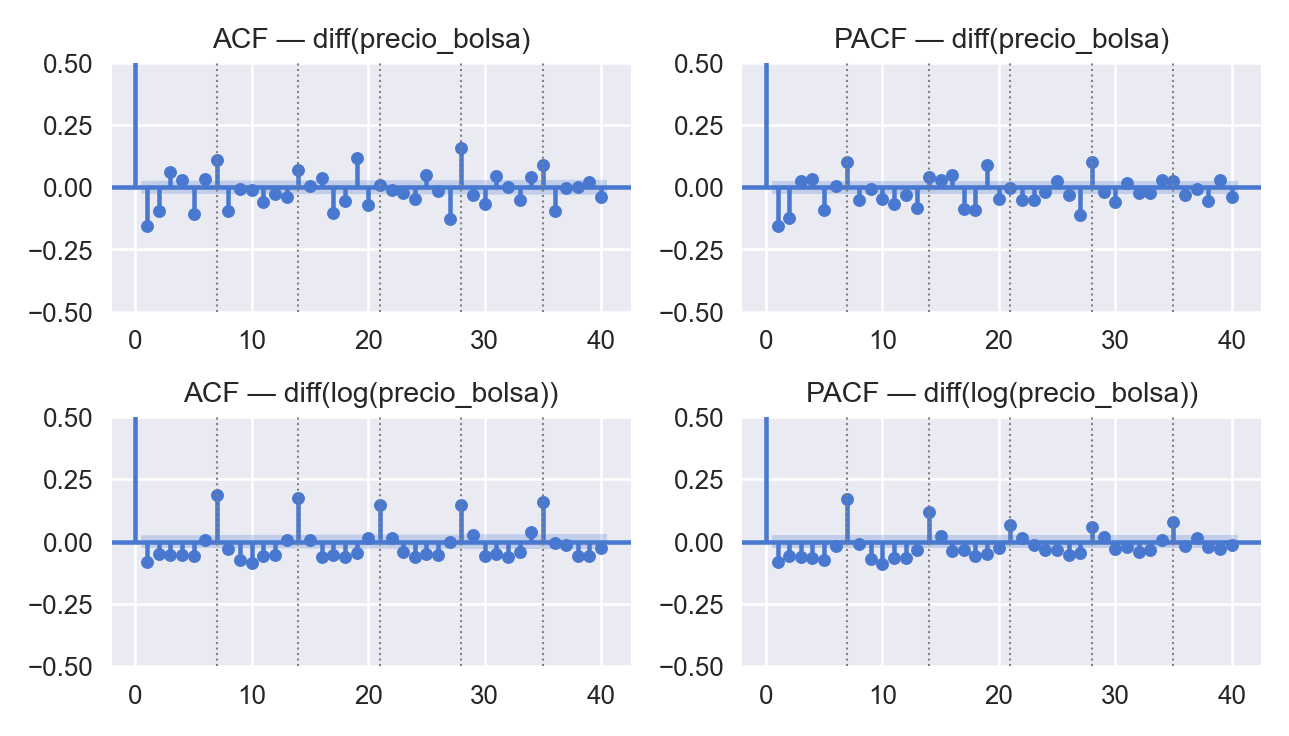

In [20]:
# ============================================================
# ADF + KPSS y ACF/PACF de la serie diferenciada (simple y logarítmica)
# ============================================================
# dropna() porque la primera diferencia pierde la primera observación.
import warnings
from statsmodels.tsa.stattools import kpss

series_diff = {
    "diff(precio_bolsa)": df["precio_bolsa"].diff().dropna(),
    "diff(log(precio_bolsa))": np.log(df["precio_bolsa"]).diff().dropna(),
}

# --- Pruebas de estacionariedad sobre cada versión diferenciada ---
# Misma especificación que en la sección 3 (ADF autolag="AIC", KPSS regression="c").
# Se capturan los avisos de interpolación de KPSS (p-value truncado a 0.01 o 0.1).
filas = []
for nombre, serie in series_diff.items():
    adf_stat, adf_p = adfuller(serie, autolag="AIC")[:2]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto")[:2]
    filas.append({
        "serie": nombre,
        "ADF estadístico": round(adf_stat, 3),
        "ADF p-value": round(adf_p, 4),
        "KPSS estadístico": round(kpss_stat, 3),
        "KPSS p-value": round(kpss_p, 4),
        "conclusión": (
            "ESTACIONARIA (ambas coinciden)"
            if adf_p < 0.05 and kpss_p >= 0.05
            else "revisar: las pruebas no coinciden en estacionariedad"
        ),
    })
display(pd.DataFrame(filas).set_index("serie"))
print("Nota: un KPSS p-value de 0.1 significa '>= 0.1' (truncado por la tabla de valores críticos).")

# --- ACF y PACF (40 rezagos) ---
fig, axes = plt.subplots(2, 2, figsize=(ANCHO_PAGINA, alto_pagina(14, 8)))
for fila, (nombre, serie) in enumerate(series_diff.items()):
    plot_acf(serie, lags=40, ax=axes[fila, 0])
    axes[fila, 0].set_title(f"ACF — {nombre}")
    plot_pacf(serie, lags=40, ax=axes[fila, 1], method="ywm")
    axes[fila, 1].set_title(f"PACF — {nombre}")
    # Líneas guía en los múltiplos de 7 para detectar el patrón semanal.
    for ax in axes[fila]:
        for k in range(7, 41, 7):
            ax.axvline(k, color="gray", linestyle=":", linewidth=0.8)
        ax.set_ylim(-0.5, 0.5)
a_escala(fig)
plt.tight_layout()
plt.show()

- **`d = 1` es suficiente**
- **Hallazgo principal — estacionalidad semanal fuerte, oculta en nivel**: en la diferencia logarítmica aparecen picos claros y regulares en los rezagos 7, 14, 21, 28 y 35 del ACF (≈0.15-0.18, todos muy por fuera de la banda) y en el PACF (0.17….
- **Cómo modelarlo**
- **Parte no estacional**
- **Diferencia logarítmica vs. simple**

### Rezagos largos (hasta 400 días) en la serie diferenciada

**Motivación** : el ACF/PACF a 365 rezagos de la serie en nivel está dominado por la persistencia y no deja ver bien el ciclo anual ni el semanal.

1. **¿Hay un pico anual (rezago 365) en los cambios diarios?**
2. **¿El patrón semanal se debilita con el tiempo o es estable?**

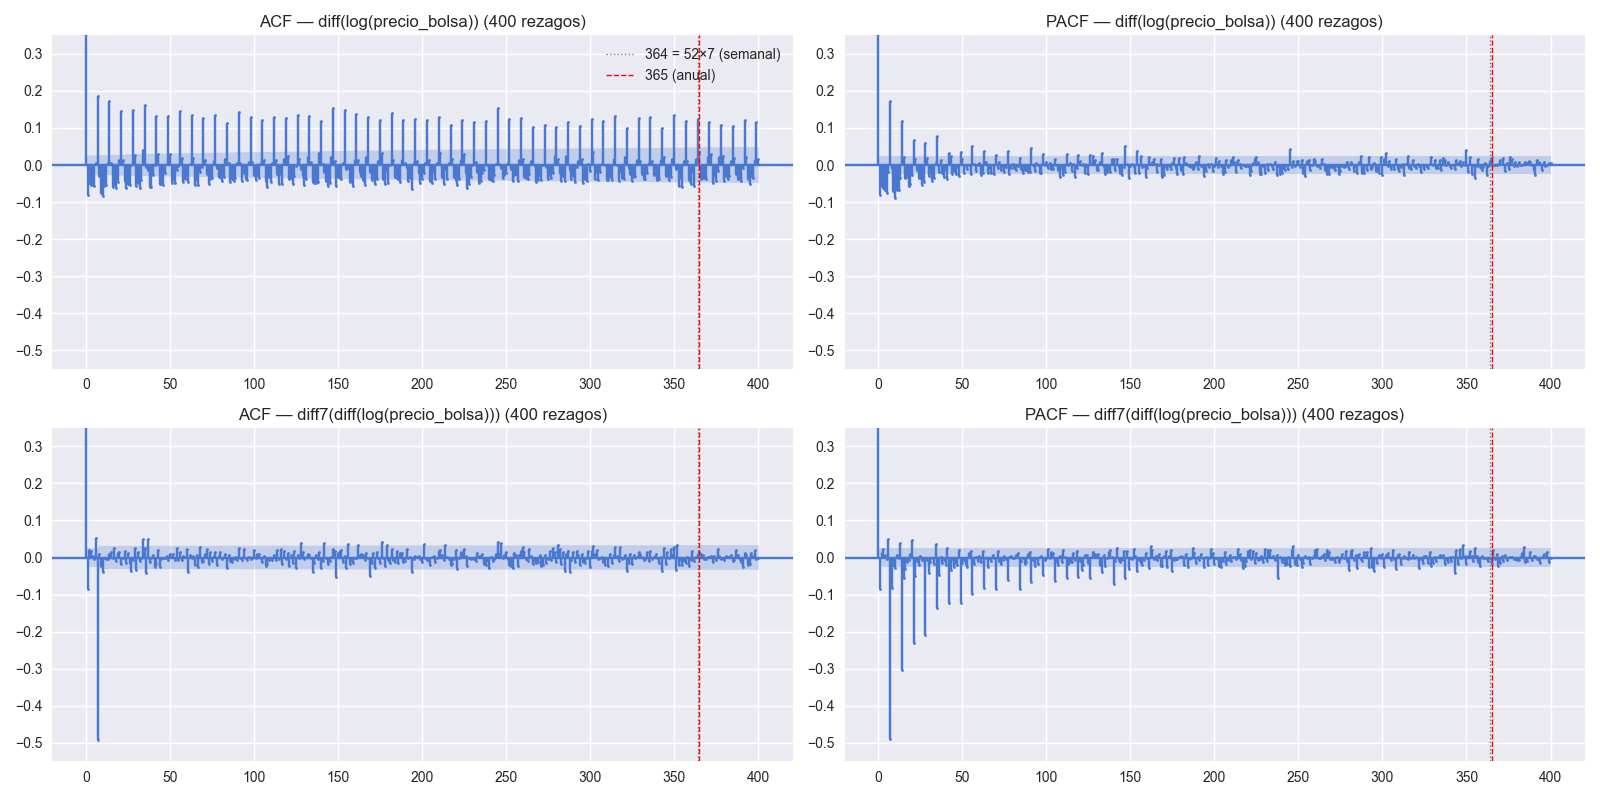

,diff(log(precio_bolsa)),diff7(diff(log(precio_bolsa)))
rezago,,
7,0.185,-0.493
14,0.174,0.010
56,0.145,0.014
105,0.120,-0.012
154,0.150,0.005
203,0.121,-0.007
252,0.124,-0.021
301,0.125,0.016
350,0.134,0.030


Banda de confianza aprox. (±1.96/√n): ±0.025


In [21]:
# ============================================================
# ACF/PACF a 400 rezagos: diferencia logarítmica y diferencia estacional semanal
# ============================================================
# Reutiliza series_diff de la celda de serie diferenciada (ejecutarla antes).
series_largo = {
    "diff(log(precio_bolsa))": series_diff["diff(log(precio_bolsa))"],
    "diff7(diff(log(precio_bolsa)))": series_diff["diff(log(precio_bolsa))"].diff(7).dropna(),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for fila, (nombre, serie) in enumerate(series_largo.items()):
    plot_acf(serie, lags=400, ax=axes[fila, 0], markersize=2)
    axes[fila, 0].set_title(f"ACF — {nombre} (400 rezagos)")
    plot_pacf(serie, lags=400, ax=axes[fila, 1], method="ywm", markersize=2)
    axes[fila, 1].set_title(f"PACF — {nombre} (400 rezagos)")
    for ax in axes[fila]:
        ax.axvline(364, color="gray", linestyle=":", linewidth=1, label="364 = 52×7 (semanal)")
        ax.axvline(365, color="red", linestyle="--", linewidth=1, label="365 (anual)")
        ax.set_ylim(-0.55, 0.35)
axes[0, 0].legend(loc="upper right")
plt.tight_layout()
plt.show()

# Valores puntuales: múltiplos de 7 a lo largo del año vs. el rezago anual
from statsmodels.tsa.stattools import acf
rezagos = [7, 14, 56, 105, 154, 203, 252, 301, 350, 364, 365, 371]
tabla = pd.DataFrame(
    {nombre: acf(serie, nlags=400)[rezagos] for nombre, serie in series_largo.items()},
    index=pd.Index(rezagos, name="rezago"),
).round(3)
display(tabla)
print(f"Banda de confianza aprox. (±1.96/√n): ±{1.96 / np.sqrt(len(series_largo['diff(log(precio_bolsa))'])):.3f}")

- **No hay pico anual en los cambios diarios**
- **La estacionalidad semanal es determinística**
- **La diferencia estacional semanal sobrediferencia**
- **Estacionalidad semanal**
- **Estacionalidad anual**
- **Features y baselines**

## 5. Estacionalidad de calendario y ENSO

Se revisan los efectos de calendario relevantes en precios de energía — mes del año, día de la semana y **tipo de día** (con festivos, no solo fin de semana) — y se agrega un análisis que no estaba en ninguno de….

### 5.1 Por mes del año

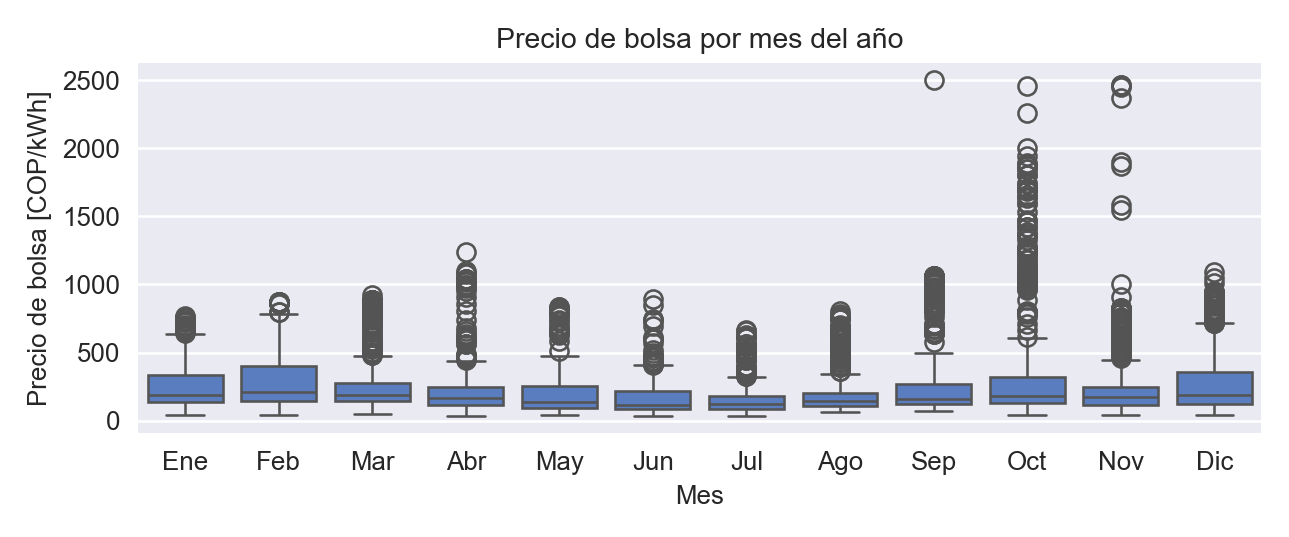

Mediana del precio de bolsa por mes del año [COP/kWh]:
mes_nombre
Ene    191.2
Feb    213.8
Mar    190.5
Abr    166.4
May    138.3
Jun    112.5
Jul    120.9
Ago    145.2
Sep    162.3
Oct    182.7
Nov    171.4
Dic    191.3

Más altos: Feb 213.8, Dic 191.3, Ene 191.2   (temporada seca)
Más bajos: Jun 112.5, Jul 120.9   (máximo de aportes hídricos)


In [22]:
# ============================================================
# Estacionalidad por mes del año (todos los años juntos, para aislar el
# patrón estacional de la tendencia de largo plazo)
# ============================================================
orden_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
df_mes = df.copy()
df_mes["mes_nombre"] = pd.Categorical(
    df_mes.index.month.map(lambda m: orden_meses[m - 1]),
    categories=orden_meses,
    ordered=True,
)

plt.figure(figsize=(ANCHO_PAGINA, alto_pagina(12, 5)))
sns.boxplot(data=df_mes, x="mes_nombre", y="precio_bolsa")
plt.title("Precio de bolsa por mes del año")
plt.xlabel("Mes")
plt.ylabel("Precio de bolsa [COP/kWh]")
a_escala(plt.gcf())
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Las medianas mensuales, en cifras
# ------------------------------------------------------------
# POR QUÉ. El diagrama de cajas muestra la FORMA del patrón anual, pero no permite leer el
# valor de ningún mes: para citar que febrero está en 213,8 y junio en 112,5 hace falta la
# cifra impresa. Se usa la mediana y no la media porque la serie tiene cola derecha larga y
# unas pocas decenas de días extremos moverían el promedio de cualquier mes.
med_mes = df_mes.groupby("mes_nombre", observed=True)["precio_bolsa"].median()
print("Mediana del precio de bolsa por mes del año [COP/kWh]:")
print(med_mes.round(1).to_string())
_altos = med_mes.nlargest(3)
_bajos = med_mes.nsmallest(2)
print("\nMás altos: " + ", ".join(f"{m} {v:.1f}" for m, v in _altos.items())
      + "   (temporada seca)")
print("Más bajos: " + ", ".join(f"{m} {v:.1f}" for m, v in _bajos.items())
      + "   (máximo de aportes hídricos)")

### 5.2 Por día de la semana

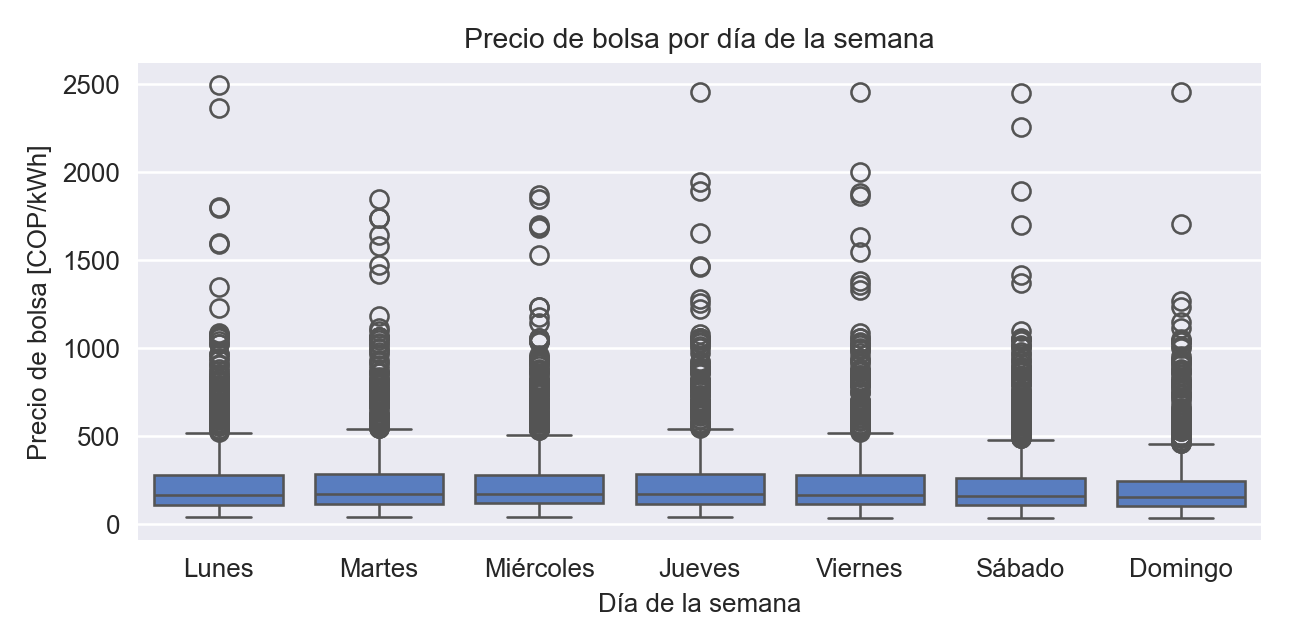

In [23]:
# ============================================================
# Estacionalidad por día de la semana
# ============================================================
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
nombres_dias = dict(zip(range(7), orden_dias))

df_dia = df.copy()
df_dia["dia_semana_nombre"] = pd.Categorical(
    df_dia.index.dayofweek.map(nombres_dias),
    categories=orden_dias,
    ordered=True,
)

plt.figure(figsize=(ANCHO_PAGINA, alto_pagina(10, 5)))
sns.boxplot(data=df_dia, x="dia_semana_nombre", y="precio_bolsa")
plt.title("Precio de bolsa por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Precio de bolsa [COP/kWh]")
a_escala(plt.gcf())
plt.tight_layout()
plt.show()

### 5.3 Por tipo de día (incluye festivos)

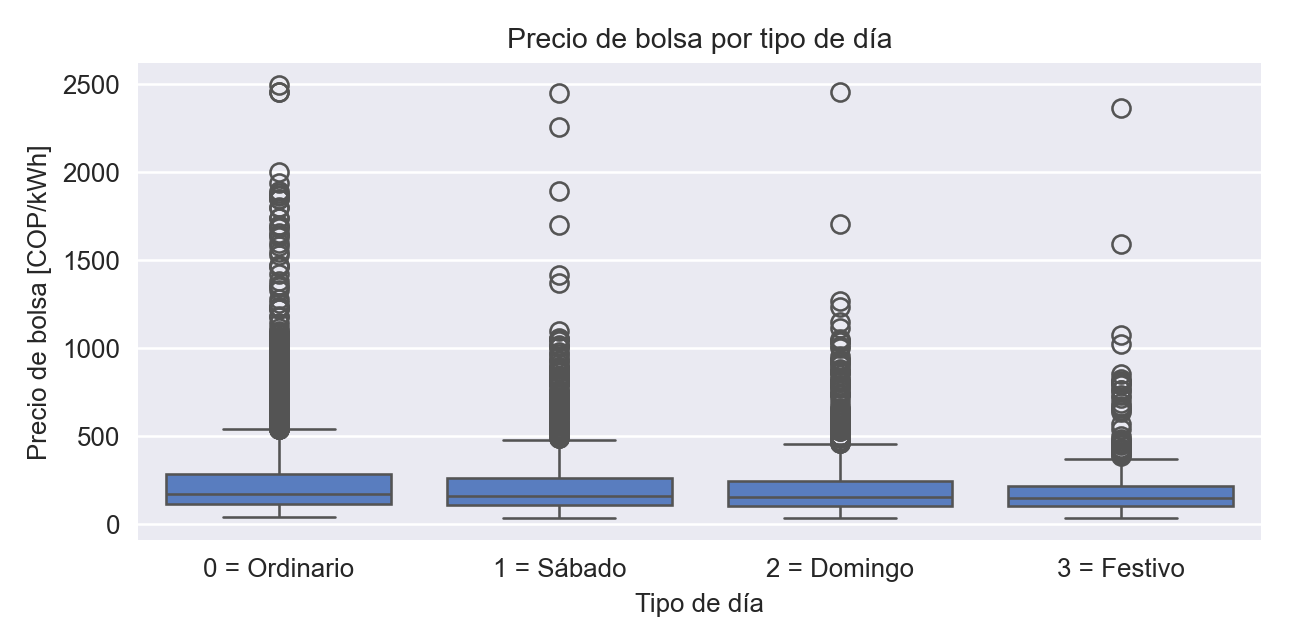

In [24]:
# ============================================================
# Estacionalidad por tipo de día: 0=Ordinario, 1=Sábado, 2=Domingo, 3=Festivo
# ============================================================
# A diferencia del boxplot de día de la semana de arriba, esta variable SÍ distingue
# los festivos entre semana (ej. un lunes festivo no se cuenta como día ordinario) — ver
# 2_DataProcessing.ipynb, celda "Variables de calendario", para la definición completa,
# la regla de prioridad festivo-sobre-domingo, y la fuente del calendario de festivos
# colombianos (librería `holidays`, con la Ley Emiliani aplicada).
TIPO_DIA_LABELS = {0: "0 = Ordinario", 1: "1 = Sábado", 2: "2 = Domingo", 3: "3 = Festivo"}
df_tipo_dia = df.copy()
df_tipo_dia["tipo_dia_label"] = df_tipo_dia["tipo_dia"].map(TIPO_DIA_LABELS)

plt.figure(figsize=(ANCHO_PAGINA, alto_pagina(10, 5)))
orden_tipo_dia = [TIPO_DIA_LABELS[i] for i in range(4)]
sns.boxplot(data=df_tipo_dia, x="tipo_dia_label", y="precio_bolsa", order=orden_tipo_dia)
plt.title("Precio de bolsa por tipo de día")
plt.xlabel("Tipo de día")
plt.ylabel("Precio de bolsa [COP/kWh]")
a_escala(plt.gcf())
plt.tight_layout()
plt.show()

### 5.4 Por categoría ENSO (El Niño / Neutral / La Niña)

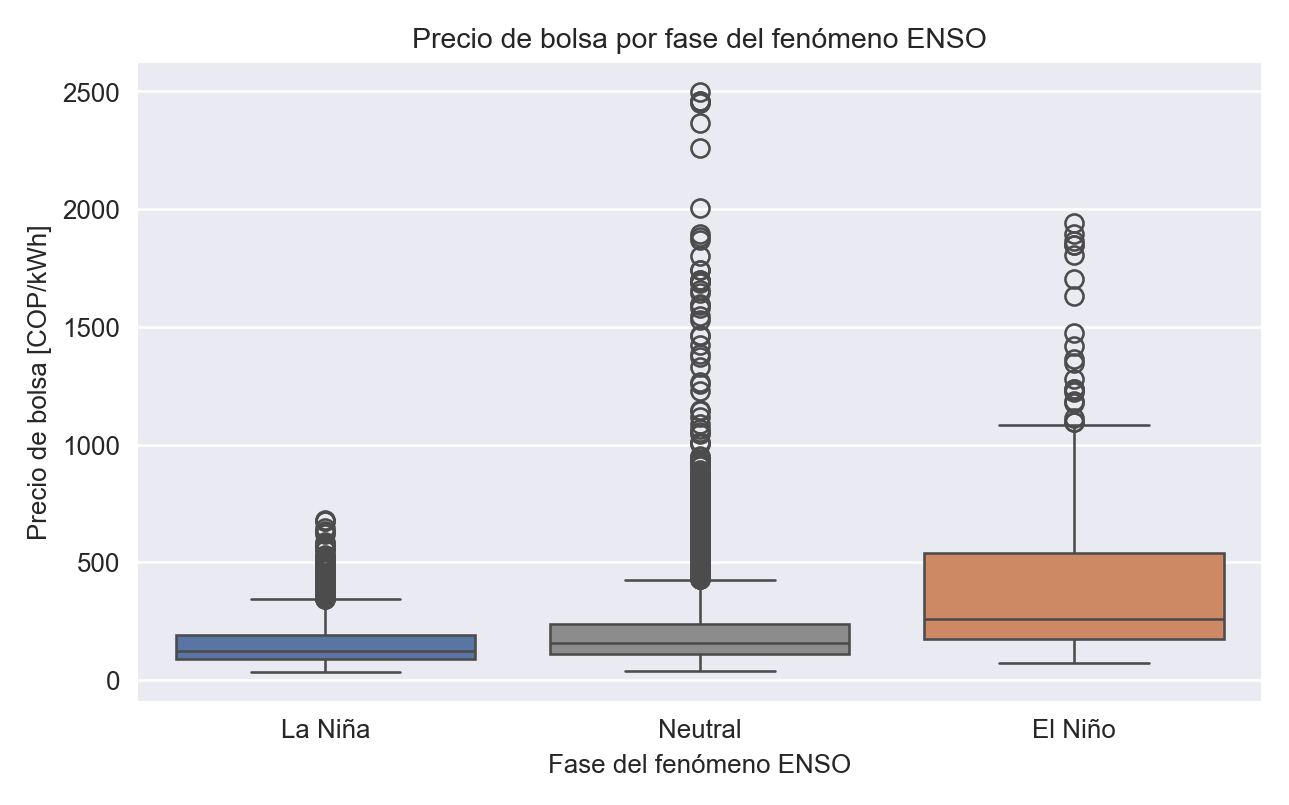

categoria_enso
La Niña    1612
Neutral    2832
El Niño    1520
Name: count, dtype: int64


In [25]:
# ============================================================
# Estacionalidad por categoría ENSO — tomado de la tesis de Camilo Jaramillo
# ============================================================
# Clasificación estándar NOAA a partir del índice ONI (misma fuente que ya usamos en
# 1_DataExtraction.ipynb, Paso 6): El Niño si ONI >= 0.5, La Niña si ONI <= -0.5, y
# Neutral en el resto. Jaramillo (Figura 18 de su documento) usa el mismo criterio
# y encuentra que la mediana y la cola superior del precio son mayores bajo El Niño,
# intermedias en Neutral, y menores en La Niña — se replica aquí sobre nuestro propio
# dataset (2010-2026, más largo que el de Jaramillo, 2020-2025) para confirmar si el
# patrón se sostiene.
def clasificar_enso(oni):
    if oni >= 0.5:
        return "El Niño"
    elif oni <= -0.5:
        return "La Niña"
    else:
        return "Neutral"

df_enso = df.copy()
df_enso["categoria_enso"] = df_enso["indice_ONI"].apply(clasificar_enso)

orden_enso = ["La Niña", "Neutral", "El Niño"]
plt.figure(figsize=(ANCHO_PAGINA, alto_pagina(8, 5)))
sns.boxplot(data=df_enso, x="categoria_enso", y="precio_bolsa", order=orden_enso,
            hue="categoria_enso", legend=False,
            palette={"La Niña": "#4C72B0", "Neutral": "#8C8C8C", "El Niño": "#DD8452"})
plt.title("Precio de bolsa por fase del fenómeno ENSO")
plt.xlabel("Fase del fenómeno ENSO")
plt.ylabel("Precio de bolsa [COP/kWh]")
a_escala(plt.gcf())
plt.tight_layout()
plt.show()

print(df_enso["categoria_enso"].value_counts().reindex(orden_enso))

In [26]:
# ============================================================
# 5.4 bis — La misma clasificación con el ONI PUBLICADO
# ============================================================
# POR QUÉ IMPORTA. El trabajo se compromete a reportar el error segmentado por fase ENSO, y
# esa segmentación debe poder hacerse CON LA INFORMACIÓN DISPONIBLE EL DÍA DEL PRONÓSTICO.
# El índice ONI de arriba es el CENTRADO: la NOAA lo calcula como media móvil de tres meses
# centrada, de modo que el valor de un mes solo se conoce después. Usarlo para clasificar
# los días de prueba sería mirar el futuro.
#
# `indice_ONI_publicado` es la misma variable desplazada a su fecha real de publicación. El
# EDA describe con la centrada —que es la que representa el fenómeno— pero la evaluación y
# el modelado usan la publicada. Aquí se comprueba cuánto difieren las dos clasificaciones:
# si coincidieran siempre, la distinción sería irrelevante; si difieren, hay que respetarla.
df_pub = pd.read_csv(ruta_dataset, usecols=["fecha", "indice_ONI_publicado"])
df_pub["fecha"] = pd.to_datetime(df_pub["fecha"])
df_pub = df_pub.set_index("fecha").reindex(df.index)

fase_centrada = df["indice_ONI"].apply(clasificar_enso)
fase_publicada = df_pub["indice_ONI_publicado"].apply(clasificar_enso)

cruce = pd.crosstab(fase_centrada.rename("centrado"), fase_publicada.rename("publicado"))
cruce = cruce.reindex(index=orden_enso, columns=orden_enso, fill_value=0)
print("Días clasificados en cada fase, según la versión del índice:")
print(cruce.to_string())
coinciden = (fase_centrada == fase_publicada).mean()
print(f"\nLas dos versiones coinciden en el {100 * coinciden:.1f} % de los días.")
print(f"Difieren en {int((fase_centrada != fase_publicada).sum())} días, los de las transiciones")
print("La pregunta que importa no es CUÁNTOS días difieren sino SI el desacuerdo es de calendario")
print("o de fenómeno. Si fuera de fenómeno habría días clasificados La Niña por una versión y El")
print("Niño por la otra, que son fases opuestas:")
_opuestas = int(cruce.loc["La Niña", "El Niño"] + cruce.loc["El Niño", "La Niña"])
print(f"   desacuerdos entre fases OPUESTAS: {_opuestas} días de {len(df)}.")
print("Todos los demás son entre fases contiguas, de modo que el desacuerdo es de CALENDARIO: el")
print("índice publicado llega con unos dos meses de retraso y, como los episodios duran meses, ese")
print("retraso corre la frontera de cada fase sin cambiar cuál es.")
print("")
print("Que una cuarta parte de los días cambie de etiqueta no es un defecto del dato: es la medida")
print("de cuánto se sabe de menos al pronosticar. Evaluar con la versión centrada daría una")
print("segmentación más limpia y, por eso mismo, optimista — sería clasificar cada día con")
print("información que no existía la fecha en que se emitió el pronóstico.")

resumen_fases = pd.DataFrame({
    "n_días (centrado)": fase_centrada.value_counts().reindex(orden_enso),
    "n_días (publicado)": fase_publicada.value_counts().reindex(orden_enso),
    "precio mediano (centrado)": df.groupby(fase_centrada)["precio_bolsa"].median().reindex(orden_enso),
    "precio mediano (publicado)": df.groupby(fase_publicada)["precio_bolsa"].median().reindex(orden_enso),
    # EL PERCENTIL 90, Y NO SOLO LA MEDIANA, porque entre fases no se desplaza únicamente el
    # nivel: la cola superior se ensancha, y es la cola la que gobierna el error de un
    # pronóstico. La mediana sola describiría el fenómeno como un cambio de nivel y no lo es.
    "p90 (centrado)": df.groupby(fase_centrada)["precio_bolsa"].quantile(0.90).reindex(orden_enso),
    "p90 (publicado)": df.groupby(fase_publicada)["precio_bolsa"].quantile(0.90).reindex(orden_enso)})
print("\n" + resumen_fases.round(1).to_string())
print("\nLa ordenación La Niña < Neutral < El Niño se mantiene con las dos versiones: la")
print("conclusión cualitativa del boxplot no depende de cuál se use, pero la evaluación")
print("segmentada del trabajo usa la PUBLICADA, que es la que se conoce al pronosticar.")
_p90 = resumen_fases["p90 (centrado)"]
_med = resumen_fases["precio mediano (centrado)"]
print(f"\nLa asimetría crece en el mismo sentido que el nivel: entre La Niña y El Niño la "
      f"mediana\nse multiplica por {_med['El Niño'] / _med['La Niña']:.2f} y el percentil 90 "
      f"por {_p90['El Niño'] / _p90['La Niña']:.2f}. No es solo que el precio suba durante el "
      f"\nepisodio seco: su cola superior se estira más deprisa que su centro.")

Días clasificados en cada fase, según la versión del índice:
publicado  La Niña  Neutral  El Niño
centrado                            
La Niña       1190      417        5
Neutral        418     2088      326
El Niño          0      264     1256

Las dos versiones coinciden en el 76.0 % de los días.
Difieren en 1430 días, los de las transiciones
La pregunta que importa no es CUÁNTOS días difieren sino SI el desacuerdo es de calendario
o de fenómeno. Si fuera de fenómeno habría días clasificados La Niña por una versión y El
Niño por la otra, que son fases opuestas:
   desacuerdos entre fases OPUESTAS: 5 días de 5964.
Todos los demás son entre fases contiguas, de modo que el desacuerdo es de CALENDARIO: el
índice publicado llega con unos dos meses de retraso y, como los episodios duran meses, ese
retraso corre la frontera de cada fase sin cambiar cuál es.

Que una cuarta parte de los días cambie de etiqueta no es un defecto del dato: es la medida
de cuánto se sabe de menos al pronosticar

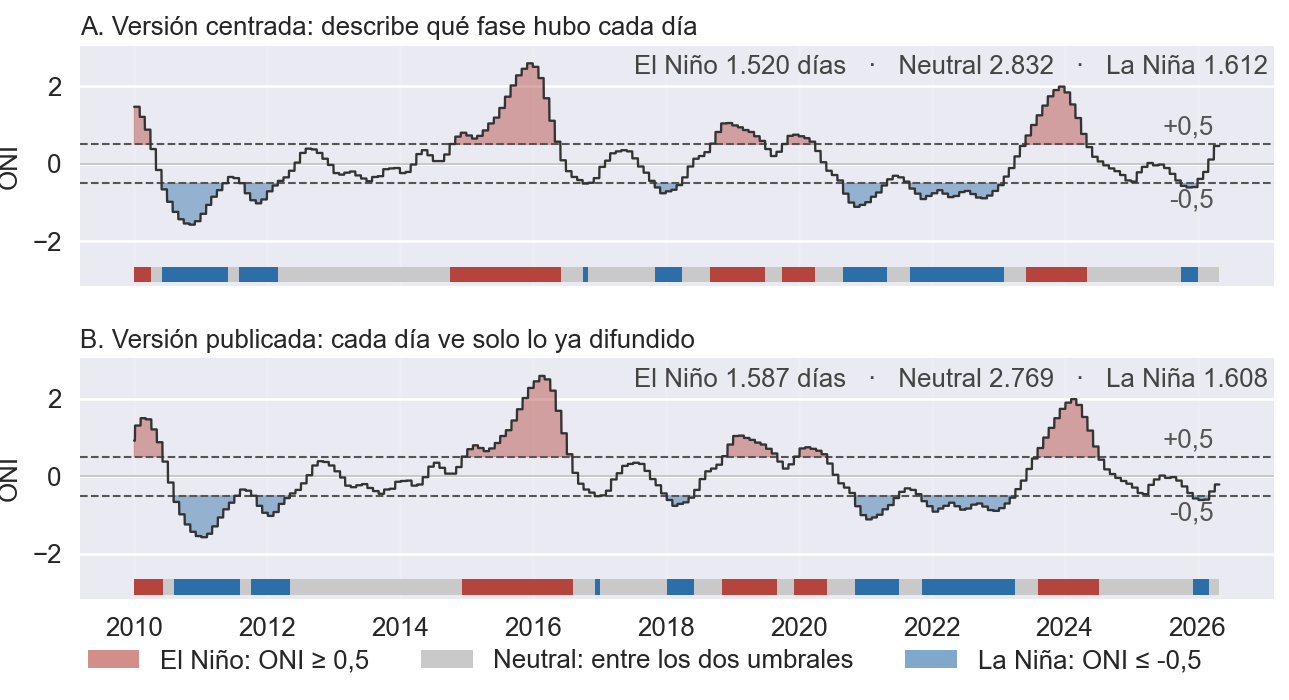

Figura guardada en C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB\datasets\procesado\3_clasificacion_enso.png
  centrada : {'Neutral': 2832, 'La Niña': 1612, 'El Niño': 1520}
  publicada: {'Neutral': 2769, 'La Niña': 1608, 'El Niño': 1587}
  coinciden en 4534 de 5964 días (76.0 %)


In [27]:
# ============================================================
# 5.4 ter — La regla de clasificación, vista sobre toda la serie
# ============================================================
# QUÉ AÑADE A LAS DOS CELDAS ANTERIORES. La 5.4 responde qué precio tiene cada fase y la
# 5.4 bis cuánto difieren las dos versiones del índice, pero ninguna muestra la REGLA en
# sí: cuándo un día es El Niño, cuándo La Niña y cuándo Neutral. Esta figura la dibuja
# aplicada sobre los dieciséis años, con los dos umbrales a la vista y la fase asignada en
# una franja bajo cada panel.
#
# POR QUÉ DOS PANELES. Puestos uno sobre otro con el mismo eje de tiempo se ve que la
# versión publicada reproduce a la centrada con unos dos meses de retraso: las fronteras de
# cada episodio se corren, pero los episodios son los mismos. Es la conclusión que la celda
# anterior obtiene con cifras; aquí se comprueba mirando.
#
# SE GUARDA EN DISCO porque el documento la incluye. Así la figura del documento y la del
# notebook son el mismo archivo y no pueden divergir.
#
# EL TAMAÑO ES EL DE LA PÁGINA, no el de la pantalla: 6,93 pulgadas de ancho a 186 ppp, que
# son los 1289 px que usan las demás figuras del documento. Dibujarla más ancha y dejar que
# Word la encaje en la columna reduciría todo su texto a la mitad.
import matplotlib.dates as mdates
from matplotlib.patches import Patch

UMBRAL_ENSO = 0.5
C_NINO, C_NINA, C_NEU = "#b5453c", "#2c6fa8", "#c9c9c9"
PPP_PAGINA, ANCHO_PX, ALTO_PX = 186, 1289, 700

# El ONI publicado no está en `df`: la celda de la matriz de correlación lo retira para no
# meter dos veces la misma variable. Se lee del archivo, igual que en la celda anterior.
oni_pub = pd.read_csv(ruta_dataset, usecols=["fecha", "indice_ONI_publicado"])
oni_pub["fecha"] = pd.to_datetime(oni_pub["fecha"])
oni_pub = oni_pub.set_index("fecha").reindex(df.index)["indice_ONI_publicado"]


def _panel_enso(ax, serie, titulo):
    """Dibuja el índice, sus dos umbrales y la franja con la fase asignada a cada día."""
    x = mdates.date2num(serie.index)
    v = serie.values
    ax.plot(x, v, color="#333", lw=0.9, zorder=4)
    ax.fill_between(x, UMBRAL_ENSO, v, where=(v >= UMBRAL_ENSO), color=C_NINO, alpha=0.45,
                    interpolate=True, zorder=2)
    ax.fill_between(x, -UMBRAL_ENSO, v, where=(v <= -UMBRAL_ENSO), color=C_NINA, alpha=0.45,
                    interpolate=True, zorder=2)
    for y in (UMBRAL_ENSO, -UMBRAL_ENSO):
        ax.axhline(y, color="#555", lw=0.8, ls="--", zorder=3)
    ax.axhline(0, color="#bbb", lw=0.6, zorder=1)
    ax.annotate("+0,5", (x[-1], UMBRAL_ENSO), xytext=(-2, 2), textcoords="offset points",
                fontsize=10, color="#555", va="bottom", ha="right")
    ax.annotate("-0,5", (x[-1], -UMBRAL_ENSO), xytext=(-2, -2), textcoords="offset points",
                fontsize=10, color="#555", va="top", ha="right")

    # la franja inferior: la fase que la regla asigna a cada día, en tramos de color
    fases = serie.apply(clasificar_enso).values
    color = {"El Niño": C_NINO, "La Niña": C_NINA, "Neutral": C_NEU}
    ini = 0
    for i in range(1, len(fases) + 1):
        if i == len(fases) or fases[i] != fases[ini]:
            ax.fill_between([x[ini], x[min(i, len(x) - 1)]], -3.05, -2.65,
                            color=color[fases[ini]], lw=0, zorder=4)
            ini = i
    ax.set_ylim(-3.15, 3.05)
    ax.set_ylabel("ONI", fontsize=10)
    ax.set_title(titulo, fontsize=10, loc="left", pad=4)
    ax.tick_params(labelsize=10)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    return pd.Series(fases, index=serie.index)


fig, axes = plt.subplots(2, 1, sharex=True,
                         figsize=(ANCHO_PX / PPP_PAGINA, ALTO_PX / PPP_PAGINA))
fig.subplots_adjust(left=0.062, right=0.988, top=0.935, bottom=0.145, hspace=0.30)
f_cen = _panel_enso(axes[0], df["indice_ONI"],
                    "A. Versión centrada: describe qué fase hubo cada día")
f_pub = _panel_enso(axes[1], oni_pub,
                    "B. Versión publicada: cada día ve solo lo ya difundido")
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

_mil = lambda n: format(int(n), ",").replace(",", ".")
for ax, f in ((axes[0], f_cen), (axes[1], f_pub)):
    c = f.value_counts()
    ax.annotate("El Niño %s días   ·   Neutral %s   ·   La Niña %s"
                % (_mil(c["El Niño"]), _mil(c["Neutral"]), _mil(c["La Niña"])),
                (0.995, 0.96), xycoords="axes fraction", ha="right", va="top",
                fontsize=10, color="#444")

fig.legend(handles=[Patch(facecolor=C_NINO, alpha=0.6, label="El Niño: ONI ≥ 0,5"),
                    Patch(facecolor=C_NEU, label="Neutral: entre los dos umbrales"),
                    Patch(facecolor=C_NINA, alpha=0.6, label="La Niña: ONI ≤ -0,5")],
           loc="lower center", ncol=3, fontsize=10, frameon=False, bbox_to_anchor=(0.5, 0.005))

ruta_fig_enso = os.path.join(abspath, "datasets", "procesado", "3_clasificacion_enso.png")
fig.savefig(ruta_fig_enso, dpi=PPP_PAGINA, facecolor="white")
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la
# figura, que vale 100: sin esto el cuaderno guardaria una version de 696 px de la misma
# figura que el archivo de arriba escribe a 1289, y la del documento no se podria cotejar
# contra la del notebook.
fig.set_dpi(PPP_PAGINA)
plt.show()

print(f"Figura guardada en {ruta_fig_enso}")
print(f"  centrada : {dict(f_cen.value_counts())}")
print(f"  publicada: {dict(f_pub.value_counts())}")
print(f"  coinciden en {(f_cen.values == f_pub.values).sum()} de {len(f_cen)} días "
      f"({100 * (f_cen.values == f_pub.values).mean():.1f} %)")


## 6. Variables explicativas: panorama general

Antes de cruzar cada variable contra el precio de bolsa, conviene ver de un vistazo cómo se comporta cada una en el tiempo — para detectar cambios de escala, quiebres estructurales o series con comportamiento claramente distinto al del precio.

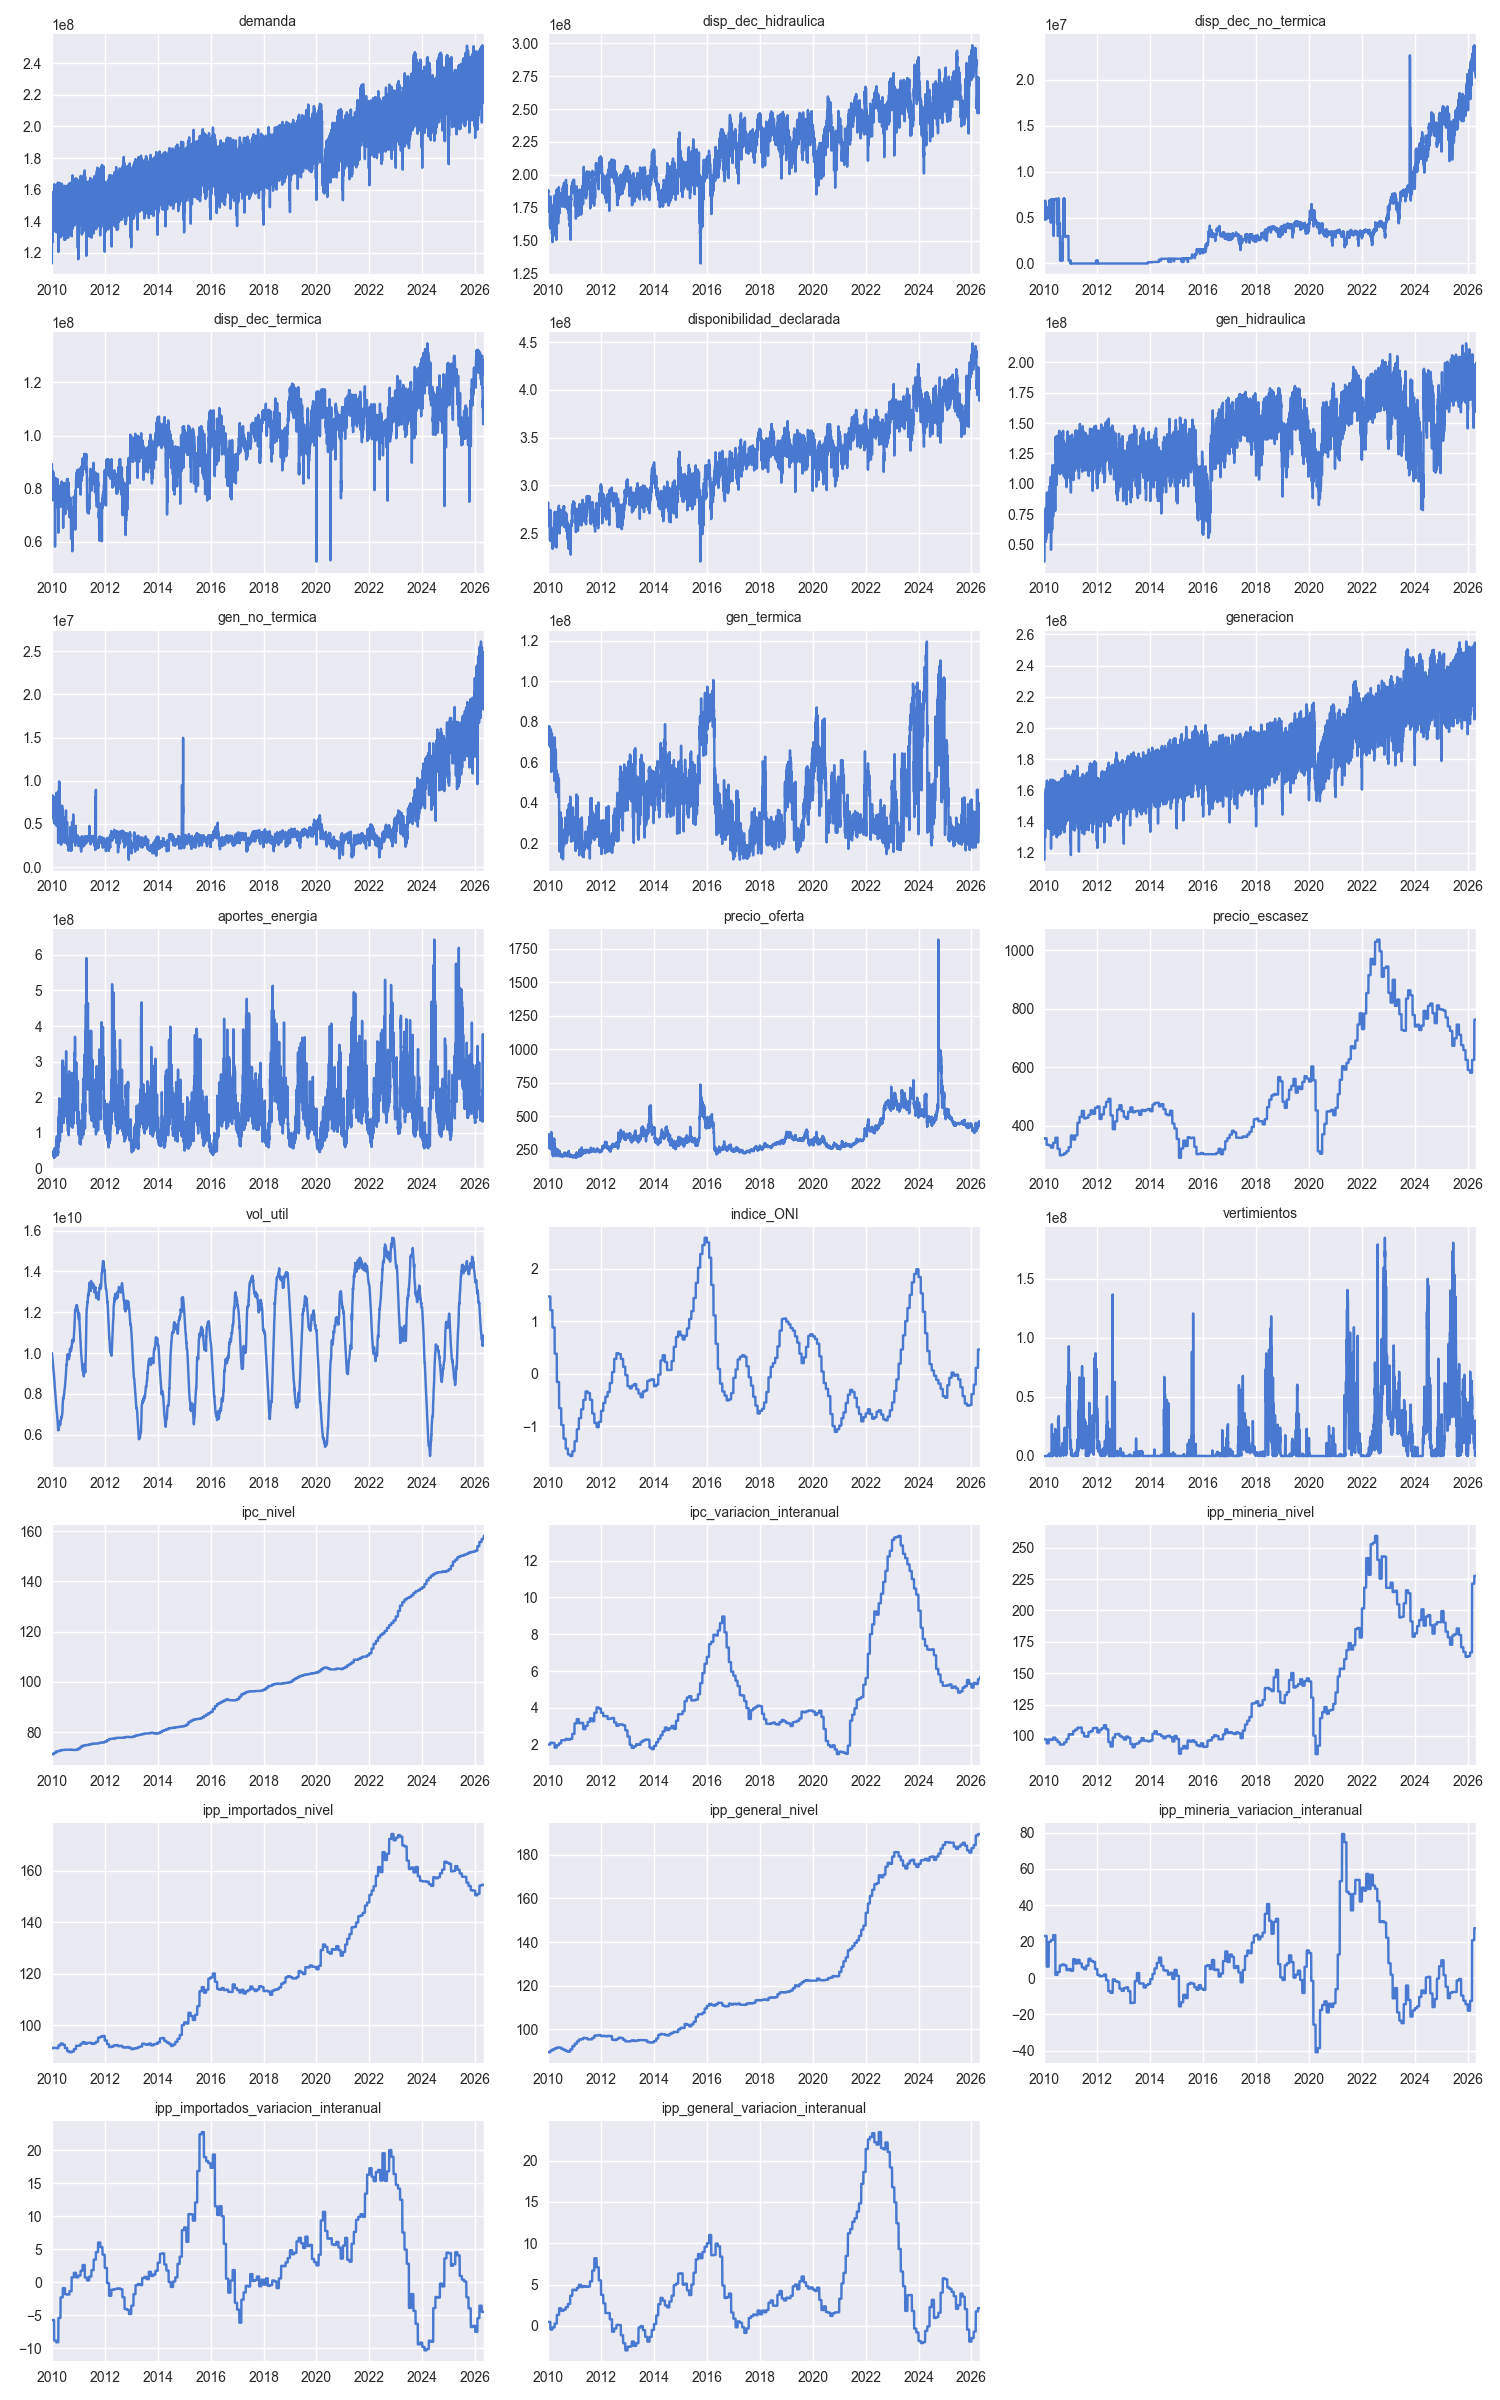

In [28]:
# ============================================================
# Cuadrícula de series de tiempo: una por cada variable explicativa
# ============================================================
# Se excluyen precio_bolsa (ya se graficó aparte en la sección 2) y las 4 variables de
# calendario (CALENDARIO_COLS) — al ser categóricas/cíclicas de pocos valores, su
# gráfico de serie de tiempo es solo un patrón de "escalones" repetitivo sin información
# nueva respecto a los boxplots ya mostrados en la sección 5.
columnas_explicativas = [c for c in df.columns if c != "precio_bolsa" and c not in CALENDARIO_COLS]

n_cols = 3
n_rows = int(np.ceil(len(columnas_explicativas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_explicativas):
    df[columna].plot(ax=ax)
    ax.set_title(columna, fontsize=10)
    ax.set_xlabel("")

# Apaga los subplots sobrantes si el número de variables no llena la última fila.
for ax in axes[len(columnas_explicativas):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 6.1 Caracterización estadística de cada variable explicativa

La cuadrícula de arriba muestra cómo se mueve cada variable en el tiempo, pero no permite compararlas: están en unidades distintas y en escalas que difieren en varios órdenes de magnitud.

In [29]:
# ============================================================
# 6.1 — Estadísticos descriptivos de las variables explicativas
# ============================================================
# POR QUÉ HACE FALTA. La sección 2 caracteriza a fondo la variable objetivo: media, mediana,
# dispersión, asimetría y curtosis. A las explicativas, en cambio, el notebook solo las mira EN
# RELACIÓN con el precio (secciones 7 y 8). Este bloque las describe por sí mismas, que es lo que
# permite justificar después por qué una entra transformada y otra no.
#
# QUÉ MIDE CADA COLUMNA:
#   media y mediana   el nivel típico; si se separan, ya hay asimetría
#   CV                desviación sobre media en valor absoluto. Es lo ÚNICO que permite comparar
#                     la variabilidad entre variables de unidades distintas
#   asimetría         cola larga a la derecha si es positiva
#   curtosis          cuán pesadas son las colas frente a una normal
#   % de ceros        estructura que la media esconde por completo
#   tendencia         pendiente de una recta sobre el tiempo, en % del nivel medio por año
CALENDARIO_EXPL = [c for c in CALENDARIO_COLS if c in df.columns]
explicativas_cont = [c for c in df.columns
                     if c != "precio_bolsa" and c not in CALENDARIO_EXPL]

desc = pd.DataFrame(index=explicativas_cont)
desc["n"] = df[explicativas_cont].notna().sum()
desc["media"] = df[explicativas_cont].mean()
desc["mediana"] = df[explicativas_cont].median()
desc["desv."] = df[explicativas_cont].std()
desc["CV"] = (desc["desv."] / desc["media"].abs()).replace([np.inf, -np.inf], np.nan)
desc["mín"] = df[explicativas_cont].min()
desc["máx"] = df[explicativas_cont].max()
desc["asimetría"] = df[explicativas_cont].skew()
desc["curtosis"] = df[explicativas_cont].kurt()
desc["% ceros"] = (df[explicativas_cont] == 0).mean() * 100

# Tendencia: pendiente de una recta ajustada sobre el tiempo, expresada en % del nivel medio por
# año, para que sea comparable entre variables de unidades distintas.
_anios = (df.index - df.index[0]).days / 365.25
desc["tend. %/año"] = [np.polyfit(_anios, df[c].values, 1)[0] / abs(df[c].mean()) * 100
                       if df[c].std() > 0 else np.nan for c in explicativas_cont]

print(f"Variables explicativas continuas: {len(explicativas_cont)}\n")
display(desc.sort_values("CV", ascending=False).round(2))

print("Lo que la tabla destapa y no se veía en la cuadrícula de series:\n")
_ceros = desc.loc[desc["% ceros"] > 0, "% ceros"].sort_values(ascending=False)
for v, p in _ceros.items():
    print(f"  · {v} es CERO el {p:.0f} % de los días.")
print("    Una media y una desviación no describen una variable así: hace falta además un")
print("    indicador binario de si hubo o no, que es lo que el modelado construye para")
print("    vertimientos.\n")

_tend = desc["tend. %/año"].abs().sort_values(ascending=False).head(3)
print("  · Las de mayor deriva en el periodo:")
for v in _tend.index:
    print(f"      {v}: {desc.loc[v, 'tend. %/año']:+.1f} % al año")
print("    La disponibilidad y la generación no térmicas crecen porque parten de casi nada:")
print("    es la entrada de renovables al sistema, no una variación del régimen hidrológico.\n")

print("  · ADVERTENCIA SOBRE EL CV: no es comparable cuando la media está cerca de cero.")
_cv_falso = desc.loc[desc["media"].abs() < desc["desv."] * 0.2].index.tolist()
print(f"      {', '.join(_cv_falso)} tienen media cercana a cero,")
print("      de modo que su CV es enorme por construcción y no mide volatilidad.")


Variables explicativas continuas: 23



,n,media,mediana,desv.,CV,mín,máx,asimetría,curtosis,% ceros,tend. %/año
indice_ONI,5964,4.000000e-02,-1.100000e-01,8.300000e-01,19.37,-1.570000e+00,2.590000e+00,0.82,0.54,0.00,24.90
ipp_mineria_variacion_interanual,5964,6.230000e+00,2.880000e+00,1.969000e+01,3.16,-4.082000e+01,7.921000e+01,1.09,1.51,0.00,2.69
ipp_importados_variacion_interanual,5964,3.350000e+00,1.830000e+00,7.050000e+00,2.10,-1.034000e+01,2.275000e+01,0.64,0.13,0.00,3.94
vertimientos,5964,1.349146e+07,1.524250e+06,2.516315e+07,1.87,0.000000e+00,1.846724e+08,2.88,9.67,38.78,13.22
ipp_general_variacion_interanual,5964,4.700000e+00,3.390000e+00,5.860000e+00,1.25,-2.960000e+00,2.345000e+01,1.67,2.49,0.00,7.14
disp_dec_no_termica,5964,4.521497e+06,3.242660e+06,5.126865e+06,1.13,0.000000e+00,2.378674e+07,1.62,1.94,17.49,18.16
gen_no_termica,5964,5.178175e+06,3.555205e+06,4.214262e+06,0.81,8.549110e+05,2.613021e+07,2.29,4.80,0.00,10.63
ipc_variacion_interanual,5964,4.810000e+00,3.810000e+00,2.860000e+00,0.59,1.490000e+00,1.334000e+01,1.37,1.17,0.00,6.81
aportes_energia,5964,1.705325e+08,1.565998e+08,8.414724e+07,0.49,2.903210e+07,6.430755e+08,1.12,1.79,0.00,2.50
gen_termica,5964,4.074308e+07,3.563308e+07,1.931437e+07,0.47,1.197768e+07,1.197190e+08,1.11,0.91,0.00,0.57


Lo que la tabla destapa y no se veía en la cuadrícula de series:

  · vertimientos es CERO el 39 % de los días.
  · disp_dec_no_termica es CERO el 17 % de los días.
    Una media y una desviación no describen una variable así: hace falta además un
    indicador binario de si hubo o no, que es lo que el modelado construye para
    vertimientos.

  · Las de mayor deriva en el periodo:
      indice_ONI: +24.9 % al año
      disp_dec_no_termica: +18.2 % al año
      vertimientos: +13.2 % al año
    La disponibilidad y la generación no térmicas crecen porque parten de casi nada:
    es la entrada de renovables al sistema, no una variación del régimen hidrológico.

  · ADVERTENCIA SOBRE EL CV: no es comparable cuando la media está cerca de cero.
      indice_ONI tienen media cercana a cero,
      de modo que su CV es enorme por construcción y no mide volatilidad.


### 6.2 Las explicativas, comparadas entre sí

La tabla anterior es exacta pero tiene veintitrés filas y once columnas, y no se abarca de un vistazo.

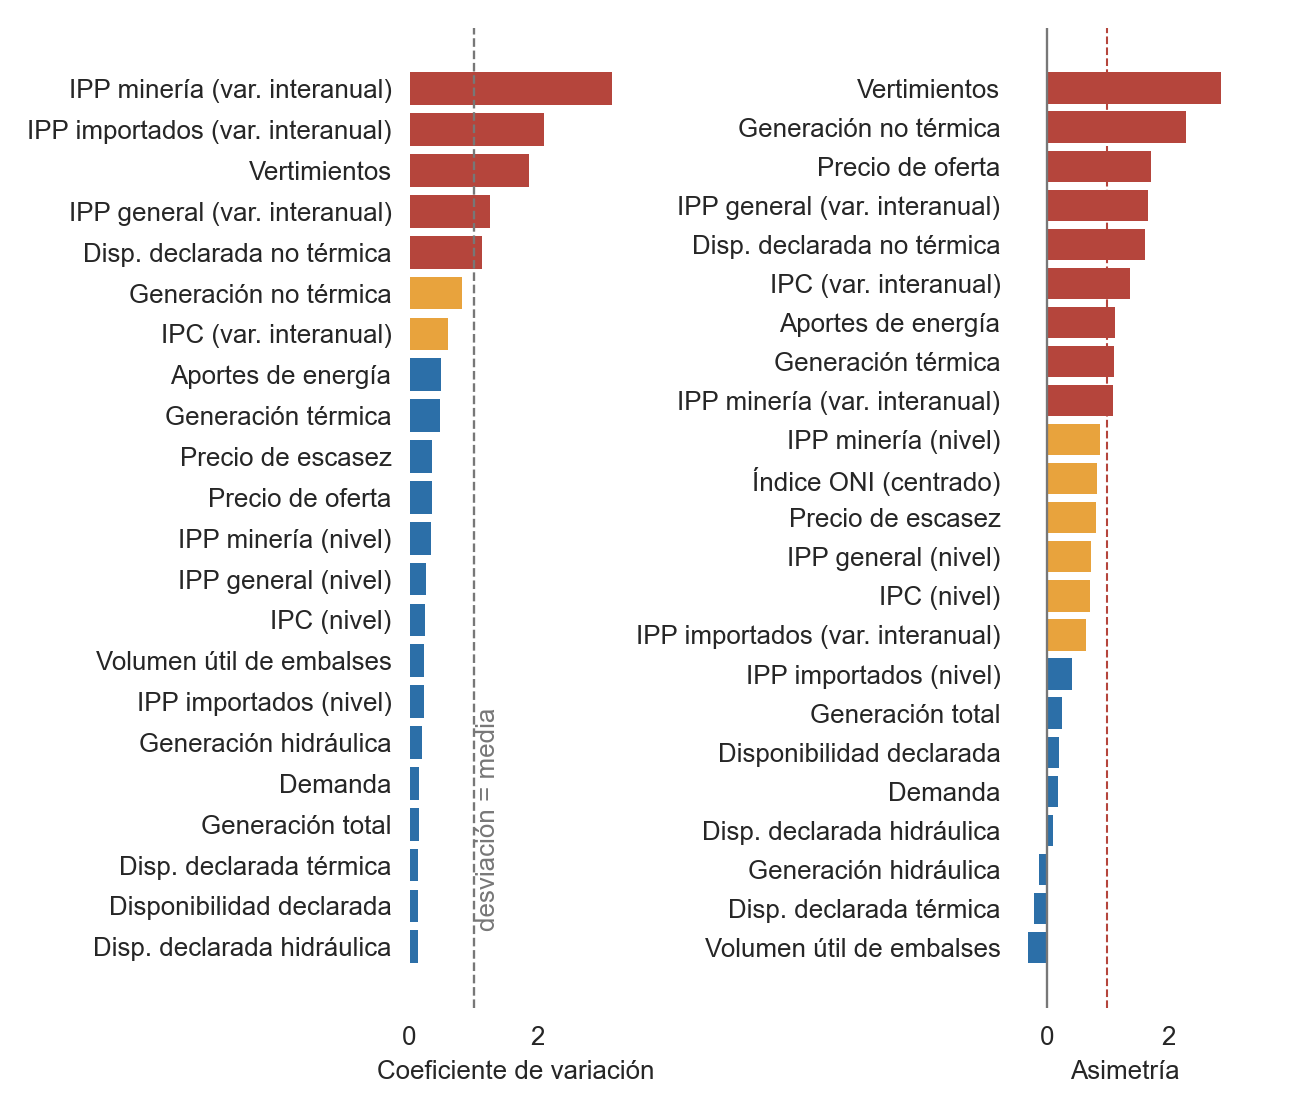

Figura guardada en C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB\datasets\procesado\3_explicativas_comparadas.png

Los dos paneles separan tres grupos:

  · Variables de sistema —demanda, generación y disponibilidad declarada— con CV por
    debajo de 0,2 y asimetría casi nula: se mueven poco y de forma simétrica.
  · Variables hidrológicas —aportes, vertimientos— con CV alto y cola larga a la derecha:
    su comportamiento es el de una variable de evento, no el de un nivel estable.
  · Índices de precios, que no son volátiles pero sí arrastran la tendencia de la economía,
    y por eso el modelado los usa en variación interanual y no en nivel.


In [30]:
# ============================================================
# 6.2 — Las explicativas, comparadas entre sí
# ============================================================
# La tabla anterior tiene veinticuatro filas y once columnas: es exacta pero no se abarca de un
# vistazo. Esta figura resume las dos dimensiones que deciden el tratamiento de una variable —
# cuánto varía y cuán torcida está su distribución — y las ordena, que es lo que permite ver
# grupos. Se excluyen del CV las variables de media cercana a cero, donde esa medida no significa
# nada (ver la advertencia de la celda anterior).
_validas = [c for c in explicativas_cont if abs(desc.loc[c, "media"]) >= desc.loc[c, "desv."] * 0.2]

# Los nombres en prosa, los mismos que emplea el cuerpo del documento. Se verifica que cubran
# TODAS las continuas: si el dataset gana una columna, la celda falla en vez de imprimir el
# nombre tecnico sin que nadie lo advierta.
# Los nombres en prosa son los de la tabla 1.1: se derivan de META para que no haya dos
# listas de nombres que puedan separarse. El assert de mas abajo sigue comprobando que
# cubran TODAS las continuas, de modo que una columna nueva detiene la celda en vez de
# imprimir el nombre tecnico sin que nadie lo advierta.
PROSA = META["nombre"].to_dict()
_faltan = [c for c in explicativas_cont if c not in PROSA]
assert not _faltan, f"sin nombre en prosa: {_faltan}"
rotulo = lambda ix: [PROSA[c] for c in ix]

# TAMAÑO DE PAGINA: 1289 px de ancho a 186 ppp, como las demas figuras del documento.
PPP_PAGINA, ANCHO_PX, ALTO_PX = 186, 1289, 186 * 6
fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PX / PPP_PAGINA, ALTO_PX / PPP_PAGINA))

_cv = desc.loc[_validas, "CV"].sort_values()
_col = ["#2c6fa8" if v < 0.5 else "#e8a33d" if v < 1 else "#b5453c" for v in _cv]
axes[0].barh(range(len(_cv)), _cv.values, color=_col)
axes[0].set_yticks(range(len(_cv)))
axes[0].set_yticklabels(rotulo(_cv.index), fontsize=10)
axes[0].set_xlabel("Coeficiente de variación", fontsize=10)
axes[0].tick_params(axis="x", labelsize=10)
axes[0].axvline(1.0, color="#777", ls="--", lw=0.9)
axes[0].annotate("desviación = media", (1.03, 0.5), fontsize=10, color="#777", rotation=90)
axes[0].grid(axis="x", alpha=0.25)
axes[0].set_facecolor("white")
for _b in ("top", "right"):
    axes[0].spines[_b].set_visible(False)

_as = desc.loc[explicativas_cont, "asimetría"].sort_values()
_cola = ["#b5453c" if v > 1 else "#e8a33d" if v > 0.5 else "#2c6fa8" for v in _as]
axes[1].barh(range(len(_as)), _as.values, color=_cola)
axes[1].set_yticks(range(len(_as)))
axes[1].set_yticklabels(rotulo(_as.index), fontsize=10)
axes[1].set_xlabel("Asimetría", fontsize=10)
axes[1].tick_params(axis="x", labelsize=10)
axes[1].axvline(0, color="#777", lw=0.9)
axes[1].axvline(1, color="#b5453c", ls="--", lw=0.8)
axes[1].grid(axis="x", alpha=0.25)
axes[1].set_facecolor("white")
for _b in ("top", "right"):
    axes[1].spines[_b].set_visible(False)

plt.tight_layout()
# Margen a la derecha: el titulo y el rotulo del panel derecho son mas anchos que su eje y
# tight_layout no los tiene en cuenta, de modo que sin esto el PDF los corta.
fig.subplots_adjust(right=0.955)
ruta_fig_exog = os.path.join(abspath, "datasets", "procesado",
                             "3_explicativas_comparadas.png")
fig.savefig(ruta_fig_exog, dpi=PPP_PAGINA, facecolor="white")
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la
# figura, que vale 100: sin esto el cuaderno guardaria una version de 696 px de la misma
# figura que el archivo de arriba escribe a 1289, y la del documento no se podria cotejar
# contra la del notebook.
fig.set_dpi(PPP_PAGINA)
plt.show();
print(f"Figura guardada en {ruta_fig_exog}\n")

print("Los dos paneles separan tres grupos:\n")
print("  · Variables de sistema —demanda, generación y disponibilidad declarada— con CV por")
print("    debajo de 0,2 y asimetría casi nula: se mueven poco y de forma simétrica.")
print("  · Variables hidrológicas —aportes, vertimientos— con CV alto y cola larga a la derecha:")
print("    su comportamiento es el de una variable de evento, no el de un nivel estable.")
print("  · Índices de precios, que no son volátiles pero sí arrastran la tendencia de la economía,")
print("    y por eso el modelado los usa en variación interanual y no en nivel.")


### 6.3 Las explicativas según la fase climática

La sección 5.4 mostró que el **precio** cambia de nivel con la fase del fenómeno ENSO.

In [31]:
# ============================================================
# 6.3 — Las explicativas según la fase ENSO
# ============================================================
# POR QUÉ ESTE CONTRASTE Y NO OTRO. La sección 5.4 mostró que el PRECIO cambia de nivel con la
# fase del fenómeno. Queda por comprobar el eslabón intermedio, que es lo que el mecanismo físico
# afirma: que la fase mueve primero a las variables del sistema y estas al precio. Si los aportes
# no cayeran durante El Niño, la relación entre fase y precio sería una coincidencia estadística.
#
# Se usa la MEDIANA y no la media, porque varias de estas variables tienen cola larga, y la
# versión CENTRADA del índice, que es la que describe qué fase hubo realmente cada día.
_fase_desc = pd.Series(
    np.select([df["indice_ONI"] >= 0.5, df["indice_ONI"] <= -0.5], ["El Niño", "La Niña"],
              "Neutral"), index=df.index, name="fase")

_sistema = [c for c in ["aportes_energia", "vol_util", "vertimientos", "gen_hidraulica",
                        "gen_termica", "precio_oferta", "precio_escasez"] if c in df.columns]
_med = df[_sistema].groupby(_fase_desc).median().reindex(orden_enso)
_rel = (_med / _med.loc["Neutral"] * 100 - 100).round(1)

print("Mediana de cada variable por fase:\n")
display(_med.round(0))
print("\nVariación frente a la fase Neutral, en porcentaje:\n")
display(_rel)

print("\nEl eslabón intermedio queda medido:\n")
_a = _rel.loc["El Niño", "aportes_energia"]
_t = _rel.loc["El Niño", "gen_termica"]
_v = _med.loc["El Niño", "vertimientos"]
print(f"  · Durante El Niño los aportes de energía caen un {abs(_a):.0f} % respecto de la fase")
print(f"    neutral y la generación térmica sube un {_t:.0f} %: el déficit hídrico se cubre")
print("    despachando plantas más costosas, que es lo que eleva el precio.")
print(f"  · Los vertimientos tienen mediana {_v:.0f} durante El Niño, es decir, más de la mitad")
print("    de esos días no se vierte nada: el sistema deja de tener agua sobrante.")
print("  · Durante La Niña el movimiento es el contrario y de menor magnitud, lo que es coherente")
print("    con que el embalse amortigua el exceso mejor que el déficit.")


Mediana de cada variable por fase:



,aportes_energia,vol_util,vertimientos,gen_hidraulica,gen_termica,precio_oferta,precio_escasez
fase,,,,,,,
La Niña,167855900.0,1.219887e+10,4840510.0,149061976.0,28599577.0,275.0,454.0
Neutral,167295900.0,1.077291e+10,2508570.0,145719457.0,33541576.0,325.0,456.0
El Niño,112760050.0,1.052259e+10,0.0,134306684.0,53312085.0,335.0,489.0



Variación frente a la fase Neutral, en porcentaje:



,aportes_energia,vol_util,vertimientos,gen_hidraulica,gen_termica,precio_oferta,precio_escasez
fase,,,,,,,
La Niña,0.3,13.2,93.0,2.3,-14.7,-15.3,-0.4
Neutral,0.0,0.0,0.0,0.0,0.0,0.0,0.0
El Niño,-32.6,-2.3,-100.0,-7.8,58.9,3.2,7.3



El eslabón intermedio queda medido:

  · Durante El Niño los aportes de energía caen un 33 % respecto de la fase
    neutral y la generación térmica sube un 59 %: el déficit hídrico se cubre
    despachando plantas más costosas, que es lo que eleva el precio.
  · Los vertimientos tienen mediana 0 durante El Niño, es decir, más de la mitad
    de esos días no se vierte nada: el sistema deja de tener agua sobrante.
  · Durante La Niña el movimiento es el contrario y de menor magnitud, lo que es coherente
    con que el embalse amortigua el exceso mejor que el déficit.


### 6.4 La forma de cada distribución

La sección 2 caracteriza la distribución de la variable objetivo con un histograma y un diagrama de caja.

Rejilla: 7 bloques de familia, 23 paneles en 6 filas de 4; 1 celda(s) sin usar.


Títulos: 5 encogidos para que quepan (Disp. declarada no térmica a 9.9; Disponibilidad declarada a 9.8; IPP general (var. interanual) a 8.6; IPP importados (var. interanual) a 8.4; IPP minería (var. interanual) a 8.6); cuerpo mínimo 8.4 pt; 0 se salen de su panel.


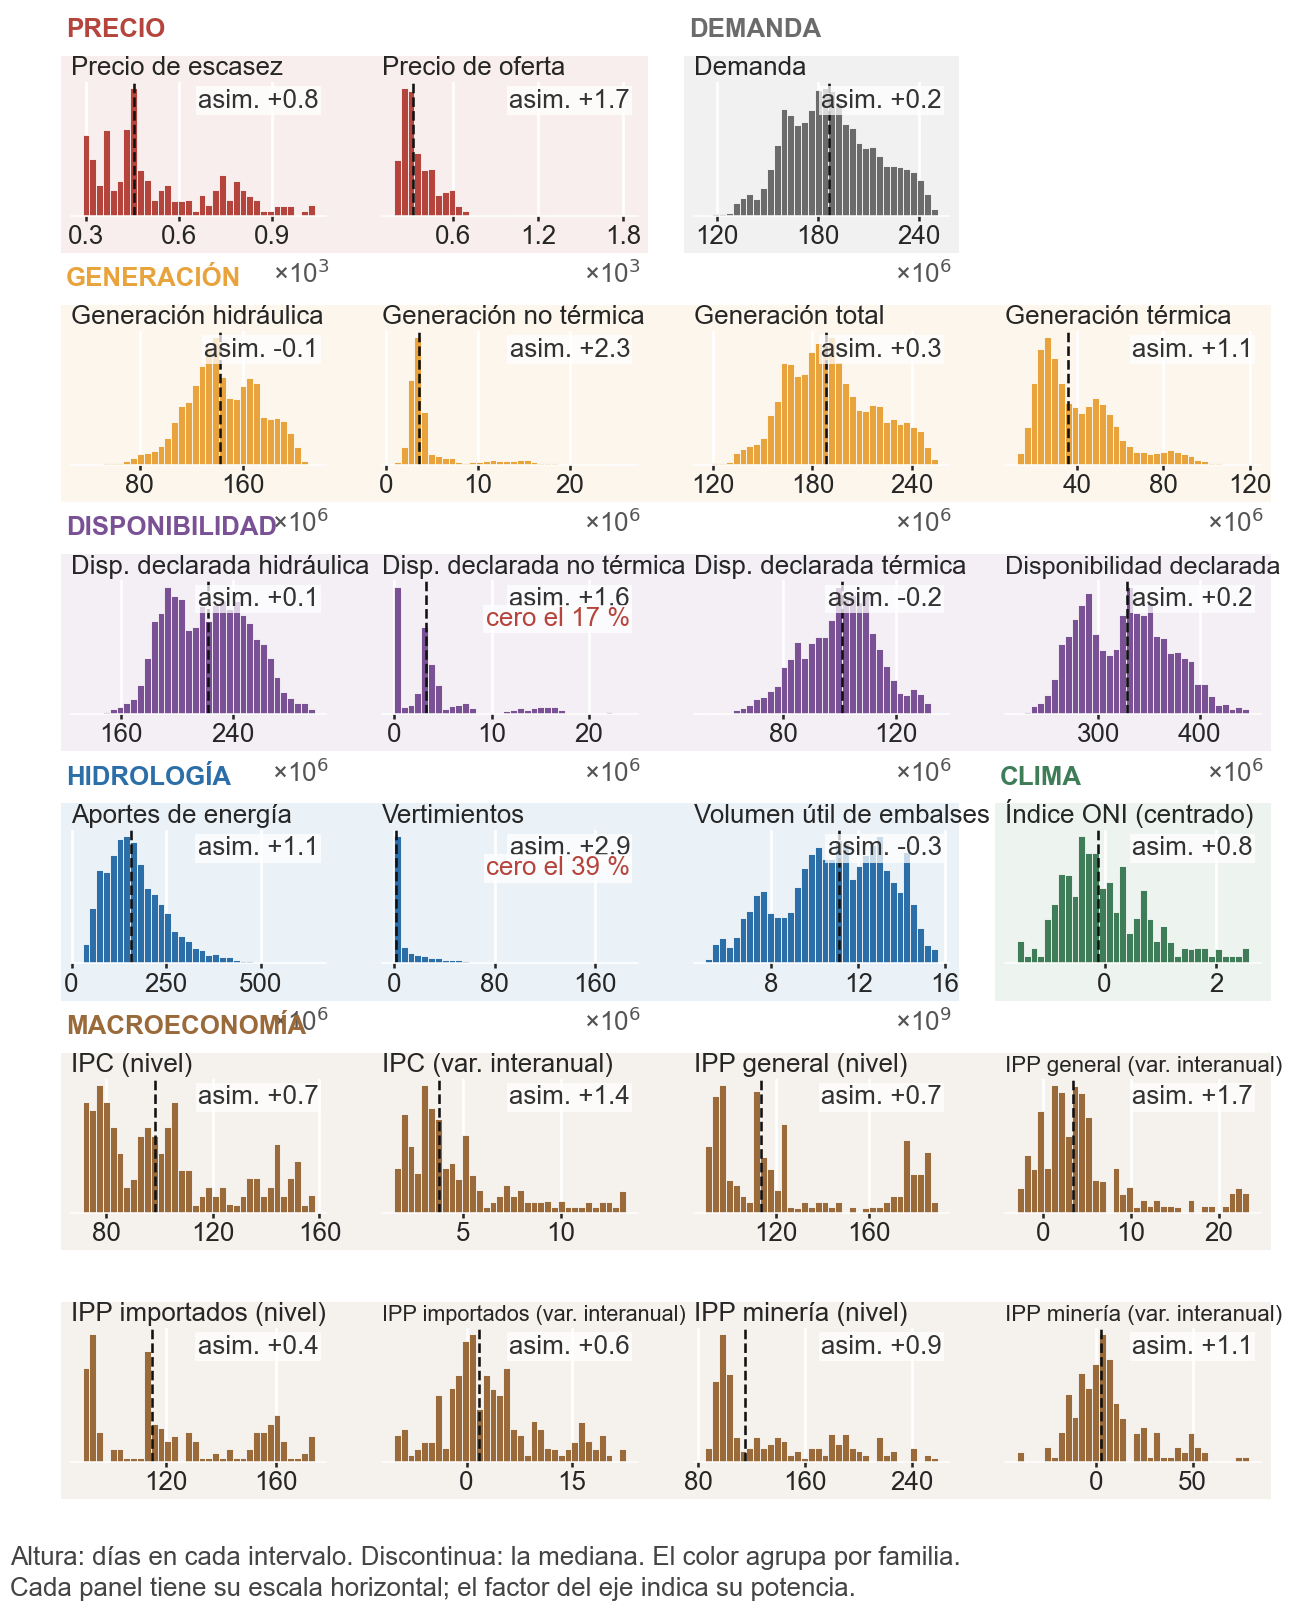


Lo que la figura destapa y la tabla de momentos no dejaba ver:

  · Las tres distribuciones más torcidas hacia la derecha: Vertimientos, Generación no térmica, Precio de oferta (asimetría 2.9, 2.3 y 1.7).
    Son las mismas que la sección 7 encuentra con Spearman por encima de Pearson: una cola
    larga rompe la linealidad que Pearson supone, no la monotonía que Spearman mide.
  · 8 de las 23 tienen asimetría por debajo de 0,5 en valor
    absoluto, es decir una distribución casi simétrica.
  · 2 variables tienen una barra en el cero que no es parte de la
    distribución, sino los días en que el fenómeno no ocurrió:
      Disp. declarada no térmica: 17 % de los días
      Vertimientos: 39 % de los días
    Un modelo que las lea como una variable continua cualquiera interpreta ese cero como
    un valor bajo, y por eso el modelado las acompaña de un indicador binario.
  · Las 8 series macroeconómicas tienen la forma escalonada que les impone
    su publicación mensual: el mismo valor

In [32]:
# ============================================================
# 6.4 — La forma de la distribución de cada variable explicativa
# ============================================================
# POR QUÉ UN EJE POR PANEL Y NO UNO COMPARTIDO. La primera versión llevó las veintitrés variables
# a una base robusta común —mediana y rango intercuartílico— y las puso en un mismo diagrama de
# cajas. No funcionó: dos variables tienen colas que llegan a quince desviaciones
# intercuartílicas, de modo que el eje tenía que estirarse hasta ahí y las veintiuna restantes
# quedaban aplastadas contra el origen, que es exactamente lo contrario de lo que la figura
# buscaba. La comparación de magnitudes ya está resuelta en la tabla de 6.1 y en el coeficiente
# de variación de 6.2; aquí lo que hay que ver es la FORMA, y para eso cada panel necesita su
# propia escala.
#
# POR QUÉ LOS PANELES VAN EN BLOQUES POR FAMILIA. Las veintitrés variables no son veintitrés
# cosas independientes: son siete grupos que comparten origen, unidad y mecanismo físico, y la
# pregunta que la figura contesta se hace DENTRO del grupo —¿la generación térmica tiene la misma
# forma que la hidráulica?, ¿el nivel de un índice se parece a su variación?— mucho más que entre
# grupos. Una rejilla corrida de cuatro columnas corta esos grupos a mitad de fila y obliga a
# reconstruirlos con la vista. Aquí cada familia ocupa un bloque contiguo, con su nombre encima y
# un fondo tenue de su color, y solo salta de fila cuando no cabe entera en lo que queda de la
# actual. El reparto se calcula, no se escribe: si una familia gana o pierde una variable, el
# bloque se reacomoda solo.
#
# CÓMO SE REPARTE EL ALTO, que es lo que decide si la distribución se lee. El alto de un panel se
# gasta en tres cosas que no son el dibujo: el título, las marcas del eje horizontal y el hueco
# que separa una fila de la siguiente. Si se fija el alto TOTAL y se deja que el ajuste
# automático reparta, esos tres se llevan casi la mitad y las barras quedan en algo más de medio
# centímetro. Por eso aquí se declara en pulgadas lo que mide cada cosa —el alto del dibujo, el
# hueco entre filas, la cabecera y el pie— y el alto de la figura se DEDUCE de esa suma. El
# dibujo de cada panel se queda con nueve décimas de pulgada, que es lo que hace falta para
# distinguir una cola larga de una campana.
#
# LA FIGURA ES DE ANCHO DE PÁGINA: 6,93 pulgadas de ancho a 186 ppp, que es el ancho útil de la
# página del documento. Las dos cosas importan por separado. El TAMAÑO EN PULGADAS decide el
# tamaño relativo del texto: una figura dibujada a 15 pulgadas y luego encogida a 6,93 deja la
# letra al 46 % de lo previsto, que es la razón por la que varias figuras del documento se leen
# mal. La RESOLUCIÓN decide los puntos por pulgada, y el figsize no la fija: el cuaderno guarda
# la imagen con la resolución DE LA FIGURA, que vale 100 mientras no se diga otra cosa, de modo
# que sin tocarla esta figura entraría al documento con poco más de la mitad de los puntos que
# tienen las demás. Se fija con fig.set_dpi justo antes de mostrarla; savefig.dpi NO sirve aquí,
# porque el backend del cuaderno pasa la resolución de la figura de forma explícita y lo ignora.
PPP_PAGINA, ANCHO_PX = 186, 1289
COLOR_FAMILIA = {"Precio": "#b5453c", "Demanda": "#6b6b6b", "Generación": "#e8a33d",
                 "Disponibilidad": "#7a5195", "Hidrología": "#2c6fa8", "Clima": "#3f7d58",
                 "Macroeconomía": "#9a6a3a", "Calendario": "#999999"}

# Las mismas explicativas continuas de 6.1, ordenadas por familia para que los bloques se lean
# juntos. El orden lo da META, de modo que la figura y la tabla 1.1 no pueden discrepar.
_orden_fig = [c for c in META.index if c in explicativas_cont]
assert len(_orden_fig) == len(explicativas_cont), "6.4 no cubre todas las explicativas de 6.1"


def _escala(valores):
    """Potencia de mil con la que dividir el eje, y su etiqueta.

    Las series de energía están en kWh y llegan a 1e8: sin esto cada panel imprime su propio
    desplazamiento en notación científica y la rejilla se vuelve ilegible. Se divide por una
    potencia de MIL —no de diez cualquiera— para que el exponente sea el de los múltiplos
    habituales y el mismo en paneles de la misma familia.

    La etiqueta va DEBAJO DEL EJE y no en el título. Pegada al nombre lo alargaba seis
    caracteres, y con nombres como «Disp. declarada no térmica» eso basta para que el título no
    quepa en el panel; además el factor describe la escala horizontal, que es donde se lee.
    """
    m = float(np.nanmax(np.abs(valores)))
    if m == 0 or not np.isfinite(m):
        return 1.0, ""
    exp = int(np.floor(np.log10(m)) // 3 * 3)
    return (10.0 ** exp, f"×10$^{{{exp}}}$") if exp >= 3 else (1.0, "")


from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

# Las variables de cada familia, en el orden de META. Una familia sin variables continuas
# —el calendario— no ocupa bloque.
_FAM_FIG = [(f, [c for c in _orden_fig if META.loc[c, "familia"] == f]) for f in ORDEN_FAMILIAS]
_FAM_FIG = [(f, cs) for f, cs in _FAM_FIG if cs]
assert sum(len(cs) for _, cs in _FAM_FIG) == len(_orden_fig), \
    "alguna explicativa no cae en ninguna de las familias declaradas en 1.1"

# REPARTO EN LA REJILLA. Una familia empieza fila nueva solo si no cabe entera en lo que queda de
# la actual; las que no caben en una fila completa —la macroeconomía, con ocho— se parten por el
# borde de la fila, nunca por el medio. Así ninguna familia aparece cortada a mitad de renglón.
N_COL = 4
_sitio, _fil, _col = {}, 0, 0
for _f, _cs in _FAM_FIG:
    if _col and N_COL - _col < min(len(_cs), N_COL):
        _fil, _col = _fil + 1, 0
    _sitio[_f] = []
    for _c in _cs:
        _sitio[_f].append((_fil, _col, _c))
        _col += 1
        if _col == N_COL:
            _fil, _col = _fil + 1, 0
N_FIL = max(f for v in _sitio.values() for f, _, _ in v) + 1
print(f"Rejilla: {len(_FAM_FIG)} bloques de familia, {len(_orden_fig)} paneles en "
      f"{N_FIL} filas de {N_COL}; {N_FIL * N_COL - len(_orden_fig)} celda(s) sin usar.")

# Todo en pulgadas: el alto de la figura es la SUMA de estas piezas, no un número elegido.
#   ALTO_DIBUJO  lo que mide el histograma de un panel, sin título ni marcas
#   HUECO        separa dos filas: marcas de la de arriba + nombre de familia + título de la de abajo
#   CABEZA       título de la figura + nombre y título de la primera fila
#   PIE          marcas de la última fila + la nota de lectura
ALTO_DIBUJO, HUECO, CABEZA, PIE = 0.72, 0.62, 0.44, 0.78
ALTO_IN = CABEZA + N_FIL * ALTO_DIBUJO + (N_FIL - 1) * HUECO + PIE
_pg = lambda pulgadas: pulgadas / ALTO_IN          # pulgadas -> fracción de alto de figura

fig = plt.figure(figsize=(ANCHO_PX / PPP_PAGINA, ALTO_IN))
gs = fig.add_gridspec(N_FIL, N_COL, left=0.055, right=0.978,
                      top=1 - _pg(CABEZA), bottom=_pg(PIE),
                      hspace=HUECO / ALTO_DIBUJO, wspace=0.22)

# El fondo del bloque y el nombre de la familia. Se dibuja ANTES de los paneles y con zorder 0
# para que quede por debajo; los ejes se dejan transparentes y el color del bloque hace de fondo.
for _f, _celdas in _sitio.items():
    _por_fila = {}
    for _fl, _cl, _c in _celdas:
        _por_fila.setdefault(_fl, []).append(_cl)
    for _k, _fl in enumerate(sorted(_por_fila)):
        _cs = sorted(_por_fila[_fl])
        _p0 = gs[_fl, _cs[0]].get_position(fig)
        _p1 = gs[_fl, _cs[-1]].get_position(fig)
        _x0, _x1 = _p0.x0 - 0.008, _p1.x1 + 0.008
        # el fondo baja hasta debajo de las marcas del eje y del factor de escala, que son parte
        # del panel, y sube lo justo para cubrir el título
        _y0, _y1 = _p0.y0 - _pg(0.20), _p0.y1 + _pg(0.14)
        fig.add_artist(Rectangle((_x0, _y0), _x1 - _x0, _y1 - _y0, transform=fig.transFigure,
                                 facecolor=COLOR_FAMILIA[_f], alpha=0.09, edgecolor="none",
                                 zorder=0))
        if _k == 0:     # el nombre va una sola vez, encima de la primera fila del bloque
            fig.text(_x0 + 0.004, _y1 + _pg(0.075), _f.upper(), fontsize=10, weight="bold",
                     color=COLOR_FAMILIA[_f], va="bottom", ha="left")

_paneles, _titulo = [], {}
for _f, _celdas in _sitio.items():
    for _fl, _cl, c in _celdas:
        ax = fig.add_subplot(gs[_fl, _cl])
        _paneles.append((_fl, _cl, c, ax))
        div, factor = _escala(df[c].values)
        # Treinta y cuatro intervalos y no más: con el ancho de panel de la rejilla, cada barra
        # mide medio milímetro en el documento y la forma se lee mejor con barras anchas que con
        # el detalle fino, que aquí no se puede resolver.
        ax.hist(df[c].values / div, bins=34, color=COLOR_FAMILIA[_f],
                edgecolor="white", linewidth=0.3)
        ax.axvline(df[c].median() / div, color="#111", lw=1.0, ls="--")
        # El objeto del título se guarda: con loc="left" el artista NO es ax.title —que es el
        # título centrado, vacío— sino otro, y el ajuste de más abajo tiene que medir este.
        _titulo[ax] = ax.set_title(META.loc[c, "nombre"], fontsize=10, pad=2.6, loc="left")
        # La asimetría es el número que decide si la variable entra transformada: va en el panel.
        # SOBRE UN FONDO, porque con letra del cuerpo la anotacion cae encima de las barras
        # en los paneles cuya distribucion llega arriba a la derecha y deja de leerse.
        _fondo = dict(facecolor="white", edgecolor="none", alpha=0.75, pad=0.9)
        ax.annotate(f"asim. {df[c].skew():+.1f}", (0.97, 0.95), xycoords="axes fraction",
                    ha="right", va="top", fontsize=10, color="#333", bbox=_fondo)
        _pc = (df[c] == 0).mean() * 100
        if _pc > 1:
            ax.annotate(f"cero el {_pc:.0f} %", (0.97, 0.80), xycoords="axes fraction",
                        ha="right", va="top", fontsize=10, color="#b5453c", bbox=_fondo)
        # Con la letra del cuerpo del documento y 1,6 pulgadas de panel, las marcas
        # automaticas se solapan: se piden menos. Tres bastan para leer la escala, que es
        # para lo que esta el eje aqui.
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
        ax.tick_params(axis="x", labelsize=10, length=2, pad=1.5)
        if factor:      # la potencia de la escala, al final del eje y en la línea de las marcas
            ax.annotate(factor, (1.0, 0.0), xycoords="axes fraction", xytext=(1, -17.0),
                        textcoords="offset points", ha="right", va="top", fontsize=10,
                        color="#555")
        # El eje vertical es una frecuencia que no se compara entre paneles: sus números solo
        # ocuparían sitio. Se deja el eje sin marcas y se dice en el pie qué representa.
        ax.set_yticks([])
        for lado in ("top", "right", "left"):
            ax.spines[lado].set_visible(False)
        ax.spines["bottom"].set_linewidth(0.6)
        ax.patch.set_visible(False)      # el fondo lo pone el bloque de la familia

# NINGÚN TÍTULO PUEDE SALIRSE DE SU SITIO. Varios nombres de 1.1 son más largos que el panel
# —«Disp. declarada no térmica (×10⁶)» o «IPP importados (var. interanual)»— y matplotlib no los
# recorta ni los encoge: los dibuja encima del panel vecino, y en la última columna fuera de la
# figura. Se mide cada título con el renderizador y se le baja el cuerpo hasta que cabe entre el
# borde de su panel y el del siguiente, con 8 puntos de suelo: dos por debajo del cuerpo del
# documento es lo mas que se admite, y la celda avisa de cada nombre que no llegue a 10.
fig.canvas.draw()
_ren = fig.canvas.get_renderer()
_tope = {}
for _fl, _cl, _c, _ax in _paneles:
    _vec = [a for f2, c2, _, a in _paneles if f2 == _fl and c2 == _cl + 1]
    _tope[_ax] = (_vec[0].get_window_extent(_ren).x0 - 3) if _vec \
        else fig.get_figwidth() * fig.dpi - 3
_menor, _encogidos = 10.0, []
for _fl, _cl, _c, _ax in _paneles:
    _t = _titulo[_ax]
    while _t.get_fontsize() > 8.0 and _t.get_window_extent(_ren).x1 > _tope[_ax]:
        _t.set_fontsize(round(_t.get_fontsize() - 0.1, 2))
    if _t.get_fontsize() < 10.0:
        _encogidos.append(f"{META.loc[_c, 'nombre']} a {_t.get_fontsize():.1f}")
    _menor = min(_menor, _t.get_fontsize())
_fuera = [META.loc[_c, "nombre"] for _fl, _cl, _c, _ax in _paneles
          if _titulo[_ax].get_window_extent(_ren).x1 > _tope[_ax]]
print(f"Títulos: {len(_encogidos)} encogidos para que quepan ({'; '.join(_encogidos) or 'ninguno'})"
      f"; cuerpo mínimo {_menor:.1f} pt; {len(_fuera)} se salen de su panel.")
assert not _fuera, f"títulos recortados: {_fuera}"

# El nombre de cada bloque sustituye a la leyenda de colores: decía lo mismo en letra más
# pequeña y a media página de distancia del panel que describía.
fig.suptitle("", fontsize=10,
             x=0.008, ha="left", y=0.998)
fig.text(0.008, _pg(0.035),
         "Altura: días en cada intervalo. Discontinua: la mediana. El color agrupa por familia.\n"
         "Cada panel tiene su escala horizontal; el factor del eje indica su potencia.",
         fontsize=10, color="#444", va="bottom", linespacing=1.35)
fig.patch.set_facecolor("white")
fig.set_dpi(PPP_PAGINA)
plt.show()

print("\nLo que la figura destapa y la tabla de momentos no dejaba ver:\n")
_asim = desc.loc[_orden_fig, "asimetría"].sort_values(ascending=False)
print(f"  · Las tres distribuciones más torcidas hacia la derecha: "
      f"{', '.join(META.loc[v, 'nombre'] for v in _asim.head(3).index)} "
      f"(asimetría {_asim.iloc[0]:.1f}, {_asim.iloc[1]:.1f} y {_asim.iloc[2]:.1f}).")
print("    Son las mismas que la sección 7 encuentra con Spearman por encima de Pearson: una cola")
print("    larga rompe la linealidad que Pearson supone, no la monotonía que Spearman mide.")
_sim = _asim[_asim.abs() < 0.5]
print(f"  · {len(_sim)} de las {len(_orden_fig)} tienen asimetría por debajo de 0,5 en valor")
print("    absoluto, es decir una distribución casi simétrica.")
_con_ceros = [c for c in _orden_fig if (df[c] == 0).mean() > 0.01]
print(f"  · {len(_con_ceros)} variables tienen una barra en el cero que no es parte de la")
print("    distribución, sino los días en que el fenómeno no ocurrió:")
for c in _con_ceros:
    print(f"      {META.loc[c, 'nombre']}: {(df[c] == 0).mean() * 100:.0f} % de los días")
print("    Un modelo que las lea como una variable continua cualquiera interpreta ese cero como")
print("    un valor bajo, y por eso el modelado las acompaña de un indicador binario.")
_bimodal = [c for c in _orden_fig if META.loc[c, "familia"] == "Macroeconomía"]
print(f"  · Las {len(_bimodal)} series macroeconómicas tienen la forma escalonada que les impone")
print("    su publicación mensual: el mismo valor se repite unos treinta días, de modo que su")
print("    histograma cuenta meses y no días.")

## 7. Relación de cada variable con `precio_bolsa`

Se calcula la matriz de correlación completa (correlación lineal de Pearson) y luego se ordenan las variables explicativas según qué tan correlacionadas están con el precio de bolsa.

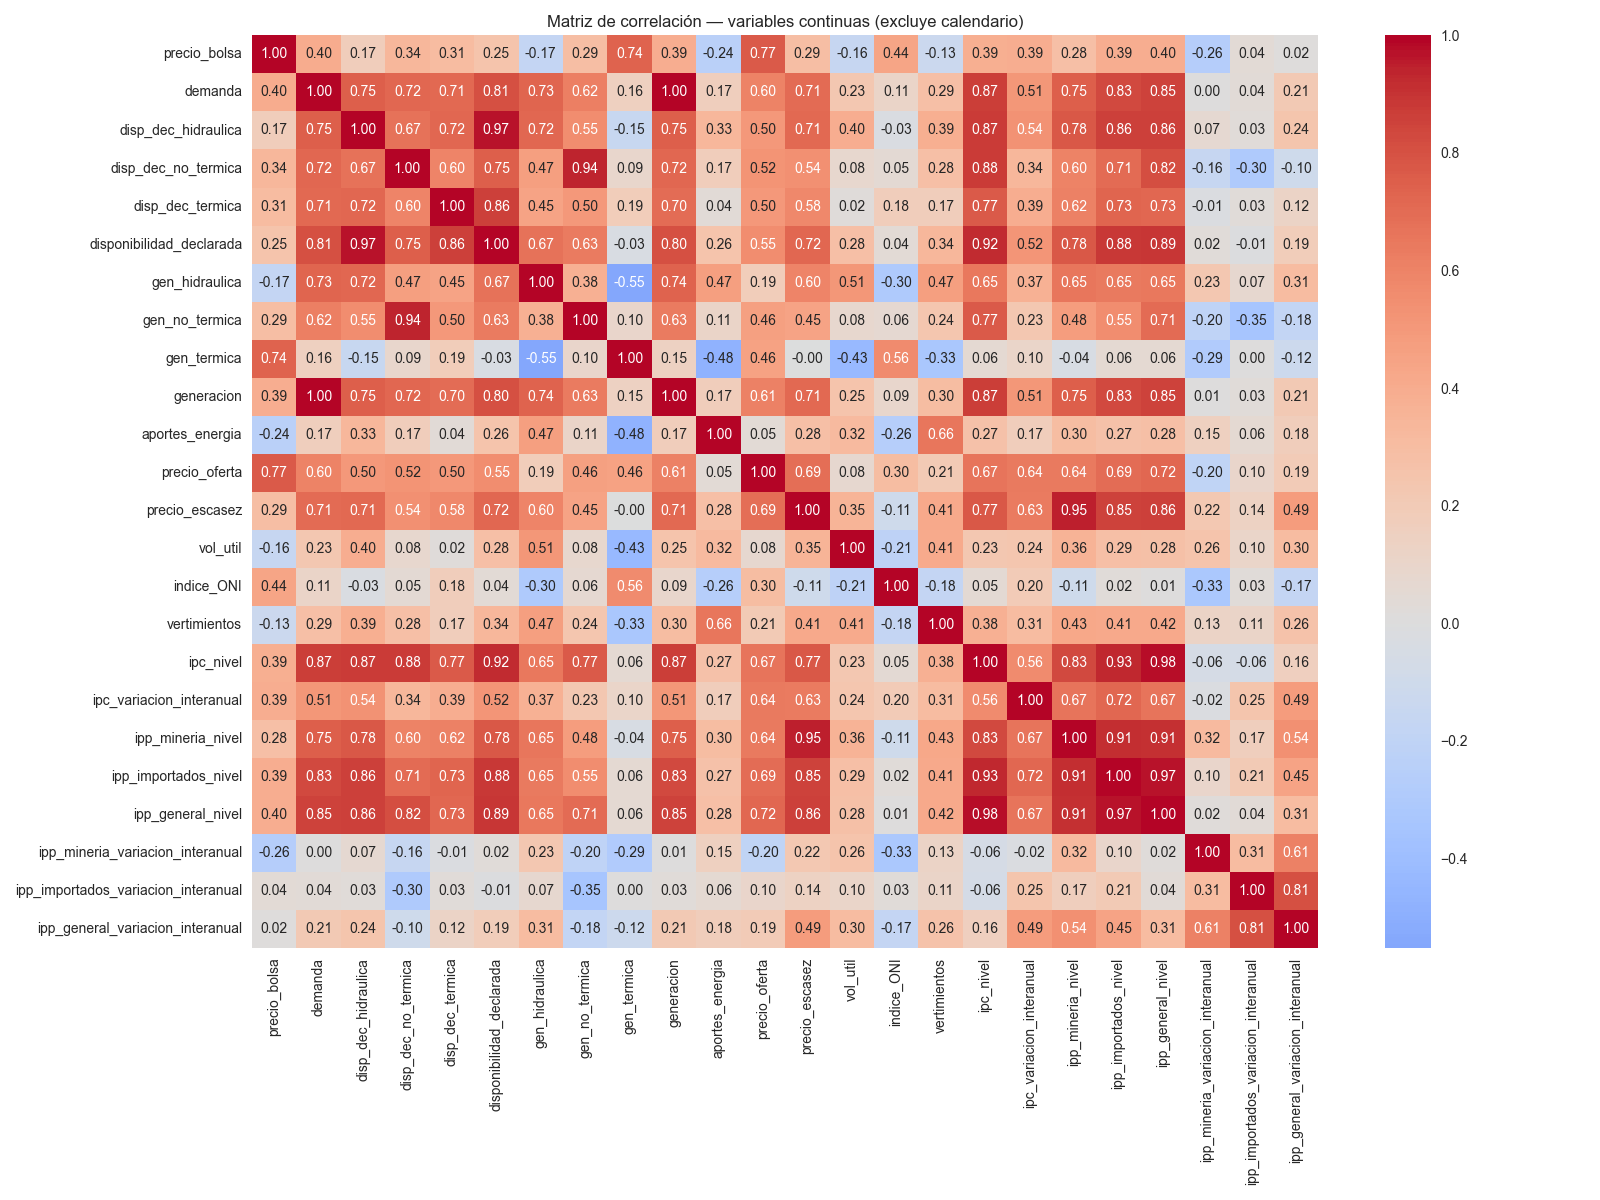

In [33]:
# ============================================================
# Matriz de correlación (excluye variables de calendario)
# ============================================================
df_continuas = df.drop(columns=CALENDARIO_COLS)
matriz_corr = df_continuas.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación — variables continuas (excluye calendario)")
plt.tight_layout()
plt.show()

C:\Users\Windows 10 Pro\AppData\Local\Temp\ipykernel_23144\3663433853.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_ordenada.values, y=corr_ordenada.index, palette=colores)


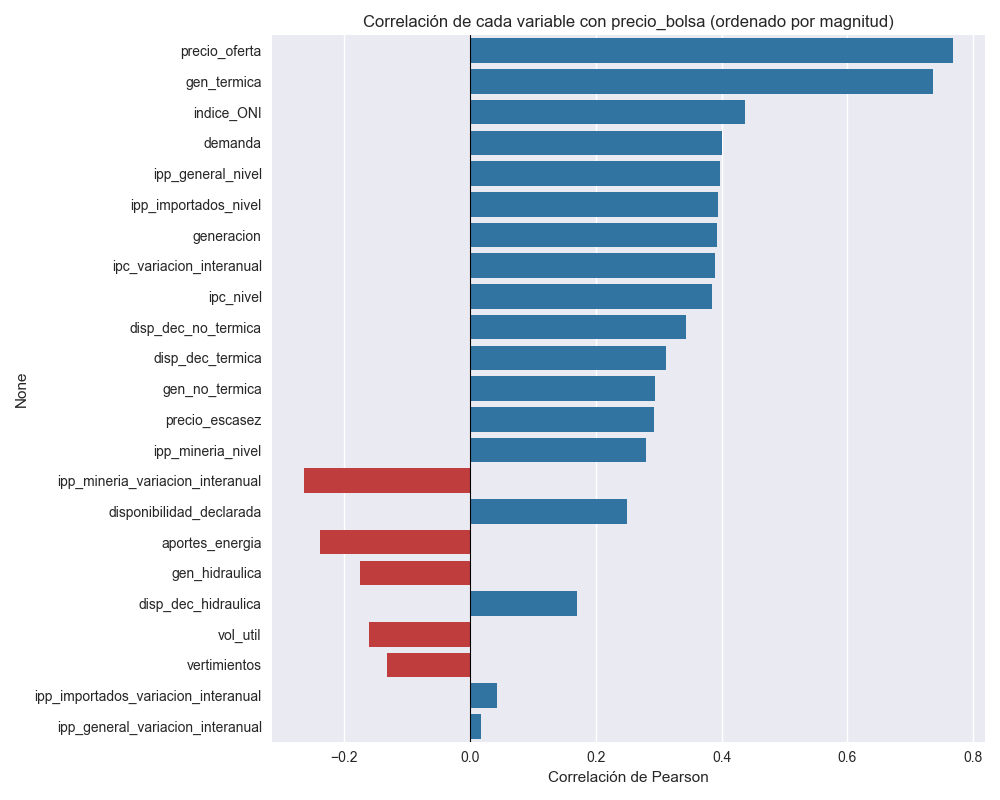

,correlacion_con_precio_bolsa
precio_oferta,0.767281
gen_termica,0.736851
indice_ONI,0.436512
demanda,0.400299
ipp_general_nivel,0.397341
ipp_importados_nivel,0.394127
generacion,0.392267
ipc_variacion_interanual,0.390101
ipc_nivel,0.385526
disp_dec_no_termica,0.342754


In [34]:
# ============================================================
# Ranking de correlación (valor absoluto) con precio_bolsa
# ============================================================
corr_con_target = matriz_corr["precio_bolsa"].drop("precio_bolsa")
corr_ordenada = corr_con_target.reindex(corr_con_target.abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 8))
colores = ["#d62728" if v < 0 else "#1f77b4" for v in corr_ordenada]
sns.barplot(x=corr_ordenada.values, y=corr_ordenada.index, palette=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable con precio_bolsa (ordenado por magnitud)")
plt.xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()

corr_ordenada.to_frame(name="correlacion_con_precio_bolsa")

### Correlación de Spearman (complemento a Pearson)

**Por qué no basta con Pearson.** El coeficiente de Pearson mide únicamente la parte **lineal** de la asociación: cuánto sube una variable cuando la otra sube, suponiendo que la proporción es constante.

$$\rho_{Spearman} = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

In [35]:
# ============================================================
# Correlación de Spearman con precio_bolsa, comparada con Pearson
# ============================================================
corr_spearman = df_continuas.drop(columns=["precio_bolsa"]).apply(
    lambda col: spearmanr(col, df_continuas["precio_bolsa"]).correlation
)

comparacion_corr = pd.DataFrame({
    "pearson": corr_con_target,
    "spearman": corr_spearman,
})
comparacion_corr["diferencia_abs"] = (comparacion_corr["spearman"].abs() - comparacion_corr["pearson"].abs())
comparacion_corr = comparacion_corr.reindex(
    comparacion_corr["spearman"].abs().sort_values(ascending=False).index
)

print("Variables donde Spearman supera a Pearson por más de 0.05 en valor absoluto")
print("(posible relación monótona no lineal que Pearson subestima):")
print(comparacion_corr[comparacion_corr["diferencia_abs"] > 0.05])
print()
comparacion_corr

Variables donde Spearman supera a Pearson por más de 0.05 en valor absoluto
(posible relación monótona no lineal que Pearson subestima):
                                   pearson  spearman  diferencia_abs
disp_dec_termica                  0.312214  0.423470        0.111255
disp_dec_no_termica               0.342754  0.422032        0.079278
gen_no_termica                    0.293955  0.381213        0.087258
ipp_mineria_variacion_interanual -0.263933 -0.362878        0.098946
aportes_energia                  -0.238763 -0.361396        0.122633
vertimientos                     -0.132631 -0.325109        0.192478
disponibilidad_declarada          0.250134  0.307811        0.057678
vol_util                         -0.160164 -0.293936        0.133773



,pearson,spearman,diferencia_abs
gen_termica,0.736851,0.754673,0.017822
precio_oferta,0.767281,0.710203,-0.057079
demanda,0.400299,0.444439,0.044140
indice_ONI,0.436512,0.426180,-0.010332
ipc_nivel,0.385526,0.424091,0.038565
generacion,0.392267,0.423724,0.031457
disp_dec_termica,0.312214,0.423470,0.111255
disp_dec_no_termica,0.342754,0.422032,0.079278
ipp_importados_nivel,0.394127,0.417853,0.023726
ipp_general_nivel,0.397341,0.388890,-0.008450


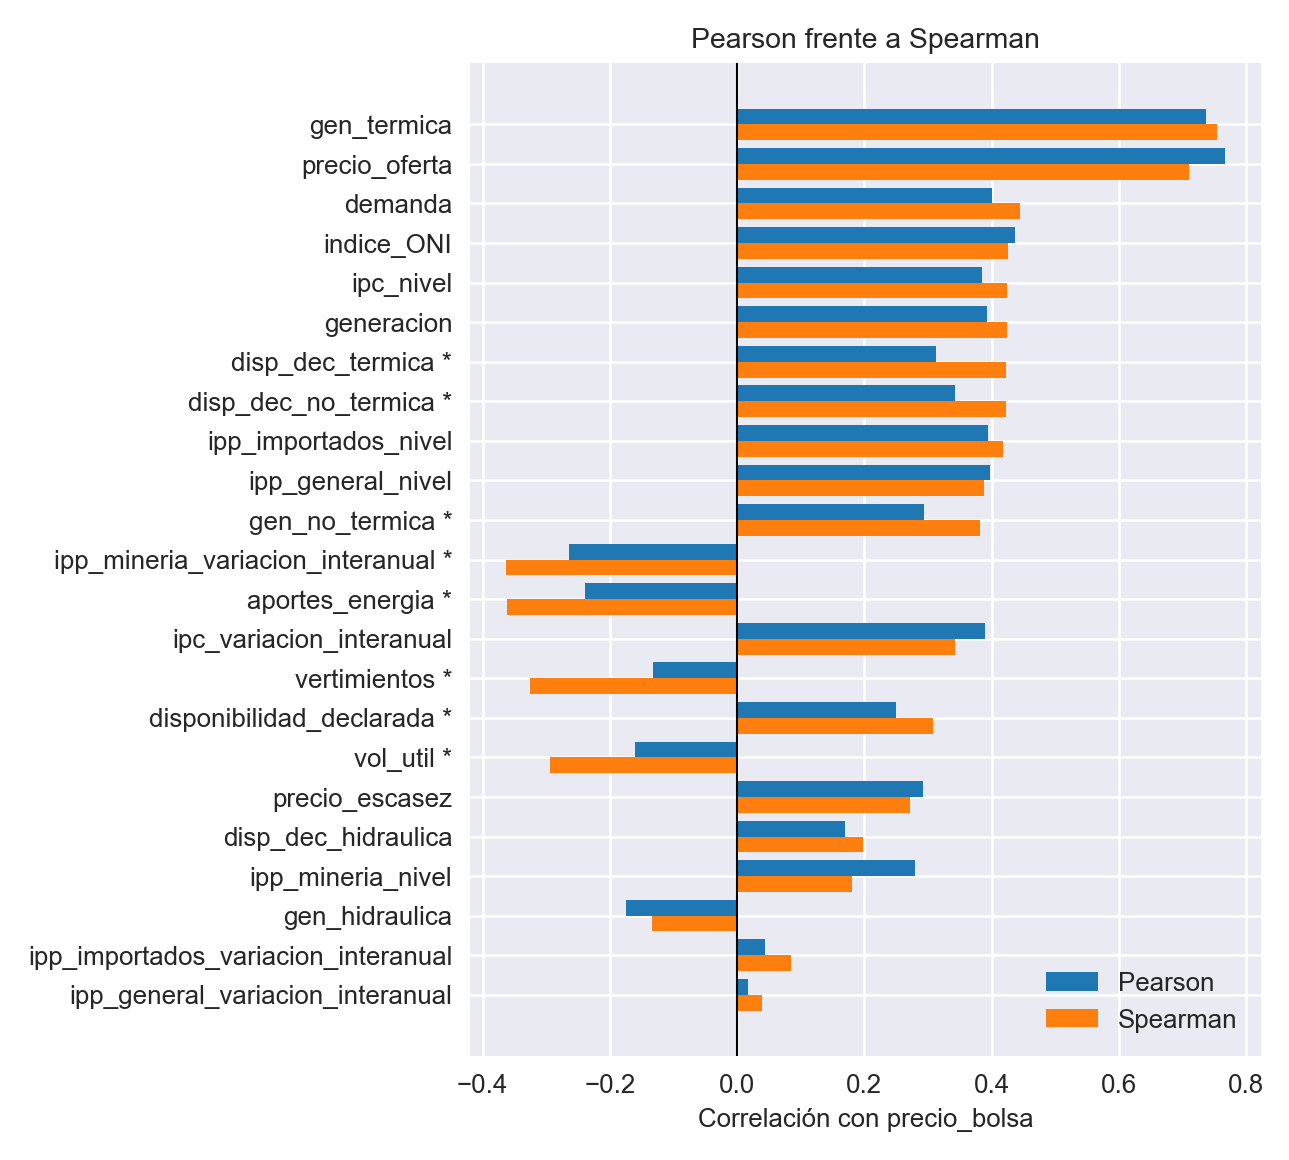

Correlaciones positivas: 18 | negativas: 5


In [36]:
# ============================================================
# Comparación visual Pearson vs. Spearman con precio_bolsa
# ============================================================
# Mismo orden que la tabla de arriba (por |Spearman|). Se marcan con * las variables en
# las que Spearman supera a Pearson en más de UMBRAL_DIF (relación monótona no lineal).
UMBRAL_DIF = 0.05

comp = comparacion_corr[["pearson", "spearman"]]
marcadas = comparacion_corr.index[comparacion_corr["diferencia_abs"] > UMBRAL_DIF]
etiquetas = [f"{v} *" if v in marcadas else v for v in comp.index]

fig, ax = plt.subplots(figsize=(ANCHO_PAGINA, alto_pagina(10, 9)))
posiciones = np.arange(len(comp))
ax.barh(posiciones - 0.2, comp["pearson"], height=0.4, color="#1f77b4", label="Pearson")
ax.barh(posiciones + 0.2, comp["spearman"], height=0.4, color="#ff7f0e", label="Spearman")
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación con precio_bolsa")
ax.set_title("Pearson frente a Spearman")
ax.legend(loc="lower right")
a_escala(fig)
plt.tight_layout()
plt.show()

print(f"Correlaciones positivas: {(comp['spearman'] > 0).sum()} | negativas: {(comp['spearman'] < 0).sum()}")

**Lectura de la comparación.** La tabla no sale vacía: **ocho variables** tienen.

|Spearman| que supera a |Pearson| en más de 0,05. Las mayores diferencias están casi todas en

1. **No linealidad física**
2. **Artefacto de tendencia o de régimen**

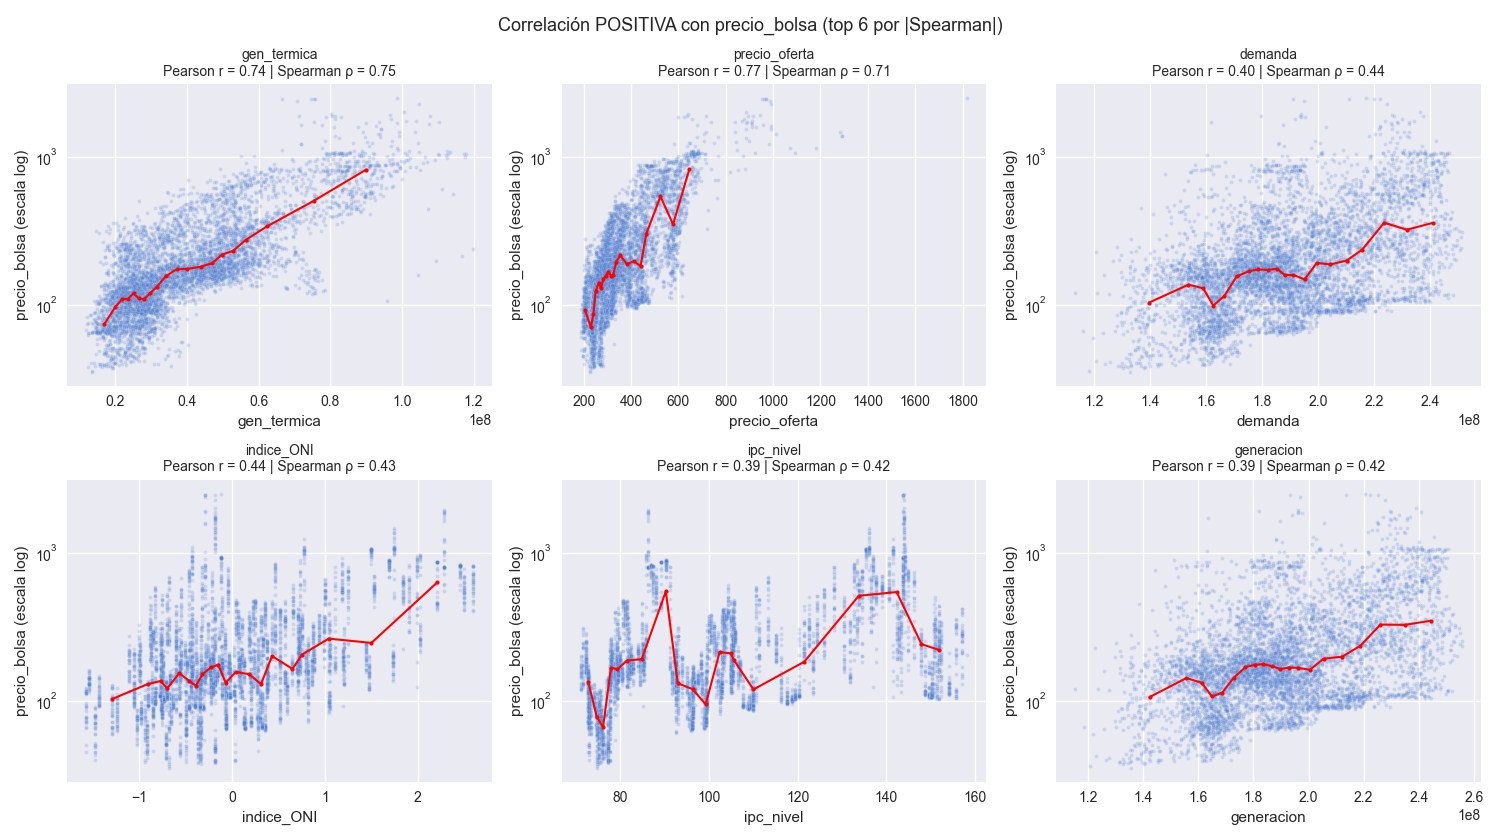

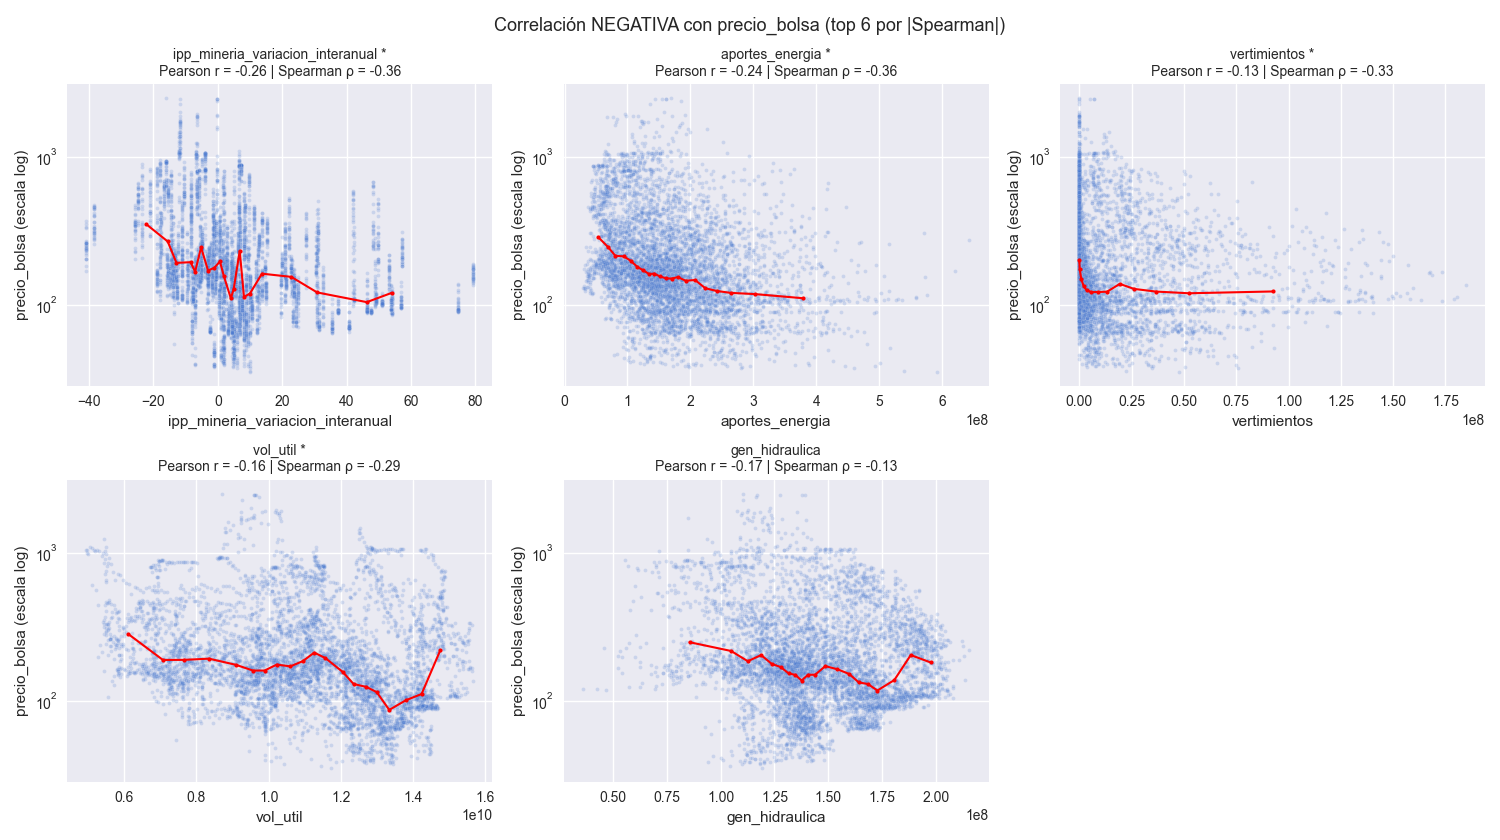

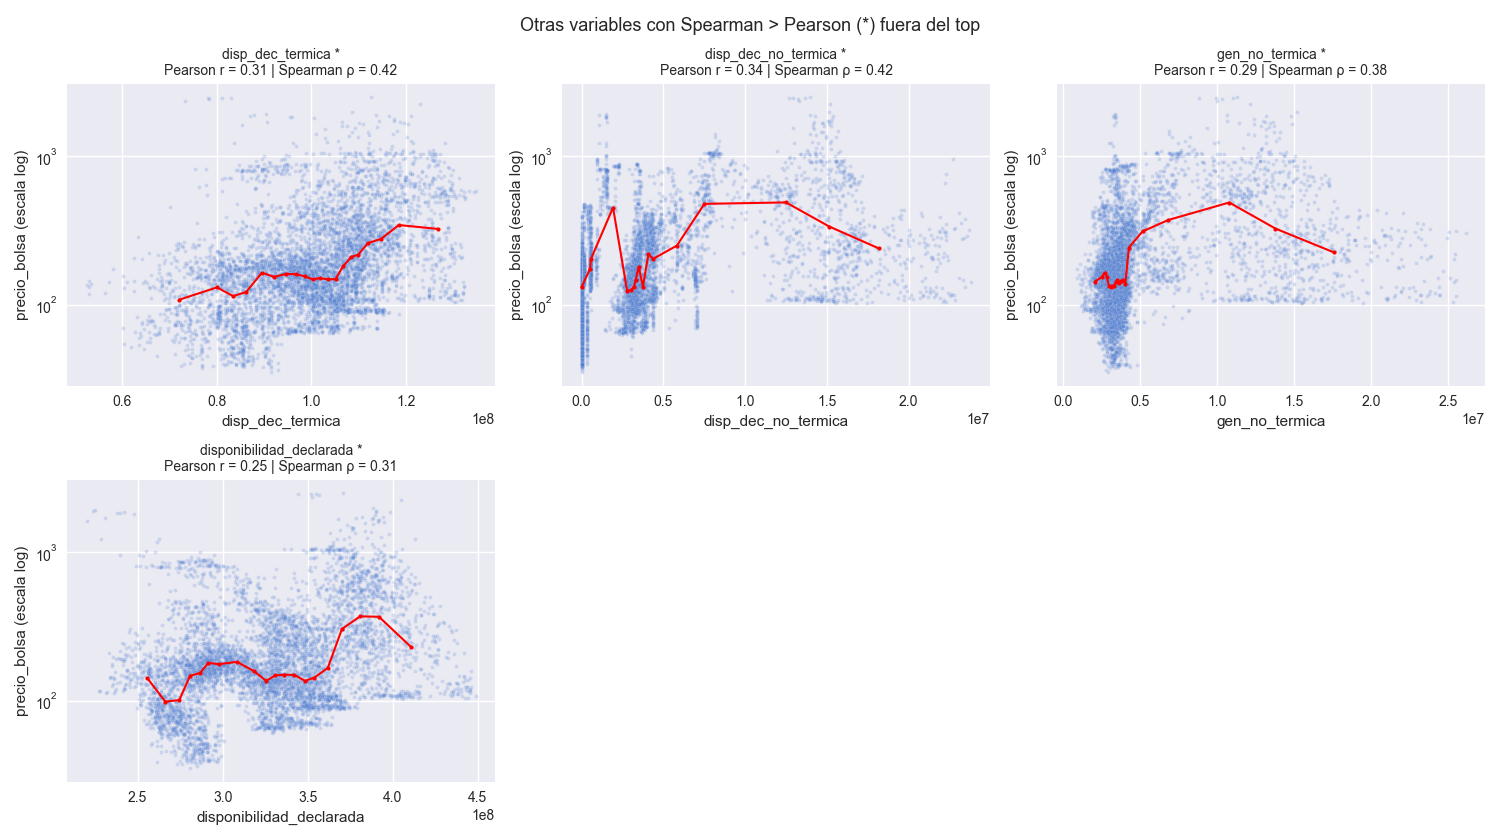

In [37]:
# ============================================================
# Dispersión de precio_bolsa contra las variables más correlacionadas
# (6 positivas + 6 negativas, por |Spearman|)
# ============================================================
# Un pairplot de todas las variables sería pesado de calcular y, sobre todo, poco útil
# aquí: lo que interesa para el modelado es la relación de cada variable CON EL TARGET,
# no todas las combinaciones entre variables explicativas entre sí (eso ya se cubre con
# la matriz de correlación de arriba). Por eso se hace un grid enfocado solo en
# precio_bolsa vs. las variables más relevantes.
#
# Decisiones de esta versión:
# - Se separan positivas y negativas: un top-N por |correlación| puede quedar compuesto
#   solo por variables positivas (pasaba con Pearson: la primera negativa,
#   disp_dec_hidraulica, quedaba 7.ª por 0.002) y dejar fuera todo el bloque hidrológico,
#   que es el que mueve el precio en sentido contrario.
# - Se ordena por |Spearman| en vez de |Pearson|: Spearman capta relaciones monótonas
#   no lineales, que son justamente las que la sección anterior identificó (*).
# - Eje Y en escala logarítmica: precio_bolsa es muy asimétrico (sección 2) y en escala
#   lineal la nube se aplasta contra el piso. Spearman no cambia con transformaciones
#   monótonas, así que el log no altera la relación que se está evaluando.
# - Línea roja: mediana de precio_bolsa por veintil (20 grupos) de la variable. Muestra la
#   FORMA de la relación (lineal, con umbral, saturada) mejor que la nube de puntos sola.
N_POR_SIGNO = 6


def graficar_dispersion(variables, titulo):
    n_cols = 3
    n_rows = int(np.ceil(len(variables) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.2 * n_rows), squeeze=False)
    for ax, columna in zip(axes.flat, variables):
        sns.scatterplot(data=df, x=columna, y="precio_bolsa", ax=ax, alpha=0.2, s=8)
        veintiles = pd.qcut(df[columna], q=20, duplicates="drop")
        perfil = df.groupby(veintiles, observed=True).agg(
            x=(columna, "median"), y=("precio_bolsa", "median")
        )
        ax.plot(perfil["x"], perfil["y"], color="red", marker="o", markersize=3, linewidth=1.5)
        ax.set_yscale("log")
        pearson, spearman, _ = comparacion_corr.loc[columna]
        marca = " *" if columna in marcadas else ""
        ax.set_title(f"{columna}{marca}\nPearson r = {pearson:.2f} | Spearman ρ = {spearman:.2f}", fontsize=10)
        ax.set_ylabel("precio_bolsa (escala log)")
    for ax in axes.flat[len(variables):]:
        ax.axis("off")
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


top_positivas = comparacion_corr.index[comparacion_corr["spearman"] > 0][:N_POR_SIGNO].tolist()
top_negativas = comparacion_corr.index[comparacion_corr["spearman"] < 0][:N_POR_SIGNO].tolist()

graficar_dispersion(top_positivas, "Correlación POSITIVA con precio_bolsa (top 6 por |Spearman|)")
graficar_dispersion(top_negativas, "Correlación NEGATIVA con precio_bolsa (top 6 por |Spearman|)")

# Variables marcadas (*) que no entraron en ninguno de los dos grids: se grafican aparte
# para que todas las candidatas a relación no lineal tengan su scatterplot.
marcadas_restantes = [v for v in marcadas if v not in top_positivas + top_negativas]
if marcadas_restantes:
    graficar_dispersion(marcadas_restantes, "Otras variables con Spearman > Pearson (*) fuera del top")

**Lectura de los scatterplots** (eje Y en escala log.

- `gen_termica` es la relación más limpia: **lineal en escala log** (cada aumento de la generación térmica multiplica el precio por un factor aproximadamente constante).
- `precio_oferta`: monótona y convexa, con una cola de días por encima de 800 COP/kWh que es la que infla su Pearson frente a Spearman.
- `demanda` y `generacion`: prácticamente el mismo gráfico (son casi la misma variable, ver sección 8), relación positiva pero difusa.
- `indice_ONI`: franjas verticales (el ONI es mensual) con la mediana subiendo sobre todo para ONI > 1 (El Niño moderado/fuerte): efecto de umbral más que lineal.
- `ipc_nivel`: la mediana zigzaguea (sube, baja, vuelve a subir).
- `aportes_energia`: la más clara del bloque hidrológico y con **umbral nítido**: el precio cae rápido mientras los aportes son bajos y se aplana a partir de ≈2×10⁸.
- `vertimientos`: casi el 40% de los días vale 0.
- `vol_util`: decrece en general, pero repunta en el extremo superior (embalses muy llenos coincidiendo con precios altos), algo que no tiene sentido físico y apunta a un efecto de época (la capacidad de embalse creció en los años recientes, que también tuvieron….
- `disp_dec_hidraulica` y `disponibilidad_declarada`: la nube se parte en **grupos separados** sobre el eje X, y el grupo de valores más bajos (≈60-70 mil) concentra los precios más altos.
- `ipp_mineria_variacion_interanual`: franjas verticales mensuales; la relación negativa refleja una coincidencia histórica (las caídas de precios mineros de 2015 y 2023 coincidieron con El Niño), no un mecanismo.

### Robustez de las correlaciones frente a la tendencia compartida

**Motivación** : los scatterplots muestran que varias correlaciones podrían ser **espurias**: dos series que crecen (o cambian de régimen) en la misma época aparecen correlacionadas aunque una no influya en la otra.

| Veredicto | Criterio |
|---|---|
| **Robusta** | \|ρ\| ≥ 0.25 tanto dentro del año como en cambios a 30 días |
| **Moderada** | sobrevive en al menos una de las dos, pero más débil |
| **Inconsistente** | dentro del año cambia de signo respecto al nivel |
| **Espuria** | \|ρ\| < 0.10 en ambas: desaparece al quitar la tendencia |

In [38]:
# ============================================================
# Robustez: ¿la correlación sobrevive al quitar la tendencia compartida?
# ============================================================
# Tres versiones de Spearman para cada variable:
# - nivel: la de la tabla anterior (valores originales, todo el período).
# - dentro del año: Spearman calculado por separado en cada año y luego promediado. Quita
#   el efecto de que dos series crezcan juntas a lo largo de los años (tendencia).
# - cambios a 30 días: Spearman entre el cambio mensual de la variable y el cambio
#   mensual de log(precio_bolsa). Pregunta "cuando la variable se mueve, ¿se mueve el
#   precio?", en vez de "¿están las dos altas en la misma época?".
# Si una correlación es fuerte en nivel pero se desvanece en las otras dos, es muy
# probablemente espuria (producto de la tendencia común, no de una relación real).
log_precio = np.log(df["precio_bolsa"])

filas = []
for variable in comparacion_corr.index:
    por_anio = [
        spearmanr(grupo[variable], grupo["precio_bolsa"]).correlation
        for _, grupo in df.groupby(df.index.year)
        if grupo[variable].nunique() > 5  # años en que la variable casi no cambia no aportan
    ]
    cambios = pd.concat([df[variable].diff(30), log_precio.diff(30)], axis=1).dropna()
    filas.append({
        "variable": variable,
        "spearman_nivel": comparacion_corr.loc[variable, "spearman"],
        "spearman_dentro_del_año": np.nanmean(por_anio),
        "spearman_cambios_30d": spearmanr(cambios.iloc[:, 0], cambios.iloc[:, 1]).correlation,
    })
robustez = pd.DataFrame(filas).set_index("variable")


def veredicto(fila):
    nivel, anual, cambios = fila
    if max(abs(anual), abs(cambios)) < 0.10:
        return "espuria (desaparece sin tendencia)"
    if abs(nivel) >= 0.10 and np.sign(anual) != np.sign(nivel):
        return "inconsistente (cambia de signo)"
    if abs(anual) >= 0.25 and abs(cambios) >= 0.25:
        return "robusta"
    return "moderada"


robustez["veredicto"] = robustez.apply(veredicto, axis=1)
display(robustez.round(2))

,spearman_nivel,spearman_dentro_del_año,spearman_cambios_30d,veredicto
variable,,,,
gen_termica,0.75,0.75,0.68,robusta
precio_oferta,0.71,0.55,0.58,robusta
demanda,0.44,0.19,0.21,moderada
indice_ONI,0.43,0.13,0.04,moderada
ipc_nivel,0.42,0.01,-0.00,espuria (desaparece sin tendencia)
generacion,0.42,0.16,0.19,moderada
disp_dec_termica,0.42,0.04,-0.11,moderada
disp_dec_no_termica,0.42,0.27,0.15,moderada
ipp_importados_nivel,0.42,-0.03,-0.04,espuria (desaparece sin tendencia)


- **Robustas — las que hay que priorizar**
- **El caso más llamativo es `gen_hidraulica`**
- **Espurias — todo el bloque macro**
- **`indice_ONI` es un caso aparte**
- **Moderadas** : `demanda` y `generacion` (≈0.2 sin tendencia, frente a 0.44 en nivel: parte de su correlación era tendencia), `gen_no_termica` (confirmando el efecto de época visto en el scatterplot), `vol_util` (en el límite de robusta) y `disp_dec_termica`/`disp_dec_no_termica`.

**Implicación para la selección de variables** : el ranking por correlación en nivel de la sección 7 **no debe usarse por sí solo** para elegir variables: sobrevalora el bloque macro y subvalora `gen_hidraulica`.

### La estructura de la correlación, ordenada por conglomerados

La matriz del comienzo de esta sección tiene las variables en orden alfabético.

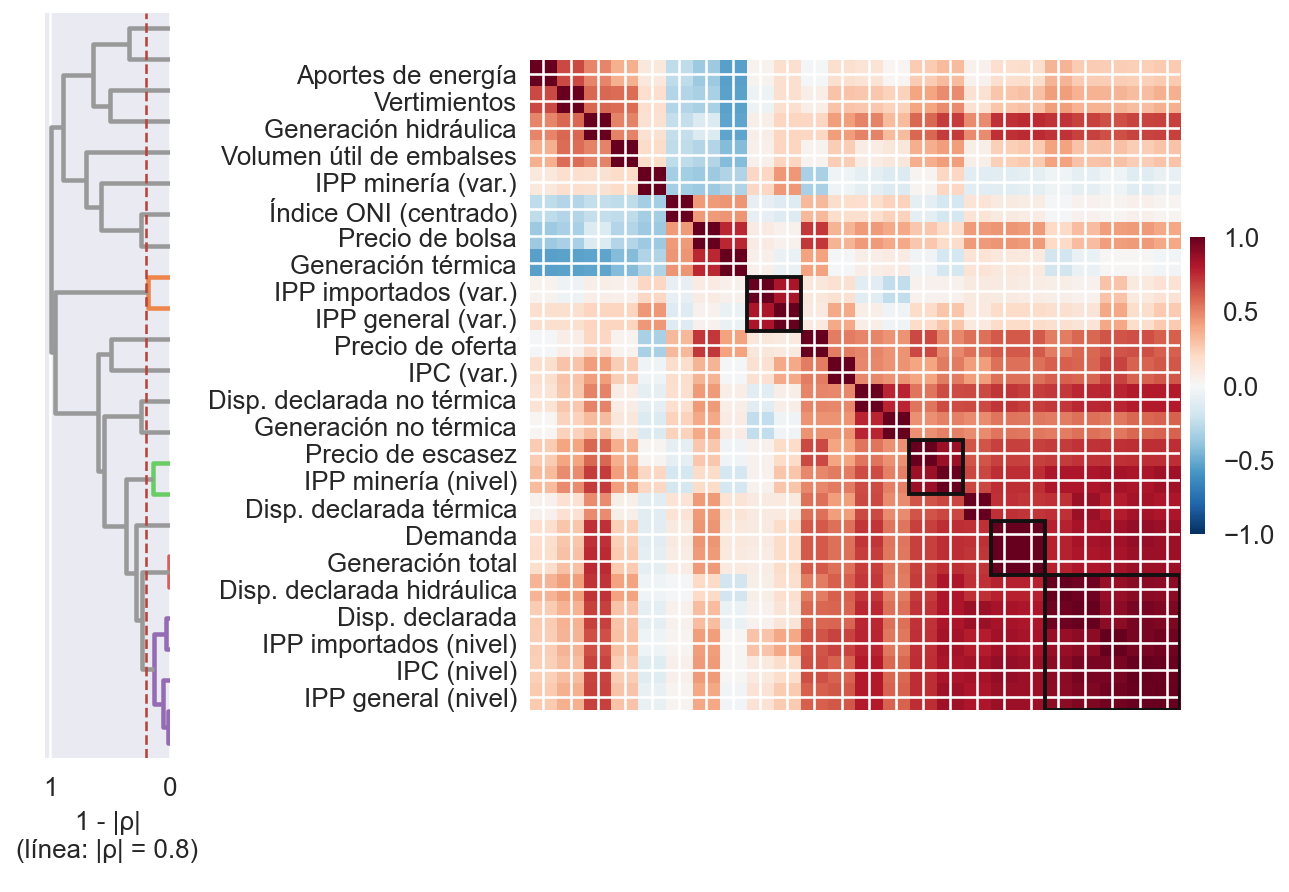

Bloques con |ρ| ≥ 0.8 entre TODOS sus pares: 4

  Bloque de 2 variables  |ρ| mínimo interno 0.8142  familias: Macroeconomía
      IPP importados (var. interanual)
      IPP general (var. interanual)

  Bloque de 2 variables  |ρ| mínimo interno 0.8608  familias: Macroeconomía, Precio
      Precio de escasez
      IPP minería (nivel)

  Bloque de 2 variables  |ρ| mínimo interno 0.9961  familias: Demanda, Generación
      Demanda
      Generación total

  Bloque de 5 variables  |ρ| mínimo interno 0.8676  familias: Disponibilidad, Macroeconomía
      Disp. declarada hidráulica
      Disponibilidad declarada
      IPP importados (nivel)
      IPC (nivel)
      IPP general (nivel)

Variables que no forman bloque con ninguna otra (13):
      Aportes de energía
      Vertimientos
      Generación hidráulica
      Volumen útil de embalses
      IPP minería (var. interanual)
      Índice ONI (centrado)
      Precio de bolsa
      Generación térmica
      Precio de oferta
      IPC (var. interanu

In [39]:
# ============================================================
# La misma matriz de correlación, reordenada por conglomerados
# ============================================================
# QUÉ CAMBIA RESPECTO DE LA MATRIZ DE 7.1 Y QUÉ NO. Los coeficientes son los mismos; cambian el
# orden de las filas y el que no se imprima el número en cada casilla. Las dos decisiones tienen
# el mismo motivo: con 28 variables hay 784 casillas, y una figura con 784 números dentro no se
# lee en una página. El color transmite la magnitud y el recuadro transmite la estructura, que es
# lo que hay que ver aquí; los coeficientes exactos están en la tabla de 7.2.
#
# POR QUÉ SPEARMAN. Varias de estas relaciones son monótonas pero no lineales (sección 7.3), de
# modo que Pearson subestima el parecido entre dos variables que miden lo mismo con una curvatura
# distinta, que es justo lo que este diagnóstico busca.
#
# POR QUÉ 1 - |rho| COMO DISTANCIA. Lo que agrupa aquí es la REDUNDANCIA, no el signo: dos
# variables con correlación -0,95 son tan intercambiables como dos con +0,95, porque cada una
# predice a la otra. El valor absoluto es lo que hace que la distancia signifique eso.
#
# POR QUÉ ENLACE COMPLETO Y CORTE EN 0,2, Y NO OTRA COSA. Con enlace promedio y corte en 0,5 el
# resultado era inservible: un solo grupo de catorce variables cuyo par más flojo compartía 0,32,
# es decir un bloque que no significaba nada. El enlace COMPLETO define la distancia entre dos
# grupos como la de su par más lejano, de modo que un grupo formado a distancia 0,2 GARANTIZA que
# TODOS sus pares internos tienen |rho| >= 0,8. Y 0,8 no es un número elegido aquí: es el mismo
# umbral con el que la sección 8 declara redundante un par de variables, de modo que los bloques
# de esta figura y los pares de aquella tabla hablan de lo mismo.
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

UMBRAL_RHO = 0.8
CORTE = 1 - UMBRAL_RHO
_sp = df_continuas.corr(method="spearman")
_d = 1 - _sp.abs()
np.fill_diagonal(_d.values, 0.0)
# squareform exige simetría exacta; la corrección numérica es del orden de 1e-16.
_d = (_d + _d.T) / 2
_enlace = linkage(squareform(_d.values, checks=False), method="complete")
_grupos = fcluster(_enlace, t=CORTE, criterion="distance")
_orden = dendrogram(_enlace, no_plot=True)["leaves"]
_vars_ord = [_sp.columns[i] for i in _orden]
_sp_ord = _sp.loc[_vars_ord, _vars_ord]

# MAQUETACIÓN. Las etiquetas van a la IZQUIERDA de la matriz, en el hueco que separa los dos
# paneles: puestas a la derecha, la barra de color se montaba encima. El hueco se dimensiona con
# wspace, que es relativo al ancho medio de los paneles, de modo que con la razón 1:5 queda
# holgado para los nombres más largos.
fig, (axd, axm) = plt.subplots(
    1, 2, figsize=(ANCHO_PX / PPP_PAGINA, 186 * 4.8 / PPP_PAGINA),
    gridspec_kw=dict(width_ratios=[0.85, 4.6], wspace=0.90))
# EL HUECO SE DIMENSIONA POR EL NOMBRE MAS LARGO, no a ojo: «Disp. declarada no termica»
# mide 26 caracteres, que al cuerpo del documento son casi dos pulgadas. Con menos hueco
# el rotulo invade el dendrograma, que es lo que hacia la version anterior.
# MARGENES PROPIOS, y no los del recorte automatico. Al quitar los nombres de las columnas
# ya no hay que reservar casi dos pulgadas y media por abajo, y ese sitio se lo queda la
# matriz. El de abajo solo tiene que dar cabida al rotulo del dendrograma, que son dos
# lineas.
fig.subplots_adjust(left=0.035, right=0.935, top=0.985, bottom=0.150)

dendrogram(_enlace, ax=axd, orientation="left", color_threshold=CORTE,
           above_threshold_color="#999", no_labels=True)
axd.axvline(CORTE, color="#b5453c", ls="--", lw=1.0)
axd.set_xlabel(f"1 - |ρ|\n(línea: |ρ| = {UMBRAL_RHO})", fontsize=10)
axd.tick_params(labelsize=10)
axd.invert_yaxis()
for lado in ("top", "right", "left"):
    axd.spines[lado].set_visible(False)

_im = axm.imshow(_sp_ord.values, cmap="RdBu_r", vmin=-1, vmax=1)
axm.set_xticks(range(len(_vars_ord)))
axm.set_yticks(range(len(_vars_ord)))
# LOS NOMBRES, ACORTADOS SOLO AQUI. «IPP importados (var. interanual)» mide 31 caracteres
# y no cabe en el hueco entre los dos paneles: se monta sobre el dendrograma. La forma
# corta dice lo mismo y cabe; en las demas figuras el nombre sigue entero.
_corto = {"(var. interanual)": "(var.)", "Disponibilidad": "Disp."}
_etq = [META.loc[c, "nombre"] if c in META.index else c for c in _vars_ord]
for _de, _a in _corto.items():
    _etq = [e.replace(_de, _a) for e in _etq]
# Y LAS COLUMNAS SE QUEDAN SIN NOMBRE: van en el mismo orden que las filas, de modo que
# escribirlos abajo es repetir los veintitres de la izquierda girados noventa grados.
axm.set_xticklabels([])
axm.set_yticklabels(_etq, fontsize=10)
axm.tick_params(axis="x", length=0)
axm.tick_params(axis="y", length=0, pad=5)

# Recuadro de cada grupo. Los grupos son contiguos en el orden del dendrograma, de modo que
# basta recorrer el orden y cerrar el rectángulo cuando cambia la etiqueta de grupo.
_g_ord = [_grupos[_sp.columns.get_loc(c)] for c in _vars_ord]
_ini = 0
for k in range(1, len(_g_ord) + 1):
    if k == len(_g_ord) or _g_ord[k] != _g_ord[_ini]:
        if k - _ini > 1:
            axm.add_patch(plt.Rectangle((_ini - 0.5, _ini - 0.5), k - _ini, k - _ini,
                                        fill=False, edgecolor="#111", lw=1.5))
        _ini = k
fig.colorbar(_im, ax=axm, fraction=0.022, pad=0.015).ax.tick_params(labelsize=10)
# Resolución de página, por el mismo motivo que en 6.4.
fig.set_dpi(PPP_PAGINA)
plt.show()

# ---- los grupos, nombrados
_tam = pd.Series(_g_ord).value_counts()
print(f"Bloques con |ρ| ≥ {UMBRAL_RHO} entre TODOS sus pares: {(_tam > 1).sum()}\n")
for g in dict.fromkeys(_g_ord):
    _miembros = [c for c, gg in zip(_vars_ord, _g_ord) if gg == g]
    if len(_miembros) == 1:
        continue
    _sub = _sp.loc[_miembros, _miembros].abs()
    _min = _sub.where(~np.eye(len(_miembros), dtype=bool)).min().min()
    # El bloque solo vale si su garantía se cumple: si esto fallara, el enlace o el corte no
    # serían los que la figura dice que son.
    assert _min >= UMBRAL_RHO - 1e-9, f"bloque con |ρ| interno {_min:.3f}"
    _fams = sorted({META.loc[c, "familia"] for c in _miembros if c in META.index})
    # Cuatro decimales y no dos: hay un par cuyo |rho| redondea a 1,00 sin serlo, y escribirlo
    # como 1,00 haría pensar en un error de cálculo o en una columna duplicada.
    print(f"  Bloque de {len(_miembros)} variables  |ρ| mínimo interno {_min:.4f}  "
          f"familias: {', '.join(_fams)}")
    for c in _miembros:
        print(f"      {META.loc[c, 'nombre'] if c in META.index else c}")
    print()
_sueltas = [c for c, gg in zip(_vars_ord, _g_ord) if _tam[gg] == 1]
print(f"Variables que no forman bloque con ninguna otra ({len(_sueltas)}):")
for c in _sueltas:
    print(f"      {META.loc[c, 'nombre'] if c in META.index else c}")
print()
_en_bloque = len(_vars_ord) - len(_sueltas)
print(f"Lectura. {_en_bloque} de las {len(_vars_ord)} series continuas de la matriz "
      f"({len(_vars_ord) - 1} explicativas y el propio")
print("precio de bolsa) pertenecen a algún bloque de redundancia, y los bloques no son un")
print("artefacto del método: cada uno reúne variables que miden el mismo fenómeno por vías")
print("distintas. Es la razón por la que la sección 8 encuentra multicolinealidad severa. Un")
print("modelo lineal no puede repartir el efecto entre variables que se mueven juntas, y de ahí")
print("que la selección conserve un representante por bloque en vez de todas.")


## 8. Multicolinealidad entre variables explicativas

Se identifican pares de variables explicativas con correlación absoluta mayor a 0.8 (posible redundancia), complementado con el **Factor de Inflación de Varianza (VIF)**: a diferencia de la correlación por pares, el VIF de una variable mide qué tan bien se puede explicar….

In [40]:
# ============================================================
# Pares de variables explicativas con |correlación| > 0.8
# ============================================================
explicativas = df_continuas.drop(columns=["precio_bolsa"])
corr_explicativas = explicativas.corr().abs()

# Solo el triángulo superior (sin la diagonal) para no repetir cada par dos veces
# ni contar la correlación de una variable consigo misma.
mascara_superior = np.triu(np.ones(corr_explicativas.shape), k=1).astype(bool)
pares_altos = (
    corr_explicativas.where(mascara_superior)
    .stack()
    .reset_index()
    .rename(columns={"level_0": "variable_1", "level_1": "variable_2", 0: "correlacion_abs"})
)
pares_altos = pares_altos[pares_altos["correlacion_abs"] > 0.8].sort_values(
    "correlacion_abs", ascending=False
)

print(f"Pares de variables explicativas con correlación absoluta > 0.8: {len(pares_altos)}")
pares_altos.reset_index(drop=True)

Pares de variables explicativas con correlación absoluta > 0.8: 30


,variable_1,variable_2,correlacion_abs
0,demanda,generacion,0.996746
1,ipc_nivel,ipp_general_nivel,0.976331
2,ipp_importados_nivel,ipp_general_nivel,0.969654
3,disp_dec_hidraulica,disponibilidad_declarada,0.968123
4,precio_escasez,ipp_mineria_nivel,0.946591
5,disp_dec_no_termica,gen_no_termica,0.937718
6,ipc_nivel,ipp_importados_nivel,0.931367
7,disponibilidad_declarada,ipc_nivel,0.924228
8,ipp_mineria_nivel,ipp_importados_nivel,0.911552
9,ipp_mineria_nivel,ipp_general_nivel,0.905832


In [41]:
# ============================================================
# Factor de Inflación de Varianza (VIF) por variable explicativa
# ============================================================
# VIF > 10 se toma como umbral convencional de multicolinealidad severa (algunas
# referencias usan 5; se reportan ambos umbrales para no forzar una única lectura).
# variance_inflation_factor necesita una columna de 1's (intercepto) para calcularse
# correctamente sobre el resto de columnas.
X = explicativas.copy()
X.insert(0, "const", 1.0)

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
vif = vif[vif["variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)

print(f"Variables con VIF > 10 (multicolinealidad severa): {(vif['VIF'] > 10).sum()}")
print(f"Variables con VIF > 5 (multicolinealidad moderada): {(vif['VIF'] > 5).sum()}")
vif

C:\Users\Windows 10 Pro\miniconda3\envs\tesis_xm\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Variables con VIF > 10 (multicolinealidad severa): 16
Variables con VIF > 5 (multicolinealidad moderada): 19


,variable,VIF
0,disp_dec_no_termica,inf
1,disp_dec_termica,inf
2,disponibilidad_declarada,inf
3,gen_hidraulica,inf
4,gen_no_termica,inf
5,gen_termica,inf
6,generacion,inf
7,disp_dec_hidraulica,inf
8,ipp_general_nivel,389.219750
9,demanda,260.692169


**Sobre las variables con VIF infinito.** No es un error de cálculo: es un hallazgo estructural, y alcanza a **dos familias de variables**.

### Las identidades exactas, y por qué no hay más que dos

Un VIF infinito significa que la variable es una **combinación lineal exacta** de las demás: la regresión auxiliar la reproduce sin error, su $R^2$ es exactamente 1 y el VIF, que vale $1/(1-R^2)$, se divide por cero.

In [42]:
# ============================================================
# Las dos identidades exactas, comprobadas, y el rango de la matriz
# ============================================================
# EL ARGUMENTO. Si una matriz de n columnas tiene rango n - k, entonces hay exactamente k
# dependencias lineales exactas entre sus columnas. Comprobar el rango y comprobar las dos
# identidades candidatas es lo que permite afirmar que no hay ninguna otra: si las identidades
# fueran tres y solo se hubieran encontrado dos, el rango no cuadraría.
IDENTIDADES = [
    ("generacion", ["gen_hidraulica", "gen_termica", "gen_no_termica"]),
    ("disponibilidad_declarada",
     ["disp_dec_hidraulica", "disp_dec_termica", "disp_dec_no_termica"]),
]

print("Identidades exactas dentro del conjunto de variables explicativas:\n")
_confirmadas = 0
for agregado, componentes in IDENTIDADES:
    _suma = explicativas[componentes].sum(axis=1)
    _err = (explicativas[agregado] - _suma).abs()
    # La tolerancia es la del coma flotante sobre magnitudes del orden de 1e8, no un umbral
    # elegido: se compara el error contra el épsilon de la máquina escalado al nivel de la serie.
    _tol = np.finfo(float).eps * explicativas[agregado].abs().max() * 16
    _ok = bool(_err.max() <= _tol)
    _confirmadas += _ok
    print(f"  {META.loc[agregado, 'nombre']} = " +
          " + ".join(META.loc[c, "nombre"] for c in componentes))
    print(f"      error absoluto máximo {_err.max():.3g}  (tolerancia {_tol:.3g})  "
          f"{'EXACTA' if _ok else 'NO SE CUMPLE'}")
    print(f"      error relativo máximo {(_err / explicativas[agregado].abs()).max():.2e}\n")
assert _confirmadas == len(IDENTIDADES), "alguna identidad declarada no se cumple"

# Rango numérico de la matriz de explicativas. El déficit de rango tiene que ser exactamente el
# número de identidades encontradas; si fuera mayor, faltaría alguna por identificar.
_n_col = explicativas.shape[1]
_rango = np.linalg.matrix_rank(explicativas.values)
_deficit = _n_col - _rango
print(f"Matriz de variables explicativas: {_n_col} columnas, rango numérico {_rango}, "
      f"déficit {_deficit}.")
assert _deficit == len(IDENTIDADES), (
    f"el déficit de rango es {_deficit} y se declararon {len(IDENTIDADES)} identidades: "
    "hay dependencias lineales sin identificar")
print(f"El déficit coincide con las {len(IDENTIDADES)} identidades comprobadas, de modo que no hay")
print("ninguna otra dependencia lineal exacta en el conjunto.\n")

# Las ocho variables implicadas son exactamente las que el VIF da por infinitas.
_implicadas = sorted({v for a, cs in IDENTIDADES for v in [a] + cs})
_vif_inf = sorted(vif.loc[~np.isfinite(vif["VIF"]), "variable"])
print(f"Variables implicadas en alguna identidad: {len(_implicadas)}")
print(f"Variables con VIF infinito:               {len(_vif_inf)}")
assert _implicadas == _vif_inf, (
    f"no son el mismo conjunto:\n  identidades: {_implicadas}\n  VIF infinito: {_vif_inf}")
print("Son el MISMO conjunto, lo que cierra el argumento: el VIF infinito de esas ocho variables")
print("es aritmético y no estadístico.\n")

_resto = vif[np.isfinite(vif["VIF"])].sort_values("VIF", ascending=False)
print("Entre las variables que no participan en ninguna identidad, el VIF más alto es:\n")
for _, r in _resto.head(6).iterrows():
    _n = META.loc[r["variable"], "nombre"] if r["variable"] in META.index else r["variable"]
    print(f"  {_n:<34} {r['VIF']:>10.1f}")
print()
print("Consecuencia para la selección de variables. De cada identidad sobra una variable por pura")
print("álgebra, y eliminarla no pierde ninguna información: el agregado se recupera sumando sus")
print("componentes. Lo que decide cuál se retira no es el VIF, que es infinito para las cuatro de")
print("cada grupo por igual, sino qué representación es más útil para el modelo, y eso se resuelve")
print("en 4_SeleccionVariables.ipynb con la importancia por permutación.")


Identidades exactas dentro del conjunto de variables explicativas:

  Generación total = Generación hidráulica + Generación térmica + Generación no térmica
      error absoluto máximo 5.96e-08  (tolerancia 9.08e-07)  EXACTA
      error relativo máximo 3.59e-16

  Disponibilidad declarada = Disp. declarada hidráulica + Disp. declarada térmica + Disp. declarada no térmica
      error absoluto máximo 0  (tolerancia 1.59e-06)  EXACTA
      error relativo máximo 0.00e+00

Matriz de variables explicativas: 23 columnas, rango numérico 21, déficit 2.
El déficit coincide con las 2 identidades comprobadas, de modo que no hay
ninguna otra dependencia lineal exacta en el conjunto.

Variables implicadas en alguna identidad: 8
Variables con VIF infinito:               8
Son el MISMO conjunto, lo que cierra el argumento: el VIF infinito de esas ocho variables
es aritmético y no estadístico.

Entre las variables que no participan en ninguna identidad, el VIF más alto es:

  IPP general (nivel)        

## 9. Conclusiones

_(Todas las cifras salen de ejecutar este notebook sobre `2_dataset_procesado.csv`.

### Sobre la variable objetivo

- **Distribución con cola derecha muy larga.**
- **Los extremos no son anomalías.**

### Sobre la estructura temporal

- **ADF y KPSS se contradicen, y hay que creerle a KPSS.**
- **Un AR(1) casi integrado.**
- **Estacionalidad semanal fuerte; anual débil.**
- **La serie se comporta de forma multiplicativa.**

### Sobre el calendario y el clima

- **El ciclo anual es hidrológico y modesto.**
- **La fase ENSO sí discrimina, y con fuerza.**
- **El día de la semana importa, pero solo se ve en los cambios.**

### Sobre las variables explicativas

- **Las más correlacionadas no son las más útiles.**
- **Ocho variables tienen |Spearman| mayor que |Pearson|**
- **Redundancia estructural en dos familias.**
- **El bloque hidroclimático es el que lleva señal propia.**

### Dos cosas que este EDA **no** decide

- **No selecciona variables.**
- **No fija la codificación de las variables de calendario.**

## 10. Para qué sirve cada resultado de este notebook

Un análisis exploratorio es «estrictamente necesario» cuando **cada resultado tiene un consumidor**: una decisión de modelado que se apoya en él o una sección del documento que lo cita.

| Sección | Resultado | Dónde se usa |
|---|---|---|
| 0 | Imputación de los 3 huecos | Produce `2_dataset_procesado.csv`, **la entrada de `4_SeleccionVariables.ipynb`**. Sin esta sección se rompe la cadena. |
| 1 | Integridad: sin nulos, sin duplicados, diaria continua | Precondición de la descomposición, del ACF y de todo el modelado de series. |
| 2 | Asimetría y curtosis | Justifica la **pérdida absoluta** del XGBoost (notebook 6) y el logaritmo del SARIMAX. |
| 3 | ADF frente a KPSS | Documento y notebook 5: justifica **evaluar `d = 1`** en vez de fijar `d = 0`. |
| 3 | Descomposición y perfil anual robusto | Justifica **no usar `s = 365`** y usar el logaritmo (comportamiento multiplicativo). |
| 3.4 | Dispersión frente a nivel (corr. 0,81) | Justifica el **logaritmo**; y el coeficiente de variación por fase obliga a reportar el **error relativo** al segmentar. |
| 4 | ACF y PACF en nivel y diferenciada | Notebook 5: los órdenes del SARIMAX **(2,1,1)(1,0,0,7)**. |
| 4 | Estacionalidad semanal sobre la diferencia | Notebook 5: el componente **`s = 7`**. |
| 5 | Diagramas de cajas por mes, día y tipo de día | Candidatas de calendario que entran a la selección. |
| 5 | **Diagramas de cajas por fase ENSO** | Documento: el respaldo empírico de la **evaluación segmentada por fase**, que es un compromiso del trabajo. |
| 5 bis | ONI centrado frente a publicado | Justifica que el modelado use la versión **publicada**: sin ella habría fuga de información. |
| 6 | Panorama de las series explicativas | Inspección visual previa; detecta quiebres y cambios de unidad. |
| 7 | Pearson, Spearman y dispersión | Muestra que la relación con la hidrología es **monótona no lineal**. |
| 7 | Prueba de robustez sin tendencia | Documento §Metodología: **por qué el ranking de correlación no sirve como criterio de selección**, que es el argumento de fondo para usar importancia por permutación. |
| 8 | Pares con \|r\| > 0,8 y VIF | Notebook 4: justifica la **poda por VIF** antes de medir importancia. |
| 1.1 | **Tipología y procedencia de cada variable** | Documento §Comprensión de los datos: la tabla de variables, su unidad, su fuente y su escala de medición. Justifica que el calendario quede fuera de la correlación y del VIF. |
| 6.4 | **Distribución de cada variable explicativa** | Documento §Análisis univariado: la forma de cada predictora. La asimetría decide qué entra transformado y los ceros estructurales, qué necesita un indicador binario. |
| 7 | **Correlación reordenada por conglomerados** | Documento §Análisis multivariado: muestra los bloques de redundancia y es el diagnóstico que explica la multicolinealidad de la sección 8. |
| 8 | **Identidades exactas y rango de la matriz** | Notebook 4 y documento: demuestra que los ocho VIF infinitos son aritméticos, y que no hay otras dependencias lineales. |